# EDA — Risco Térmico em Tratores Agrícolas

## Visão geral do projeto

Este notebook inicia a construção de uma análise exploratória de dados (EDA) voltada ao **comportamento térmico e operacional de tratores agrícolas**.

O objetivo do projeto **não é assumir que temperatura alta significa incêndio**. Nesta fase, queremos primeiro compreender como o motor se comporta em operação real e quais variáveis ajudam a explicar mudanças térmicas.

A análise será feita de forma rastreável e documentada, utilizando três bases de dados agrícolas públicas:

1. **Tümosan 81.110 Powershuttle** — telemetria CAN/J1939 em operações reais de preparo do solo;
2. **Fendt — Agricultural Load Cycles** — telemetria de múltiplos tratores em operações agrícolas reais;
3. **New Holland T7.165 S** — telemetria GNSS + CAN-Bus, incluindo versões com anomalias injetadas para estudos de manutenção preditiva.

> **Regra metodológica:** as três bases não serão misturadas linha a linha. Cada uma será analisada separadamente, respeitando sua origem, frequência de coleta, sensores e contexto operacional.

# Passo 1 — Definição do problema e objetivo analítico

## 1.1 Problema central

O superaquecimento de um trator não deve ser analisado usando apenas um valor isolado de temperatura.

O estado térmico do motor depende do contexto operacional, incluindo fatores como:

- temperatura do líquido de arrefecimento;
- temperatura ambiente;
- rotação do motor (RPM);
- torque;
- carga do motor;
- pressão e/ou temperatura do óleo;
- velocidade do trator;
- consumo de combustível;
- tempo de operação;
- comportamento dessas variáveis ao longo do tempo.

Portanto, o motor será tratado como um **sistema multivariável e temporal**.

## 1.2 Pergunta principal do EDA

> **Quais condições operacionais estão associadas às variações de temperatura do motor e quais sinais podem ajudar a antecipar um comportamento térmico anormal?**

## 1.3 O que o EDA deverá comprovar

Antes de qualquer treinamento de Machine Learning, o EDA deverá demonstrar:

1. de onde os dados vieram;
2. quais sensores e variáveis estão realmente disponíveis;
3. como cada variável é medida;
4. qual é a qualidade dos dados;
5. como o motor se comporta em condições normais;
6. como temperatura, RPM, torque, carga, velocidade, ambiente e óleo se relacionam;
7. se existe informação temporal suficiente para construir variáveis preditivas.

## 1.4 O que NÃO será feito nesta etapa

Nesta fase:

- não será treinado nenhum modelo de ML;
- não será criado um rótulo artificial de “incêndio”;
- não será definido um limite universal de temperatura;
- não serão misturados registros de tratores diferentes sem justificativa;
- correlação não será interpretada automaticamente como causalidade.

## 1.5 Objetivo futuro do Machine Learning

Após o EDA e o feature engineering, o projeto poderá testar duas frentes:

**A. Previsão térmica**

Prever, por exemplo, a temperatura máxima do motor nos próximos 5, 10 ou 15 minutos.

**B. Detecção de anomalias**

Identificar quando o comportamento atual do trator se afasta do padrão operacional aprendido.

Dessa forma, o sistema pode apoiar alertas preventivos de risco térmico sem afirmar que existe um incêndio quando a base não fornece esse rótulo.

# Passo 2 — Origem, função e confiabilidade das bases

O projeto utiliza três fontes diferentes porque cada base cumpre uma função metodológica específica.

## 2.1 Base 1 — Tümosan 81.110 Powershuttle

- **Fonte:** Mendeley Data
- **Dataset:** *TUMOSAN 81.110 POWERSHUTTLE SOIL TILLAGE OPERATIONS KONYA/TURKEY*
- **Versão:** 2
- **DOI:** `10.17632/bbjtjrsxvx.2`
- **Equipamento:** trator agrícola Tümosan 81.110 P
- **Contexto:** operações reais de preparo do solo em Konya, Turquia
- **Coleta:** CAN-Bus com decodificação J1939
- **Frequência nominal:** 10 Hz
- **Estrutura publicada:** 10 arquivos tabulados
- **Volume informado:** aproximadamente 24,7 horas e 889.255 amostras
- **Sinais informados:** rotação, torque, consumo de combustível, parâmetros de coolant e óleo, velocidade, hitch/draft, PTO, transfer case e temperaturas do sistema de pós-tratamento
- **Papel no projeto:** **base principal para análise detalhada de comportamento térmico em alta carga**

Fonte oficial:  
https://data.mendeley.com/datasets/bbjtjrsxvx/2

---

## 2.2 Base 2 — Fendt / Agricultural Load Cycles

- **Fonte:** Zenodo / Technical University of Munich
- **Dataset:** *Agricultural Load Cycles: Tractor Mission Profiles From Recorded GNSS and CAN Bus Data*
- **DOI:** `10.5281/zenodo.14619787`
- **Equipamentos:** cinco tratores agrícolas, com potência entre 77 e 240 kW
- **Período:** aproximadamente um ano de coleta
- **Coleta:** GNSS + CAN-Bus J1939 + ISOBUS
- **Volume informado:** 1.245 horas de operação
- **Conteúdo:** parâmetros de motor/carga, energia auxiliar e informações GNSS em diferentes trabalhos agrícolas
- **Papel no projeto:** **comparação e validação do comportamento operacional em outros tratores e implementos**

Fonte oficial:  
https://zenodo.org/records/14619787

---

## 2.3 Base 3 — New Holland T7.165 S

- **Fonte:** GitHub — repositório público dos autores
- **Dataset:** *GNSS-CAN Farm Tractor Operations Dataset*
- **Equipamento:** New Holland T7.165 S
- **Coleta:** GNSS + CAN-Bus
- **Frequência:** 1 Hz
- **Sessão 1:** 17.447 observações
- **Sessão 2:** 11.795 observações
- **Estados operacionais:** `Working`, `Turning`, `Moving`, `Idle`
- **Conteúdo adicional:** versões da segunda sessão com anomalias injetadas
- **Papel no projeto:** **teste de detecção de anomalias e manutenção preditiva**

**Atenção:** os dados operacionais são reais, mas as variantes de falha presentes em `anomalous_datasets/` contêm anomalias artificialmente injetadas. Elas deverão ser identificadas como sintéticas na documentação e não tratadas como sinistros reais.

Fonte oficial:  
https://github.com/lindiap/tractor-field-operations-dataset

---

## 2.4 Critérios de confiabilidade

Para cada base, serão verificados:

- origem pública e rastreável;
- documentação da coleta;
- modelo/equipamento;
- sensores disponíveis;
- unidade de cada variável;
- frequência de aquisição;
- quantidade de registros;
- valores ausentes;
- duplicatas;
- valores fisicamente inconsistentes;
- continuidade temporal;
- diferenças entre sessões/campos;
- existência ou não de rótulos reais de falha.

## 2.5 Regra para seleção das variáveis

Uma variável só será utilizada no modelo se conseguirmos responder:

1. **O que ela representa?**
2. **Como ela é medida no trator?**
3. **Qual unidade utiliza?**
4. **Qual hipótese justifica sua relação com o comportamento térmico?**
5. **Ela está realmente disponível no dataset?**

# Passo 3 — Preparação do ambiente e inspeção inicial dos arquivos

Nesta etapa ainda não haverá limpeza, remoção de colunas ou modelagem.

O objetivo é:

1. configurar o ambiente;
2. localizar as três bases;
3. criar um inventário dos arquivos disponíveis;
4. validar a estrutura do Tümosan;
5. ler a documentação oficial incluída na base;
6. carregar somente o primeiro arquivo do Tümosan para inspeção estrutural.

> **Importante:** o carregamento inicial não representa tratamento dos dados. Ele serve apenas para entender a estrutura real da base.

In [ ]:
# Bibliotecas usadas até o Passo 3

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

In [ ]:
# Localiza a raiz do projeto de forma simples e robusta

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW = PROJECT_ROOT / "data" / "raw"

FENDT_PATH = DATA_RAW / "fendt"
NEW_HOLLAND_PATH = DATA_RAW / "new_holland"
TUMOSAN_PATH = DATA_RAW / "tumosan"

print(f"Raiz do projeto: {PROJECT_ROOT.resolve()}")
print(f"Data raw:        {DATA_RAW.resolve()}")
print()

for nome, caminho in {
    "Fendt": FENDT_PATH,
    "New Holland": NEW_HOLLAND_PATH,
    "Tümosan": TUMOSAN_PATH,
}.items():
    status = "OK" if caminho.exists() else "NÃO ENCONTRADO"
    print(f"{nome:<12} -> {status:<14} | {caminho}")

Raiz do projeto: /home/debianjv/Documentos/maia-intelligence-NEXT/machine_learning
Data raw:        /home/debianjv/Documentos/maia-intelligence-NEXT/machine_learning/data/raw

Fendt        -> OK             | /home/debianjv/Documentos/maia-intelligence-NEXT/machine_learning/data/raw/fendt
New Holland  -> OK             | /home/debianjv/Documentos/maia-intelligence-NEXT/machine_learning/data/raw/new_holland
Tümosan      -> OK             | /home/debianjv/Documentos/maia-intelligence-NEXT/machine_learning/data/raw/tumosan


## 3.2 Inventário das três bases

Antes de abrir qualquer arquivo, criaremos um inventário com:

- nome;
- extensão;
- tamanho;
- caminho relativo.

Isso documenta exatamente quais arquivos estavam disponíveis no momento da análise.

In [4]:
def inventariar_pasta(pasta: Path) -> pd.DataFrame:
    # Retorna um inventário dos arquivos presentes em uma pasta e subpastas.
    if not pasta.exists():
        return pd.DataFrame(
            columns=["arquivo", "extensao", "tamanho_mb", "caminho"]
        )

    arquivos = [p for p in pasta.rglob("*") if p.is_file()]

    registros = []
    for arquivo in arquivos:
        registros.append({
            "arquivo": arquivo.name,
            "extensao": arquivo.suffix.lower(),
            "tamanho_mb": arquivo.stat().st_size / (1024 ** 2),
            "caminho": str(arquivo.relative_to(PROJECT_ROOT)),
        })

    return (
        pd.DataFrame(registros)
        .sort_values(["extensao", "arquivo"])
        .reset_index(drop=True)
    )


inventario_fendt = inventariar_pasta(FENDT_PATH)
inventario_new_holland = inventariar_pasta(NEW_HOLLAND_PATH)
inventario_tumosan = inventariar_pasta(TUMOSAN_PATH)

resumo_arquivos = pd.DataFrame({
    "base": ["Fendt", "New Holland", "Tümosan"],
    "quantidade_arquivos": [
        len(inventario_fendt),
        len(inventario_new_holland),
        len(inventario_tumosan),
    ],
    "tamanho_total_mb": [
        inventario_fendt["tamanho_mb"].sum() if not inventario_fendt.empty else 0,
        inventario_new_holland["tamanho_mb"].sum() if not inventario_new_holland.empty else 0,
        inventario_tumosan["tamanho_mb"].sum() if not inventario_tumosan.empty else 0,
    ],
})

resumo_arquivos

,base,quantidade_arquivos,tamanho_total_mb
0,Fendt,9,610.39
1,New Holland,15,41.69
2,Tümosan,11,50.82


## 3.3 Inventário específico do Tümosan

O Tümosan será a primeira base analisada em profundidade porque contém:

- operação agrícola real;
- segmentos de alta carga;
- frequência nominal de 10 Hz;
- variáveis diretamente relacionadas ao motor;
- parâmetros de arrefecimento e óleo.

A inspeção abaixo apenas lista os arquivos. Nenhuma sessão será concatenada ainda.

In [5]:
inventario_tumosan

,arquivo,extensao,tamanho_mb,caminho
0,FIELD_10_TUMOSAN_81110P_TILLAGE_OP_RAW.tab,.tab,5.35,data/raw/tumosan/FIELD_FILES/FIELD_10_TUMOSAN_...
1,FIELD_1_TUMOSAN_81110P_TILLAGE_OP_RAW.tab,.tab,2.57,data/raw/tumosan/FIELD_FILES/FIELD_1_TUMOSAN_8...
2,FIELD_2_TUMOSAN_81110P_TILLAGE_OP_RAW.tab,.tab,7.62,data/raw/tumosan/FIELD_FILES/FIELD_2_TUMOSAN_8...
3,FIELD_3_TUMOSAN_81110P_TILLAGE_OP_RAW.tab,.tab,2.89,data/raw/tumosan/FIELD_FILES/FIELD_3_TUMOSAN_8...
4,FIELD_4_TUMOSAN_81110P_TILLAGE_OP_RAW.tab,.tab,4.14,data/raw/tumosan/FIELD_FILES/FIELD_4_TUMOSAN_8...
5,FIELD_5_TUMOSAN_81110P_TILLAGE_OP_RAW.tab,.tab,7.85,data/raw/tumosan/FIELD_FILES/FIELD_5_TUMOSAN_8...
6,FIELD_6_TUMOSAN_81110P_TILLAGE_OP_RAW.tab,.tab,2.99,data/raw/tumosan/FIELD_FILES/FIELD_6_TUMOSAN_8...
7,FIELD_7_TUMOSAN_81110P_TILLAGE_OP_RAW.tab,.tab,3.79,data/raw/tumosan/FIELD_FILES/FIELD_7_TUMOSAN_8...
8,FIELD_8_TUMOSAN_81110P_TILLAGE_OP_RAW.tab,.tab,10.86,data/raw/tumosan/FIELD_FILES/FIELD_8_TUMOSAN_8...
9,FIELD_9_TUMOSAN_81110P_TILLAGE_OP_RAW.tab,.tab,2.75,data/raw/tumosan/FIELD_FILES/FIELD_9_TUMOSAN_8...


In [6]:
# Valida quantos arquivos .tab foram encontrados e os organiza por FIELD

arquivos_tumosan_tab = list(TUMOSAN_PATH.rglob("*.tab"))

def numero_field(arquivo: Path) -> int:
    match = re.search(r"FIELD_(\d+)", arquivo.name, flags=re.IGNORECASE)
    return int(match.group(1)) if match else 999

arquivos_tumosan_tab = sorted(
    arquivos_tumosan_tab,
    key=numero_field
)

print(f"Arquivos .tab encontrados: {len(arquivos_tumosan_tab)}")
print()

for arquivo in arquivos_tumosan_tab:
    print(arquivo.name)

Arquivos .tab encontrados: 10

FIELD_1_TUMOSAN_81110P_TILLAGE_OP_RAW.tab
FIELD_2_TUMOSAN_81110P_TILLAGE_OP_RAW.tab
FIELD_3_TUMOSAN_81110P_TILLAGE_OP_RAW.tab
FIELD_4_TUMOSAN_81110P_TILLAGE_OP_RAW.tab
FIELD_5_TUMOSAN_81110P_TILLAGE_OP_RAW.tab
FIELD_6_TUMOSAN_81110P_TILLAGE_OP_RAW.tab
FIELD_7_TUMOSAN_81110P_TILLAGE_OP_RAW.tab
FIELD_8_TUMOSAN_81110P_TILLAGE_OP_RAW.tab
FIELD_9_TUMOSAN_81110P_TILLAGE_OP_RAW.tab
FIELD_10_TUMOSAN_81110P_TILLAGE_OP_RAW.tab


### Validação esperada

De acordo com a documentação oficial da base, esperamos encontrar **10 arquivos tabulados**, correspondentes a segmentos de operação em campo.

Caso o código retorne quantidade diferente de 10, a análise deve ser interrompida até verificar se:

- todos os arquivos foram extraídos;
- a pasta correta foi informada;
- algum arquivo está ausente ou duplicado.

## 3.4 Leitura do README fornecido pelo autor

Antes de interpretar as colunas, devemos ler a documentação incluída no próprio dataset.

Isso evita inferir significado, unidade ou sensor apenas pelo nome da variável.

In [7]:
readmes_tumosan = list(TUMOSAN_PATH.rglob("README.txt"))

if not readmes_tumosan:
    raise FileNotFoundError(
        "README.txt do Tümosan não encontrado. Verifique se o arquivo foi extraído."
    )

README_TUMOSAN = readmes_tumosan[0]

with open(README_TUMOSAN, "r", encoding="utf-8", errors="replace") as arquivo:
    readme_tumosan = arquivo.read()

print(f"README: {README_TUMOSAN.relative_to(PROJECT_ROOT)}")
print("-" * 80)
print(readme_tumosan)

README: data/raw/tumosan/FIELD_FILES/README.txt
--------------------------------------------------------------------------------
README

Real-World CAN Bus Dataset for Agricultural Tractor Block Load Cycle
Characterization

AUTHORS
--------------------------------------------------------------------------------
Aykut Dana (1) (*)
Orkun Ozener (2)
Ali Can Tellioglu (3)

(1) Test and Validation Department, Tumosan Teknoloji Muhendislik A.S.,
    Istanbul, Turkiye
(2) Department of Mechanical Engineering, Yildiz Technical University,
    Istanbul, Turkiye
(3) Test and Validation Department, Tumosan Teknoloji Muhendislik A.S.,
    Istanbul, Turkiye

Contact: aykut.dana@tumosanmuhendislik.com.tr


DESCRIPTION
--------------------------------------------------------------------------------
This dataset contains raw, high-resolution Controller Area Network (CAN) bus
recordings acquired from an agricultural tractor (Tumosan 81.110 P, rated
engine power 105 hp, maximum engine torque 450 Nm) dur

## 3.5 Inspeção bruta do primeiro arquivo

Antes de usar `pandas.read_csv()`, vamos observar algumas linhas do arquivo original.

Isso confirma:

- presença de cabeçalho;
- separador;
- codificação aparente;
- formato das linhas.

A documentação oficial informa que os arquivos são **tab-separated**, portanto esperamos encontrar o caractere `\t`.

In [8]:
if len(arquivos_tumosan_tab) == 0:
    raise FileNotFoundError(
        "Nenhum arquivo .tab do Tümosan foi encontrado."
    )

primeiro_arquivo_tumosan = arquivos_tumosan_tab[0]

print(f"Arquivo inspecionado: {primeiro_arquivo_tumosan.name}")
print()

with open(
    primeiro_arquivo_tumosan,
    "r",
    encoding="utf-8",
    errors="replace"
) as arquivo:
    for numero_linha in range(5):
        linha = arquivo.readline()
        print(f"Linha {numero_linha + 1}: {repr(linha)}")

Arquivo inspecionado: FIELD_1_TUMOSAN_81110P_TILLAGE_OP_RAW.tab

Linha 1: 'time_ms\tActualEngine_PercTorque\tEngineSpeed\tEngOilTemp1\tEngOilPress\tEngCoolantTemp\tEngFuelRate\tWheelBasedVehicleSpeed\tHtcDraftSens1Perc\tHtcDraftSens2Perc\tHtcPositionSensPerc\tTransferCaseStatus\tPTO_Status\tATSTemp\tKeypadButon\n'
Linha 2: '0\t75\t2225\t62.75\t416\t76\t24.55\t8\t9\t26\t38\t1\t0\tNaN\t1\n'
Linha 3: '100\t74\t2236\t62.625\t416\t76\t24.25\t8\t8\t26\t38\t1\t0\tNaN\t1\n'
Linha 4: '200\t72\t2249\t62.625\t416\t76\t23.8\t8\t8\t24\t38\t1\t0\tNaN\t1\n'
Linha 5: '300\t71\t2256.5\t62.625\t416\t76\t23.3\t8\t8\t23\t38\t1\t0\tNaN\t1\n'


## 3.6 Carregamento inicial do `FIELD_1`

Como a fonte oficial descreve os dados como **tab-separated**, o primeiro arquivo será carregado usando `sep="\t"`.

Neste momento, o DataFrame será usado apenas para inspeção estrutural.

**Ainda não serão realizados:**

- preenchimento de nulos;
- remoção de outliers;
- renomeação de colunas;
- conversão de unidades;
- feature engineering;
- concatenação com outros campos.

In [9]:
df_tumosan_1 = pd.read_csv(
    primeiro_arquivo_tumosan,
    sep="\t"
)

print(f"Arquivo:  {primeiro_arquivo_tumosan.name}")
print(f"Linhas:   {df_tumosan_1.shape[0]:,}".replace(",", "."))
print(f"Colunas:  {df_tumosan_1.shape[1]}")

Arquivo:  FIELD_1_TUMOSAN_81110P_TILLAGE_OP_RAW.tab
Linhas:   48.247
Colunas:  15


### Primeiras observações

In [10]:
df_tumosan_1.head()

,time_ms,ActualEngine_PercTorque,EngineSpeed,EngOilTemp1,EngOilPress,EngCoolantTemp,EngFuelRate,WheelBasedVehicleSpeed,HtcDraftSens1Perc,HtcDraftSens2Perc,HtcPositionSensPerc,TransferCaseStatus,PTO_Status,ATSTemp,KeypadButon
0,0,75,2225.00,62.75,416,76,24.55,8,9,26,38,1,0,NaN,1
1,100,74,2236.00,62.62,416,76,24.25,8,8,26,38,1,0,NaN,1
2,200,72,2249.00,62.62,416,76,23.80,8,8,24,38,1,0,NaN,1
3,300,71,2256.50,62.62,416,76,23.30,8,8,23,38,1,0,NaN,1
4,400,69,2261.50,62.62,416,76,23.25,8,11,22,38,1,0,NaN,1


### Lista completa de colunas

Esta saída será usada no próximo passo para construir o **dicionário de dados real** e selecionar apenas variáveis que realmente existem.

In [11]:
df_tumosan_1.columns.tolist()

['time_ms',
 'ActualEngine_PercTorque',
 'EngineSpeed',
 'EngOilTemp1',
 'EngOilPress',
 'EngCoolantTemp',
 'EngFuelRate',
 'WheelBasedVehicleSpeed',
 'HtcDraftSens1Perc',
 'HtcDraftSens2Perc',
 'HtcPositionSensPerc',
 'TransferCaseStatus',
 'PTO_Status',
 'ATSTemp',
 'KeypadButon']

### Tipos de dados e preenchimento inicial

`DataFrame.info()` fornece uma primeira visão de:

- tipos;
- quantidade de valores não nulos;
- memória utilizada.

A presença de nulos será analisada de forma detalhada somente no próximo passo.

In [12]:
df_tumosan_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48247 entries, 0 to 48246
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   time_ms                  48247 non-null  int64  
 1   ActualEngine_PercTorque  48247 non-null  int64  
 2   EngineSpeed              48247 non-null  float64
 3   EngOilTemp1              48247 non-null  float64
 4   EngOilPress              48247 non-null  int64  
 5   EngCoolantTemp           48247 non-null  int64  
 6   EngFuelRate              48247 non-null  float64
 7   WheelBasedVehicleSpeed   48247 non-null  int64  
 8   HtcDraftSens1Perc        48247 non-null  int64  
 9   HtcDraftSens2Perc        48247 non-null  int64  
 10  HtcPositionSensPerc      48247 non-null  int64  
 11  TransferCaseStatus       48247 non-null  int64  
 12  PTO_Status               48247 non-null  int64  
 13  ATSTemp                  0 non-null      float64
 14  KeypadButon           

# Passo 4 — Auditoria Estrutural e de Qualidade das Sessões Tümosan

Até o Passo 3 foi validado que o dataset Tümosan possui **10 sessões de campo**
(`FIELD_1` a `FIELD_10`) e que cada arquivo contém sinais CAN decodificados em
uma grade temporal nominal de **100 ms (10 Hz)**.

O `FIELD_1` apresentou:

- **48.247 registros**;
- **15 variáveis**;
- 14 variáveis completamente preenchidas;
- `ATSTemp` com 100% de ausência no `FIELD_1`;
- `PTO_Status = 0` durante toda a sessão;
- `KeypadButon = 1` durante toda a sessão.

Os dois últimos resultados são coerentes com a documentação da própria base:
o `FIELD_1` representa **ploughing (aração)** com arado Unallar, operação que
não utiliza PTO e é identificada pelo botão `1`.

## Objetivo do Passo 4

O objetivo agora é verificar se a estrutura observada no `FIELD_1` se mantém
nas **10 sessões**, sem ainda realizar limpeza ou modificar os dados.

Serão auditados:

1. esquema de colunas;
2. quantidade de registros por sessão;
3. duração observada;
4. regularidade temporal de 100 ms;
5. timestamps duplicados e gaps;
6. valores ausentes;
7. colunas constantes por sessão;
8. comportamento resumido das principais variáveis do motor.

> **Importante:** nesta etapa os arquivos continuam sendo avaliados
> individualmente. Eles não serão concatenados para treinamento.

## 4.1 — Dicionário estrutural do `FIELD_1`

Primeiro consolidamos o que foi observado no primeiro arquivo.

Esse dicionário descreve a estrutura dos dados, mas ainda não atribui significado
técnico às colunas. A interpretação técnica será feita no Passo 5 usando o
`README` oficial do dataset.

In [13]:
def criar_dicionario_estrutural(df: pd.DataFrame) -> pd.DataFrame:
    registros = []

    for coluna in df.columns:
        serie = df[coluna]

        exemplos = (
            serie
            .dropna()
            .astype(str)
            .unique()[:5]
        )

        registros.append({
            "variavel": coluna,
            "tipo": str(serie.dtype),
            "valores_preenchidos": int(serie.notna().sum()),
            "valores_ausentes": int(serie.isna().sum()),
            "percentual_ausente": float(serie.isna().mean() * 100),
            "valores_unicos": int(serie.nunique(dropna=True)),
            "exemplos": ", ".join(exemplos)
        })

    return pd.DataFrame(registros)


dicionario_estrutural_field1 = criar_dicionario_estrutural(df_tumosan_1)

dicionario_estrutural_field1

,variavel,tipo,valores_preenchidos,valores_ausentes,percentual_ausente,valores_unicos,exemplos
0,time_ms,int64,48247,0,0.00,48247,"0, 100, 200, 300, 400"
1,ActualEngine_PercTorque,int64,48247,0,0.00,102,"75, 74, 72, 71, 69"
2,EngineSpeed,float64,48247,0,0.00,3426,"2225.0, 2236.0, 2249.0, 2256.5, 2261.5"
3,EngOilTemp1,float64,48247,0,0.00,204,"62.75, 62.625, 62.875, 63.125, 63.0"
4,EngOilPress,int64,48247,0,0.00,53,"416, 420, 412, 404, 400"
5,EngCoolantTemp,int64,48247,0,0.00,7,"76, 77, 75, 74, 73"
6,EngFuelRate,float64,48247,0,0.00,511,"24.55, 24.25, 23.8, 23.3, 23.25"
7,WheelBasedVehicleSpeed,int64,48247,0,0.00,12,"8, 9, 7, 6, 5"
8,HtcDraftSens1Perc,int64,48247,0,0.00,122,"9, 8, 11, 12, 14"
9,HtcDraftSens2Perc,int64,48247,0,0.00,129,"26, 24, 23, 22, 25"


### Leitura inicial

No `FIELD_1`, apenas `ATSTemp` está totalmente ausente. Isso **não é suficiente
para remover a variável do projeto**, pois ainda precisamos verificar se ela
possui dados nos outros nove campos.

Também não devemos remover `PTO_Status` ou `KeypadButon` simplesmente porque são
constantes no `FIELD_1`: essas variáveis identificam características da operação
e podem variar entre aração e rotary tilling.

## 4.2 — Metadados conhecidos das 10 sessões

A documentação oficial informa a operação, implemento e número esperado de
amostras para cada arquivo.

Esses valores serão usados somente para **conferência de integridade**.

In [14]:
metadados_sessoes = pd.DataFrame([
    {"field_id": 1,  "operacao": "Ploughing",      "implemento": "Unallar plough",       "amostras_documentadas": 48247,  "duracao_doc_h": 1.34},
    {"field_id": 2,  "operacao": "Ploughing",      "implemento": "Unallar plough",       "amostras_documentadas": 140948, "duracao_doc_h": 3.92},
    {"field_id": 3,  "operacao": "Ploughing",      "implemento": "Unallar plough",       "amostras_documentadas": 54429,  "duracao_doc_h": 1.51},
    {"field_id": 4,  "operacao": "Ploughing",      "implemento": "Unallar plough",       "amostras_documentadas": 70588,  "duracao_doc_h": 1.96},
    {"field_id": 5,  "operacao": "Ploughing",      "implemento": "Unallar plough",       "amostras_documentadas": 132103, "duracao_doc_h": 3.67},
    {"field_id": 6,  "operacao": "Ploughing",      "implemento": "Unallar plough",       "amostras_documentadas": 56056,  "duracao_doc_h": 1.56},
    {"field_id": 7,  "operacao": "Rotary tilling", "implemento": "Hisarlar Alabora 300", "amostras_documentadas": 64448,  "duracao_doc_h": 1.79},
    {"field_id": 8,  "operacao": "Ploughing",      "implemento": "Unallar plough",       "amostras_documentadas": 181488, "duracao_doc_h": 5.04},
    {"field_id": 9,  "operacao": "Ploughing",      "implemento": "Unallar plough",       "amostras_documentadas": 51754,  "duracao_doc_h": 1.44},
    {"field_id": 10, "operacao": "Rotary tilling", "implemento": "Hisarlar Alabora 300", "amostras_documentadas": 89194,  "duracao_doc_h": 2.48},
])

metadados_sessoes

,field_id,operacao,implemento,amostras_documentadas,duracao_doc_h
0,1,Ploughing,Unallar plough,48247,1.34
1,2,Ploughing,Unallar plough,140948,3.92
2,3,Ploughing,Unallar plough,54429,1.51
3,4,Ploughing,Unallar plough,70588,1.96
4,5,Ploughing,Unallar plough,132103,3.67
5,6,Ploughing,Unallar plough,56056,1.56
6,7,Rotary tilling,Hisarlar Alabora 300,64448,1.79
7,8,Ploughing,Unallar plough,181488,5.04
8,9,Ploughing,Unallar plough,51754,1.44
9,10,Rotary tilling,Hisarlar Alabora 300,89194,2.48


## 4.3 — Auditoria automática das 10 sessões

Agora os dez arquivos serão lidos **um por vez**.

Isso evita manter todas as sessões simultaneamente na memória e permite
documentar cada campo individualmente.

A auditoria verificará:

- igualdade do esquema de colunas;
- quantidade de amostras;
- duração calculada pelo `time_ms`;
- intervalo temporal mediano;
- percentual de intervalos iguais a 100 ms;
- timestamps duplicados;
- gaps maiores que 100 ms;
- valores ausentes;
- colunas totalmente nulas;
- colunas constantes.

In [15]:
colunas_esperadas = list(df_tumosan_1.columns)

resumo_sessoes = []
nulos_por_sessao = []
constantes_por_sessao = []
estatisticas_motor_sessoes = []

for arquivo in arquivos_tumosan_tab:
    field_id = numero_field(arquivo)
    df_sessao = pd.read_csv(arquivo, sep="\t")

    # -------------------------
    # Estrutura
    # -------------------------
    schema_ok = list(df_sessao.columns) == colunas_esperadas

    # -------------------------
    # Tempo
    # -------------------------
    deltas = df_sessao["time_ms"].diff().dropna()

    duracao_h = (
        (df_sessao["time_ms"].iloc[-1] - df_sessao["time_ms"].iloc[0])
        / 3_600_000
    )

    intervalo_mediano_ms = deltas.median() if len(deltas) else np.nan

    pct_grade_100ms = (
        (deltas == 100).mean() * 100
        if len(deltas)
        else np.nan
    )

    gaps_maiores_100ms = int((deltas > 100).sum())
    timestamps_duplicados = int(df_sessao["time_ms"].duplicated().sum())

    # -------------------------
    # Nulos / constantes
    # -------------------------
    nulos = df_sessao.isna().sum()

    colunas_100pct_nulas = [
        col
        for col in df_sessao.columns
        if df_sessao[col].isna().all()
    ]

    colunas_constantes = [
        col
        for col in df_sessao.columns
        if df_sessao[col].nunique(dropna=True) <= 1
    ]

    # -------------------------
    # Metadados documentados
    # -------------------------
    meta = metadados_sessoes.loc[
        metadados_sessoes["field_id"] == field_id
    ].iloc[0]

    resumo_sessoes.append({
        "field_id": field_id,
        "operacao": meta["operacao"],
        "implemento": meta["implemento"],
        "linhas_observadas": len(df_sessao),
        "linhas_documentadas": int(meta["amostras_documentadas"]),
        "amostras_conferem": len(df_sessao) == int(meta["amostras_documentadas"]),
        "colunas": df_sessao.shape[1],
        "schema_ok": schema_ok,
        "duracao_observada_h": duracao_h,
        "duracao_documentada_h": float(meta["duracao_doc_h"]),
        "intervalo_mediano_ms": intervalo_mediano_ms,
        "pct_intervalos_100ms": pct_grade_100ms,
        "gaps_gt_100ms": gaps_maiores_100ms,
        "timestamps_duplicados": timestamps_duplicados,
        "nulos_total": int(nulos.sum()),
        "colunas_100pct_nulas": ", ".join(colunas_100pct_nulas),
        "qtd_colunas_constantes": len(colunas_constantes)
    })

    for coluna in df_sessao.columns:
        nulos_por_sessao.append({
            "field_id": field_id,
            "variavel": coluna,
            "linhas_sessao": len(df_sessao),
            "valores_ausentes": int(df_sessao[coluna].isna().sum()),
            "percentual_ausente": float(df_sessao[coluna].isna().mean() * 100)
        })

    for coluna in colunas_constantes:
        valores = df_sessao[coluna].dropna().unique()
        valor_constante = valores[0] if len(valores) else np.nan

        constantes_por_sessao.append({
            "field_id": field_id,
            "variavel": coluna,
            "valor_constante": valor_constante
        })

    # -------------------------
    # Resumo das variáveis centrais
    # -------------------------
    estatisticas_motor_sessoes.append({
        "field_id": field_id,
        "operacao": meta["operacao"],
        "coolant_min_C": df_sessao["EngCoolantTemp"].min(),
        "coolant_media_C": df_sessao["EngCoolantTemp"].mean(),
        "coolant_max_C": df_sessao["EngCoolantTemp"].max(),
        "coolant_valores_unicos": df_sessao["EngCoolantTemp"].nunique(),
        "oil_temp_min_C": df_sessao["EngOilTemp1"].min(),
        "oil_temp_media_C": df_sessao["EngOilTemp1"].mean(),
        "oil_temp_max_C": df_sessao["EngOilTemp1"].max(),
        "oil_press_media_kPa": df_sessao["EngOilPress"].mean(),
        "torque_pct_media": df_sessao["ActualEngine_PercTorque"].mean(),
        "torque_pct_max": df_sessao["ActualEngine_PercTorque"].max(),
        "rpm_media": df_sessao["EngineSpeed"].mean(),
        "rpm_max": df_sessao["EngineSpeed"].max(),
        "fuel_rate_media_L_h": df_sessao["EngFuelRate"].mean(),
        "speed_media_km_h": df_sessao["WheelBasedVehicleSpeed"].mean()
    })


resumo_sessoes = (
    pd.DataFrame(resumo_sessoes)
    .sort_values("field_id")
    .reset_index(drop=True)
)

auditoria_nulos = (
    pd.DataFrame(nulos_por_sessao)
    .sort_values(["field_id", "variavel"])
    .reset_index(drop=True)
)

auditoria_constantes = (
    pd.DataFrame(constantes_por_sessao)
    .sort_values(["field_id", "variavel"])
    .reset_index(drop=True)
)

estatisticas_motor_sessoes = (
    pd.DataFrame(estatisticas_motor_sessoes)
    .sort_values("field_id")
    .reset_index(drop=True)
)

resumo_sessoes

,field_id,operacao,implemento,linhas_observadas,linhas_documentadas,amostras_conferem,colunas,schema_ok,duracao_observada_h,duracao_documentada_h,intervalo_mediano_ms,pct_intervalos_100ms,gaps_gt_100ms,timestamps_duplicados,nulos_total,colunas_100pct_nulas,qtd_colunas_constantes
0,1,Ploughing,Unallar plough,48247,48247,True,15,True,1.34,1.34,100.00,100.00,0,0,48247,ATSTemp,3
1,2,Ploughing,Unallar plough,140948,140948,True,15,True,3.92,3.92,100.00,100.00,0,0,140948,ATSTemp,3
2,3,Ploughing,Unallar plough,54429,54429,True,15,True,1.51,1.51,100.00,100.00,0,0,54429,ATSTemp,3
3,4,Ploughing,Unallar plough,70588,70588,True,15,True,1.96,1.96,100.00,100.00,0,0,0,,2
4,5,Ploughing,Unallar plough,132103,132103,True,15,True,3.67,3.67,100.00,100.00,0,0,0,,2
5,6,Ploughing,Unallar plough,56056,56056,True,15,True,1.56,1.56,100.00,100.00,0,0,56056,ATSTemp,3
6,7,Rotary tilling,Hisarlar Alabora 300,64448,64448,True,15,True,1.79,1.79,100.00,100.00,0,0,1,,1
7,8,Ploughing,Unallar plough,181488,181488,True,15,True,5.04,5.04,100.00,100.00,0,0,0,,2
8,9,Ploughing,Unallar plough,51754,51754,True,15,True,1.44,1.44,100.00,100.00,0,0,51754,ATSTemp,3
9,10,Rotary tilling,Hisarlar Alabora 300,89194,89194,True,15,True,2.48,2.48,100.00,100.00,0,0,0,,1


## 4.4 — Verificação de integridade global

A próxima tabela resume se:

- as 10 sessões possuem o mesmo esquema;
- a quantidade de amostras bate com o README;
- a grade temporal permanece próxima de 100 ms;
- existem gaps ou timestamps duplicados.

In [16]:
verificacao_global = pd.DataFrame({
    "verificacao": [
        "Quantidade de sessões",
        "Todas as sessões têm 15 colunas",
        "Todos os esquemas são iguais ao FIELD_1",
        "Todas as quantidades de amostras conferem",
        "Total observado de amostras",
        "Total documentado de amostras",
        "Todos os intervalos medianos são 100 ms",
        "Total de timestamps duplicados",
        "Total de gaps > 100 ms"
    ],
    "resultado": [
        len(resumo_sessoes),
        bool((resumo_sessoes["colunas"] == 15).all()),
        bool(resumo_sessoes["schema_ok"].all()),
        bool(resumo_sessoes["amostras_conferem"].all()),
        int(resumo_sessoes["linhas_observadas"].sum()),
        int(metadados_sessoes["amostras_documentadas"].sum()),
        bool((resumo_sessoes["intervalo_mediano_ms"] == 100).all()),
        int(resumo_sessoes["timestamps_duplicados"].sum()),
        int(resumo_sessoes["gaps_gt_100ms"].sum())
    ]
})

verificacao_global

,verificacao,resultado
0,Quantidade de sessões,10
1,Todas as sessões têm 15 colunas,True
2,Todos os esquemas são iguais ao FIELD_1,True
3,Todas as quantidades de amostras conferem,True
4,Total observado de amostras,889255
5,Total documentado de amostras,889255
6,Todos os intervalos medianos são 100 ms,True
7,Total de timestamps duplicados,0
8,Total de gaps > 100 ms,0


## 4.4.1 — Como interpretar a verificação global

Esta tabela é um **teste de integridade**, não uma descrição de desempenho do motor. Cada linha responde a uma pergunta que poderia invalidar a análise se falhasse:

- **Quantidade de sessões:** confirma que todos os campos esperados foram localizados.
- **Esquema e número de colunas:** confirma que as sessões são comparáveis e que nenhuma leitura foi deslocada por um cabeçalho diferente.
- **Amostras observadas versus documentadas:** funciona como uma conferência de completude contra o README do autor.
- **Intervalo mediano de 100 ms:** confirma a frequência nominal de 10 Hz e permite converter janelas de tempo em amostras.
- **Timestamps duplicados e gaps:** detectam repetição ou perda de registros, que poderiam distorcer médias, derivadas, lags e duração de eventos.

**Por que isso é relevante para provar que não estamos usando dados inválidos?** Porque um modelo pode produzir números mesmo quando a série está incompleta ou desalinhada. Aqui, a validade é demonstrada antes da modelagem por controles independentes: estrutura, contagem e tempo. Se qualquer controle falhar, a sessão deve ser investigada antes de entrar no conjunto analítico.

A conclusão correta é: **os arquivos estão estruturalmente consistentes para análise exploratória**. Isso não prova que cada valor de sensor seja fisicamente correto; essa segunda pergunta é tratada nas regras de validação física.

## 4.5 — Auditoria de valores ausentes em todas as sessões

Aqui verificamos se o problema observado em `ATSTemp` no `FIELD_1` ocorre também
nos demais campos.

A decisão de descartar uma variável só será tomada depois desta análise global.

In [17]:
resumo_nulos_global = (
    auditoria_nulos
    .groupby("variavel", as_index=False)
    .agg(
        linhas_totais=("linhas_sessao", "sum"),
        valores_ausentes=("valores_ausentes", "sum")
    )
)

resumo_nulos_global["percentual_ausente_global"] = (
    resumo_nulos_global["valores_ausentes"]
    / resumo_nulos_global["linhas_totais"]
    * 100
)

resumo_nulos_global = resumo_nulos_global.sort_values(
    "percentual_ausente_global",
    ascending=False
).reset_index(drop=True)

resumo_nulos_global

,variavel,linhas_totais,valores_ausentes,percentual_ausente_global
0,ATSTemp,889255,351434,39.52
1,PTO_Status,889255,1,0.00
2,ActualEngine_PercTorque,889255,0,0.00
3,EngCoolantTemp,889255,0,0.00
4,EngFuelRate,889255,0,0.00
5,EngOilPress,889255,0,0.00
6,EngOilTemp1,889255,0,0.00
7,EngineSpeed,889255,0,0.00
8,HtcDraftSens1Perc,889255,0,0.00
9,HtcDraftSens2Perc,889255,0,0.00


## 4.5.1 — Interpretação da auditoria de ausências

A tabela deve ser lida por **variável e no conjunto das dez sessões**, e não apenas olhando o `FIELD_1`. Há três situações diferentes:

1. **Ausência estrutural:** uma variável fica sem qualquer leitura em uma sessão. Isso indica que o sinal não foi disponibilizado naquele campo, não que o valor seja zero.
2. **Ausência parcial:** existem trechos sem leitura. Antes de interpolar, é preciso verificar se coincidem com inicialização, dropout ou mudança operacional.
3. **Sinal completo:** a variável pode entrar na análise, mas ainda precisa passar pelas regras físicas.

O caso de `ATSTemp` é relevante porque demonstra uma decisão defensável: em vez de preencher artificialmente um sensor ausente, ele fica fora do modelo principal e é tratado como variável condicional. Assim, nenhuma informação térmica é fabricada para melhorar artificialmente a cobertura do modelo.

**Critério de validade:** ausência não é automaticamente dado inválido, mas uma ausência desconhecida não pode ser silenciosamente convertida em valor válido. A tabela documenta exatamente onde essa incerteza existe.

## 4.6 — Colunas constantes por sessão

Uma coluna constante dentro de um campo não é automaticamente inútil.

Exemplos importantes:

- `PTO_Status` pode ser constante em uma sessão porque uma operação inteira
  utiliza ou não utiliza PTO;
- `KeypadButon` é constante dentro de cada campo porque identifica o implemento
  declarado pelo operador.

Por isso, o objetivo aqui é **documentar**, e não excluir.

In [18]:
auditoria_constantes

,field_id,variavel,valor_constante
0,1,ATSTemp,NaN
1,1,KeypadButon,1.00
2,1,PTO_Status,0.00
3,2,ATSTemp,NaN
4,2,KeypadButon,1.00
5,2,PTO_Status,0.00
6,3,ATSTemp,NaN
7,3,KeypadButon,1.00
8,3,PTO_Status,0.00
9,4,KeypadButon,1.00


## 4.7 — Comportamento resumido das variáveis do motor por sessão

Antes de fazer gráficos detalhados, verificamos os intervalos observados nas
variáveis centrais.

Isso ajuda a identificar:

- diferenças entre campos;
- diferenças entre tipos de operação;
- resolução dos sensores;
- possíveis valores anômalos;
- se `EngCoolantTemp` possui variabilidade suficiente para ser considerado
  um possível alvo de previsão.

In [19]:
estatisticas_motor_sessoes

,field_id,operacao,coolant_min_C,coolant_media_C,coolant_max_C,coolant_valores_unicos,oil_temp_min_C,oil_temp_media_C,oil_temp_max_C,oil_press_media_kPa,torque_pct_media,torque_pct_max,rpm_media,rpm_max,fuel_rate_media_L_h,speed_media_km_h
0,1,Ploughing,72,76.29,78,7,62.62,84.56,89.12,339.62,34.46,101,1554.62,2496.00,9.45,4.66
1,2,Ploughing,75,78.36,80,6,71.78,89.25,93.06,377.63,67.48,114,1672.94,2529.00,15.02,6.27
2,3,Ploughing,44,76.21,79,36,37.50,86.50,95.88,340.71,59.48,103,1587.25,2529.50,14.10,6.05
3,4,Ploughing,69,78.88,81,13,74.00,90.26,95.31,379.43,54.59,114,1737.88,2332.00,12.79,5.50
4,5,Ploughing,68,78.02,80,13,66.53,85.53,92.25,379.51,55.45,114,1718.34,2525.00,12.76,7.35
5,6,Ploughing,72,76.13,78,7,84.25,88.80,93.50,332.40,60.34,101,1622.24,2244.50,14.86,9.76
6,7,Rotary tilling,66,77.50,79,14,65.47,85.21,90.56,379.10,50.97,114,1773.02,2302.00,12.85,4.58
7,8,Ploughing,76,78.41,80,5,73.53,91.10,97.56,380.19,62.20,114,1889.89,2516.00,15.49,7.01
8,9,Ploughing,73,75.83,77,5,80.38,85.22,88.38,342.15,42.39,100,1613.11,2281.00,10.24,5.08
9,10,Rotary tilling,76,79.06,82,7,83.28,100.54,106.41,364.73,72.11,114,1775.48,2464.00,16.94,7.54


## 4.8 — Conclusão do Passo 4

Ao final deste passo teremos uma auditoria reproduzível das dez sessões.

As decisões de limpeza deverão seguir estas regras:

- **não remover colunas apenas porque são constantes em uma única sessão**;
- **não preencher dados ausentes sem entender a origem da ausência**;
- **não converter valores fora da faixa em outliers automaticamente**;
- **não concatenar as sessões para modelagem antes de definir a estratégia de
  validação temporal e por campo**.

O resultado do Passo 4 será usado no Passo 5 para validar tecnicamente cada
variável e decidir seu papel no projeto.

# Passo 5 — Dicionário Técnico, Validação Física e Seleção Preliminar das Variáveis

Agora utilizamos a documentação oficial incluída no próprio dataset para
interpretar cada sinal.

O objetivo é responder, para cada variável:

1. **o que ela representa;**
2. **qual a unidade;**
3. **como é obtida no trator;**
4. **qual seu possível papel na análise térmica;**
5. **se pode ser usada diretamente, derivada ou apenas como contexto.**

> Esta etapa ainda não é o feature engineering final. Primeiro validamos o
> significado físico das variáveis.

## 5.1 — Dicionário técnico oficial das 15 variáveis

As descrições abaixo foram montadas a partir do `README.txt` fornecido pelos
autores do dataset.

Os sinais de motor identificados por SPN seguem SAE J1939. Os sinais marcados
como `OEM` vêm de canais específicos do fabricante.

In [20]:
dicionario_tecnico = pd.DataFrame([
    {
        "variavel": "time_ms",
        "unidade": "ms",
        "PGN_SPN": "-",
        "significado": "Timestamp relativo da sessão",
        "como_e_obtida": "Relógio da aquisição de telemetria; inicia em 0 em cada arquivo e avança nominalmente em 100 ms",
        "papel_termico": "Base temporal para janelas, taxas de variação e tempo de operação",
        "decisao_preliminar": "USAR PARA DERIVAR TEMPO; não usar como feature bruta"
    },
    {
        "variavel": "ActualEngine_PercTorque",
        "unidade": "%",
        "PGN_SPN": "SPN 513",
        "significado": "Torque atual do motor em % do torque de referência",
        "como_e_obtida": "Sinal do motor decodificado da rede CAN/J1939",
        "papel_termico": "Representa demanda mecânica/carga aplicada ao motor",
        "decisao_preliminar": "USAR + derivar torque em Nm"
    },
    {
        "variavel": "EngineSpeed",
        "unidade": "rpm",
        "PGN_SPN": "SPN 190",
        "significado": "Rotação atual do motor",
        "como_e_obtida": "Sinal de velocidade do motor via CAN/J1939",
        "papel_termico": "Descreve o regime operacional do motor",
        "decisao_preliminar": "USAR"
    },
    {
        "variavel": "EngOilTemp1",
        "unidade": "°C",
        "PGN_SPN": "SPN 175",
        "significado": "Temperatura do óleo lubrificante do motor",
        "como_e_obtida": "Sensor/ECU do sistema de lubrificação, disponibilizado via CAN/J1939",
        "papel_termico": "Indicador térmico complementar ao coolant",
        "decisao_preliminar": "USAR"
    },
    {
        "variavel": "EngOilPress",
        "unidade": "kPa",
        "PGN_SPN": "SPN 100",
        "significado": "Pressão manométrica do óleo do motor",
        "como_e_obtida": "Sensor/ECU do sistema de lubrificação, disponibilizado via CAN/J1939",
        "papel_termico": "Ajuda a caracterizar condição de lubrificação e regime do motor",
        "decisao_preliminar": "USAR"
    },
    {
        "variavel": "EngCoolantTemp",
        "unidade": "°C",
        "PGN_SPN": "SPN 110",
        "significado": "Temperatura do líquido de arrefecimento do motor",
        "como_e_obtida": "Sensor/ECU do sistema de arrefecimento via CAN/J1939",
        "papel_termico": "Principal indicador térmico disponível na base",
        "decisao_preliminar": "USAR; candidato a target térmico futuro"
    },
    {
        "variavel": "EngFuelRate",
        "unidade": "L/h",
        "PGN_SPN": "SPN 183",
        "significado": "Taxa instantânea de consumo de combustível",
        "como_e_obtida": "Estimativa/sinal da ECU do motor via CAN/J1939",
        "papel_termico": "Proxy da demanda energética do motor",
        "decisao_preliminar": "USAR"
    },
    {
        "variavel": "WheelBasedVehicleSpeed",
        "unidade": "km/h",
        "PGN_SPN": "SPN 84",
        "significado": "Velocidade do veículo baseada nas rodas",
        "como_e_obtida": "Sinal de velocidade do veículo via CAN/J1939",
        "papel_termico": "Contextualiza esforço, deslocamento, passe de trabalho e manobras",
        "decisao_preliminar": "USAR"
    },
    {
        "variavel": "HtcDraftSens1Perc",
        "unidade": "% da faixa",
        "PGN_SPN": "OEM",
        "significado": "Força de tração no elo inferior esquerdo do engate de três pontos",
        "como_e_obtida": "Sensor OEM do sistema hidráulico/engate traseiro",
        "papel_termico": "Proxy da resistência do implemento/solo e da carga externa",
        "decisao_preliminar": "USAR COMO CONTEXTO; validar valores fora de 0–100%"
    },
    {
        "variavel": "HtcDraftSens2Perc",
        "unidade": "% da faixa",
        "PGN_SPN": "OEM",
        "significado": "Força de tração no elo inferior direito do engate de três pontos",
        "como_e_obtida": "Sensor OEM do sistema hidráulico/engate traseiro",
        "papel_termico": "Proxy da resistência do implemento/solo e da carga externa",
        "decisao_preliminar": "USAR COMO CONTEXTO; validar valores fora de 0–100%"
    },
    {
        "variavel": "HtcPositionSensPerc",
        "unidade": "% da faixa",
        "PGN_SPN": "OEM",
        "significado": "Posição do engate traseiro de três pontos",
        "como_e_obtida": "Sensor OEM de posição do engate",
        "papel_termico": "Ajuda a distinguir implemento em trabalho, levantado e manobras",
        "decisao_preliminar": "USAR COMO CONTEXTO; validar tolerâncias fora de 0–100%"
    },
    {
        "variavel": "TransferCaseStatus",
        "unidade": "bit",
        "PGN_SPN": "OEM",
        "significado": "Estado da caixa de transferência / tração 4x4",
        "como_e_obtida": "Canal OEM; 0 = desengatada, 1 = engatada",
        "papel_termico": "Contextualiza configuração operacional",
        "decisao_preliminar": "AVALIAR; variável binária de contexto"
    },
    {
        "variavel": "PTO_Status",
        "unidade": "bit",
        "PGN_SPN": "OEM",
        "significado": "Estado da tomada de potência traseira (PTO)",
        "como_e_obtida": "Canal OEM; 0 = desligada, 1 = ligada",
        "papel_termico": "Distingue operações com e sem demanda pela PTO",
        "decisao_preliminar": "USAR EM ANÁLISE MULTISSESSÃO; pode ser constante dentro de um campo"
    },
    {
        "variavel": "ATSTemp",
        "unidade": "°C",
        "PGN_SPN": "OEM",
        "significado": "Temperatura dos gases/sistema de pós-tratamento (ATS)",
        "como_e_obtida": "Canal OEM do sistema de pós-tratamento",
        "papel_termico": "Pode fornecer informação térmica do escapamento, se houver dados",
        "decisao_preliminar": "DECIDIR APÓS AUDITORIA GLOBAL DE NULOS"
    },
    {
        "variavel": "KeypadButon",
        "unidade": "categoria",
        "PGN_SPN": "OEM",
        "significado": "Implemento declarado pelo operador no teclado da cabine",
        "como_e_obtida": "Entrada manual: 1 = arado Unallar; 2 = rotary tiller Hisarlar",
        "papel_termico": "Identifica o tipo de operação/implemento",
        "decisao_preliminar": "USAR COMO CATEGORIA DE CONTEXTO; constante dentro de cada campo"
    }
])

dicionario_tecnico

,variavel,unidade,PGN_SPN,significado,como_e_obtida,papel_termico,decisao_preliminar
0,time_ms,ms,-,Timestamp relativo da sessão,Relógio da aquisição de telemetria; inicia em ...,"Base temporal para janelas, taxas de variação ...",USAR PARA DERIVAR TEMPO; não usar como feature...
1,ActualEngine_PercTorque,%,SPN 513,Torque atual do motor em % do torque de referê...,Sinal do motor decodificado da rede CAN/J1939,Representa demanda mecânica/carga aplicada ao ...,USAR + derivar torque em Nm
2,EngineSpeed,rpm,SPN 190,Rotação atual do motor,Sinal de velocidade do motor via CAN/J1939,Descreve o regime operacional do motor,USAR
3,EngOilTemp1,°C,SPN 175,Temperatura do óleo lubrificante do motor,"Sensor/ECU do sistema de lubrificação, disponi...",Indicador térmico complementar ao coolant,USAR
4,EngOilPress,kPa,SPN 100,Pressão manométrica do óleo do motor,"Sensor/ECU do sistema de lubrificação, disponi...",Ajuda a caracterizar condição de lubrificação ...,USAR
5,EngCoolantTemp,°C,SPN 110,Temperatura do líquido de arrefecimento do motor,Sensor/ECU do sistema de arrefecimento via CAN...,Principal indicador térmico disponível na base,USAR; candidato a target térmico futuro
6,EngFuelRate,L/h,SPN 183,Taxa instantânea de consumo de combustível,Estimativa/sinal da ECU do motor via CAN/J1939,Proxy da demanda energética do motor,USAR
7,WheelBasedVehicleSpeed,km/h,SPN 84,Velocidade do veículo baseada nas rodas,Sinal de velocidade do veículo via CAN/J1939,"Contextualiza esforço, deslocamento, passe de ...",USAR
8,HtcDraftSens1Perc,% da faixa,OEM,Força de tração no elo inferior esquerdo do en...,Sensor OEM do sistema hidráulico/engate traseiro,Proxy da resistência do implemento/solo e da c...,USAR COMO CONTEXTO; validar valores fora de 0–...
9,HtcDraftSens2Perc,% da faixa,OEM,Força de tração no elo inferior direito do eng...,Sensor OEM do sistema hidráulico/engate traseiro,Proxy da resistência do implemento/solo e da c...,USAR COMO CONTEXTO; validar valores fora de 0–...


## 5.2 — Ponto crítico: temperatura ambiente NÃO existe no Tümosan

Apesar de a temperatura ambiente ser uma variável potencialmente importante
para transferência de calor, **ela não está presente entre as 15 colunas do
dataset Tümosan publicado**.

Portanto:

- não podemos inventar `AmbientTemperature`;
- não devemos usar `ATSTemp` como substituto — `ATSTemp` é temperatura do
  sistema de pós-tratamento/escapamento, não temperatura ambiente;
- temperatura ambiente poderá ser analisada em outra base que realmente possua
  o sinal ou, futuramente, por enriquecimento externo devidamente documentado.

Isso demonstra por que o dicionário técnico precisa ser construído antes do ML.

## 5.3 — Separação das variáveis por papel analítico

Para evitar colocar todas as colunas indiscriminadamente no modelo, as variáveis
serão divididas em quatro grupos:

### Grupo A — estado térmico
- `EngCoolantTemp`
- `EngOilTemp1`
- `ATSTemp` (somente se houver dados)

### Grupo B — esforço e regime do motor
- `ActualEngine_PercTorque`
- `EngineSpeed`
- `EngFuelRate`
- `EngOilPress`

### Grupo C — contexto operacional/agronômico
- `WheelBasedVehicleSpeed`
- `HtcDraftSens1Perc`
- `HtcDraftSens2Perc`
- `HtcPositionSensPerc`
- `TransferCaseStatus`
- `PTO_Status`
- `KeypadButon`

### Grupo D — tempo
- `time_ms`

A separação é conceitual; a seleção definitiva dependerá das análises
estatísticas e temporais dos próximos passos.

In [21]:
grupos_variaveis = {
    "estado_termico": [
        "EngCoolantTemp",
        "EngOilTemp1",
        "ATSTemp"
    ],
    "esforco_regime_motor": [
        "ActualEngine_PercTorque",
        "EngineSpeed",
        "EngFuelRate",
        "EngOilPress"
    ],
    "contexto_operacional": [
        "WheelBasedVehicleSpeed",
        "HtcDraftSens1Perc",
        "HtcDraftSens2Perc",
        "HtcPositionSensPerc",
        "TransferCaseStatus",
        "PTO_Status",
        "KeypadButon"
    ],
    "tempo": [
        "time_ms"
    ]
}

for grupo, variaveis in grupos_variaveis.items():
    print(f"{grupo}:")
    for variavel in variaveis:
        print(f"  - {variavel}")
    print()

estado_termico:
  - EngCoolantTemp
  - EngOilTemp1
  - ATSTemp

esforco_regime_motor:
  - ActualEngine_PercTorque
  - EngineSpeed
  - EngFuelRate
  - EngOilPress

contexto_operacional:
  - WheelBasedVehicleSpeed
  - HtcDraftSens1Perc
  - HtcDraftSens2Perc
  - HtcPositionSensPerc
  - TransferCaseStatus
  - PTO_Status
  - KeypadButon

tempo:
  - time_ms



## 5.4 — Regras de validação física baseadas na documentação

Os autores alertam que a base contém valores CAN decodificados **sem suavização,
interpolação ou remoção de valores padrão**.

Por isso, em vez de remover valores arbitrariamente, iremos apenas sinalizar
ocorrências que merecem investigação.

Regras documentais usadas:

- a grade temporal nominal é 100 ms;
- `HtcDraftSens1Perc` e `HtcDraftSens2Perc` podem possuir leituras raras fora da
  faixa nominal;
- `HtcPositionSensPerc` pode ultrapassar levemente 0–100% por tolerância de
  calibração;
- temperatura e pressão podem assumir valores padrão (por exemplo zero) durante
  dropouts ou inicialização;
- torque pode aparecer ligeiramente acima de 100% e **não deve ser truncado
  automaticamente**;
- `TransferCaseStatus` e `PTO_Status` devem ser binários;
- `KeypadButon` deve ser 1 ou 2 neste dataset.

A tabela abaixo conta essas ocorrências sem removê-las.

In [22]:
regras_por_sessao = []

for arquivo in arquivos_tumosan_tab:
    field_id = numero_field(arquivo)
    df_sessao = pd.read_csv(arquivo, sep="\t")

    deltas = df_sessao["time_ms"].diff()

    regras_por_sessao.append({
        "field_id": field_id,

        # Tempo
        "tempo_nao_crescente": int((deltas.dropna() <= 0).sum()),
        "intervalos_diferentes_100ms": int((deltas.dropna() != 100).sum()),

        # Faixas nominais documentadas
        "draft1_fora_0_100": int(
            ((df_sessao["HtcDraftSens1Perc"] < 0) |
             (df_sessao["HtcDraftSens1Perc"] > 100)).sum()
        ),
        "draft2_fora_0_100": int(
            ((df_sessao["HtcDraftSens2Perc"] < 0) |
             (df_sessao["HtcDraftSens2Perc"] > 100)).sum()
        ),
        "hitch_fora_0_100": int(
            ((df_sessao["HtcPositionSensPerc"] < 0) |
             (df_sessao["HtcPositionSensPerc"] > 100)).sum()
        ),

        # Categorias / estados
        "transfer_case_invalido": int(
            (~df_sessao["TransferCaseStatus"].isin([0, 1])).sum()
        ),
        "pto_invalido": int(
            (~df_sessao["PTO_Status"].isin([0, 1])).sum()
        ),
        "keypad_invalido": int(
            (~df_sessao["KeypadButon"].isin([1, 2])).sum()
        ),

        # Possíveis defaults/dropouts a investigar
        "coolant_zero": int((df_sessao["EngCoolantTemp"] == 0).sum()),
        "oil_temp_zero": int((df_sessao["EngOilTemp1"] == 0).sum()),
        "oil_press_zero": int((df_sessao["EngOilPress"] == 0).sum()),

        # Sanidade básica
        "fuel_rate_negativo": int((df_sessao["EngFuelRate"] < 0).sum()),
        "vehicle_speed_negativa": int((df_sessao["WheelBasedVehicleSpeed"] < 0).sum())
    })

auditoria_regras_fisicas = (
    pd.DataFrame(regras_por_sessao)
    .sort_values("field_id")
    .reset_index(drop=True)
)

auditoria_regras_fisicas

,field_id,tempo_nao_crescente,intervalos_diferentes_100ms,draft1_fora_0_100,draft2_fora_0_100,hitch_fora_0_100,transfer_case_invalido,pto_invalido,keypad_invalido,coolant_zero,oil_temp_zero,oil_press_zero,fuel_rate_negativo,vehicle_speed_negativa
0,1,0,0,30687,27008,0,0,0,0,0,0,0,0,0
1,2,0,0,15138,16975,13,0,0,0,0,0,3,0,0
2,3,0,0,14227,14789,7,0,0,0,0,0,0,0,0
3,4,0,0,13042,15508,4,0,0,0,0,0,0,0,0
4,5,0,0,24713,39723,1,0,0,0,0,0,4,0,0
5,6,0,0,18701,15685,303,0,0,0,0,0,0,0,0
6,7,0,0,8643,10876,2,0,1,0,0,0,4,0,0
7,8,0,0,32853,35206,137,0,0,0,0,0,10,0,0
8,9,0,0,36337,22705,9,0,0,0,0,0,0,0,0
9,10,0,0,13826,14574,0,0,0,0,0,0,1,0,0


## 5.4.1 — O que as regras físicas conseguem provar

Esta tabela não classifica automaticamente uma linha como válida ou inválida. Ela funciona como um **registro de evidências para revisão**.

- `tempo_nao_crescente`, estados não binários e categorias fora do domínio esperado são sinais fortes de problema de aquisição ou decodificação.
- valores fora de `0–100%` nos sensores de draft são incompatíveis com a interpretação nominal do README, mas podem refletir escala OEM diferente. Por isso foram preservados e excluídos do primeiro modelo, em vez de apagados.
- zeros em temperatura ou pressão podem ser defaults/dropouts; tratar todos como medições reais criaria falsos estados térmicos.
- torque acima de 100% não é, sozinho, uma falha: a própria semântica do sinal permite ultrapassar a referência nominal.

A relevância desta etapa é separar **inconsistência documentada**, **valor raro porém possível** e **valor sem interpretação segura**. O primeiro modelo usa apenas variáveis cujo significado, unidade e qualidade foram sustentados por documentação e auditoria. Os sinais ambíguos permanecem disponíveis para investigação, mantendo rastreabilidade e evitando perda de eventos.

### Importante sobre valores sinalizados

Uma ocorrência marcada acima **não será automaticamente apagada**.

O procedimento correto será:

1. localizar o trecho temporal;
2. comparar com os demais sensores;
3. verificar se o comportamento é fisicamente possível;
4. verificar se é um dropout/default informado pelo autor;
5. somente depois decidir entre manter, marcar como ausente ou remover.

Esse procedimento evita destruir eventos reais que podem ser justamente os
mais importantes para detecção de anomalias.

## 5.5 — Conversões determinísticas e seguras

Existem duas transformações que podem ser feitas sem inferência estatística:

### Tempo

`time_ms` pode ser convertido para segundos e minutos.

### Torque absoluto

O README informa que o Tümosan 81.110 P possui torque máximo de referência de
**450 Nm** e que:

`Torque_Nm = (ActualEngine_PercTorque / 100) × 450`

Essas transformações não alteram o sinal original; apenas criam representações
mais interpretáveis.

In [23]:
df_tumosan_1_base = df_tumosan_1.copy()

df_tumosan_1_base["time_s"] = (
    df_tumosan_1_base["time_ms"] / 1000.0
)

df_tumosan_1_base["time_min"] = (
    df_tumosan_1_base["time_ms"] / 60_000.0
)

df_tumosan_1_base["EngineTorque_Nm"] = (
    df_tumosan_1_base["ActualEngine_PercTorque"] / 100.0 * 450.0
)

df_tumosan_1_base[
    [
        "time_ms",
        "time_s",
        "time_min",
        "ActualEngine_PercTorque",
        "EngineTorque_Nm"
    ]
].head()

,time_ms,time_s,time_min,ActualEngine_PercTorque,EngineTorque_Nm
0,0,0.00,0.00,75,337.50
1,100,0.10,0.00,74,333.00
2,200,0.20,0.00,72,324.00
3,300,0.30,0.01,71,319.50
4,400,0.40,0.01,69,310.50


## 5.6 — Variáveis derivadas planejadas para os próximos passos

Ainda não criaremos médias móveis ou taxas temporais definitivas, pois primeiro
precisamos concluir a análise descritiva e confirmar a qualidade das séries.

As principais candidatas para feature engineering são:

| Feature planejada | Origem | Objetivo |
|---|---|---|
| `EngineTorque_Nm` | torque % × 450 Nm | interpretação física da carga |
| `EnginePower_kW` | torque + RPM | estimar potência mecânica instantânea |
| `temp_oil_minus_coolant` | óleo − coolant | diferença entre dois estados térmicos |
| `coolant_delta_1min` | série de coolant | tendência de aquecimento/resfriamento |
| `oil_delta_1min` | série de óleo | tendência térmica do lubrificante |
| `torque_mean_1min` | torque | carga recente |
| `rpm_mean_1min` | RPM | regime recente |
| `fuel_mean_1min` | fuel rate | demanda energética recente |
| `time_high_torque` | torque + tempo | duração de carga elevada |
| `draft_mean` | Draft 1 + Draft 2 | contexto de resistência no implemento |
| `working_phase` | hitch + torque + speed | distinguir passe, curva e reposicionamento |

As janelas exatas serão expressas em **tempo real** e não em um número arbitrário
de linhas. Como o dataset opera nominalmente a 10 Hz, uma janela de 1 minuto
corresponde a aproximadamente 600 amostras, desde que a regularidade temporal
seja confirmada no Passo 4.

## 5.7 — Plano preliminar de uso no Machine Learning

A seleção final ainda dependerá do EDA, mas o plano técnico inicial é:

### Possíveis preditores diretos
- `ActualEngine_PercTorque` / `EngineTorque_Nm`
- `EngineSpeed`
- `EngOilTemp1`
- `EngOilPress`
- `EngFuelRate`
- `WheelBasedVehicleSpeed`

### Preditores de contexto
- `HtcDraftSens1Perc`
- `HtcDraftSens2Perc`
- `HtcPositionSensPerc`
- `TransferCaseStatus`
- `PTO_Status`
- `KeypadButon`

### Possível alvo térmico
- `EngCoolantTemp` em um horizonte futuro

### Variável condicional
- `ATSTemp`: somente se a auditoria global mostrar dados utilizáveis.

### Não usar diretamente
- `time_ms` como valor absoluto: ele será usado para construir duração, janelas,
  lags e taxas de variação.

> **Atenção:** antes de definir `EngCoolantTemp` como target de regressão,
> precisamos verificar sua resolução nas 10 sessões. No `FIELD_1` foram
> observados apenas 7 valores distintos, portanto a granularidade do sensor deve
> ser considerada na escolha entre regressão, classificação por faixa ou
> detecção de anomalia.

# Conclusão dos Passos 4 e 5

O dataset Tümosan possui sinais diretamente úteis para estudar o comportamento
térmico do motor:

- temperatura do coolant;
- temperatura e pressão do óleo;
- torque;
- RPM;
- consumo de combustível;
- velocidade;
- sensores de esforço no engate;
- posição do implemento;
- estados de PTO e tração.

O ponto central é que **temperatura não será analisada isoladamente**.

O comportamento térmico será relacionado ao esforço mecânico, regime do motor,
lubrificação, consumo e contexto da operação.

Também foi documentada uma limitação importante: **a base Tümosan não contém
temperatura ambiente**. Essa variável deverá vir de outra fonte/base caso seja
necessária em uma etapa posterior.

## Próximo passo

**Passo 6 — EDA estatístico e temporal das variáveis do motor**

No Passo 6 serão construídos, de forma documentada:

1. distribuições;
2. boxplots e detecção de valores extremos;
3. análise temporal;
4. temperatura × torque;
5. temperatura × RPM;
6. temperatura × óleo;
7. temperatura × consumo;
8. temperatura × velocidade;
9. comparação entre aração e rotary tilling;
10. análise de correlação com interpretação física e temporal.

# Passo 6 — EDA Estatístico, Operacional e Temporal

Os Passos 4 e 5 confirmaram que a base Tümosan possui excelente integridade estrutural:

- **10 sessões**;
- **889.255 amostras**, exatamente como documentado;
- **15 colunas em todas as sessões**;
- grade temporal uniforme de **100 ms (10 Hz)**;
- **0 timestamps duplicados**;
- **0 gaps maiores que 100 ms**.

Também foram encontrados pontos importantes para a modelagem:

1. `ATSTemp` possui ausência estrutural de **39,52%** e não está disponível em cinco sessões;
2. `PTO_Status` possui apenas **1 valor ausente** em toda a base;
3. `EngCoolantTemp` varia aproximadamente entre **44 °C e 82 °C** nas sessões observadas;
4. o dataset não contém um rótulo de superaquecimento ou incêndio;
5. os sensores `HtcDraftSens1Perc` e `HtcDraftSens2Perc` apresentam grande quantidade de valores fora da faixa nominal 0–100%, muito acima do que seria esperado pela descrição do README.

## Consequência metodológica

O Tümosan será usado para modelar o **comportamento térmico normal de alta carga**.

Ele **não será usado para afirmar que ocorreu superaquecimento ou incêndio**.

O objetivo do Passo 6 é demonstrar estatisticamente:

- como as principais variáveis se distribuem;
- como diferem entre aração e rotary tilling;
- como temperatura, torque, RPM, óleo, combustível e velocidade se relacionam;
- se existe defasagem temporal entre esforço mecânico e resposta térmica;
- quais variáveis são adequadas para entrar no primeiro modelo.

## 6.1 — Construção de uma base analítica preservando as sessões

Para o EDA global, os dez arquivos podem ser concatenados **desde que a origem de cada linha seja preservada**.

Serão adicionadas:

- `field_id`;
- `operacao`;
- `implemento`.

Isso permite análises globais sem perder a independência entre sessões.

In [24]:
sessoes_eda = []

for arquivo in arquivos_tumosan_tab:
    field_id = numero_field(arquivo)
    df_sessao = pd.read_csv(arquivo, sep="\t")

    meta = metadados_sessoes.loc[
        metadados_sessoes["field_id"] == field_id
    ].iloc[0]

    df_sessao["field_id"] = field_id
    df_sessao["operacao"] = meta["operacao"]
    df_sessao["implemento"] = meta["implemento"]

    # Conversões determinísticas
    df_sessao["time_s"] = df_sessao["time_ms"] / 1000.0
    df_sessao["time_min"] = df_sessao["time_ms"] / 60_000.0

    df_sessao["EngineTorque_Nm"] = (
        df_sessao["ActualEngine_PercTorque"] / 100.0 * 450.0
    )

    # Potência mecânica aproximada:
    # P[kW] = Torque[Nm] * omega[rad/s] / 1000
    df_sessao["EnginePower_kW"] = (
        df_sessao["EngineTorque_Nm"]
        * (2 * np.pi * df_sessao["EngineSpeed"] / 60.0)
        / 1000.0
    )

    df_sessao["OilMinusCoolant_C"] = (
        df_sessao["EngOilTemp1"] - df_sessao["EngCoolantTemp"]
    )

    sessoes_eda.append(df_sessao)

df_tumosan_all = pd.concat(
    sessoes_eda,
    ignore_index=True
)

print(f"Linhas totais: {len(df_tumosan_all):,}".replace(",", "."))
print(f"Colunas analíticas: {df_tumosan_all.shape[1]}")
print(f"Sessões: {df_tumosan_all['field_id'].nunique()}")

Linhas totais: 889.255
Colunas analíticas: 23
Sessões: 10


## 6.2 — Decisões de qualidade antes da análise

### `ATSTemp`

Não será utilizado no **modelo principal**, pois a ausência é estrutural e depende da sessão.
Ele poderá ser analisado separadamente somente nos campos em que estiver disponível.

### `HtcDraftSens1Perc` e `HtcDraftSens2Perc`

O README informa que valores fora de 0–100% deveriam ser raros e tratados como inválidos.

Entretanto, a auditoria encontrou dezenas de milhares de ocorrências fora dessa faixa em várias sessões.

Por isso:

> **os dois sensores de draft ficam fora do primeiro modelo até que sua escala/calibração seja esclarecida.**

Eles continuam preservados na base bruta e podem ser investigados em um estudo separado.

### `HtcPositionSensPerc`

Possui poucas ocorrências levemente fora da faixa nominal e o README atribui isso a tolerância de calibração.
Será mantido como variável de contexto.

### `EngOilPress`

Foram encontrados poucos zeros isolados. Como o README informa que zeros podem representar dropout/default,
essas ocorrências serão tratadas com cautela apenas na preparação para ML.

In [25]:
# Quantificar a gravidade dos valores fora da faixa nos sensores de draft

qualidade_draft = []

for field_id, grupo in df_tumosan_all.groupby("field_id"):
    for coluna in ["HtcDraftSens1Perc", "HtcDraftSens2Perc", "HtcPositionSensPerc"]:
        fora = ((grupo[coluna] < 0) | (grupo[coluna] > 100))

        qualidade_draft.append({
            "field_id": field_id,
            "variavel": coluna,
            "total": len(grupo),
            "fora_0_100": int(fora.sum()),
            "percentual_fora_0_100": float(fora.mean() * 100),
            "min": grupo[coluna].min(),
            "max": grupo[coluna].max()
        })

qualidade_draft = pd.DataFrame(qualidade_draft)

qualidade_draft

,field_id,variavel,total,fora_0_100,percentual_fora_0_100,min,max
0,1,HtcDraftSens1Perc,48247,30687,63.60,-40,85
1,1,HtcDraftSens2Perc,48247,27008,55.98,-35,109
2,1,HtcPositionSensPerc,48247,0,0.00,8,100
3,2,HtcDraftSens1Perc,140948,15138,10.74,-28,65
4,2,HtcDraftSens2Perc,140948,16975,12.04,-63,124
5,2,HtcPositionSensPerc,140948,13,0.01,-1,101
6,3,HtcDraftSens1Perc,54429,14227,26.14,-59,59
7,3,HtcDraftSens2Perc,54429,14789,27.17,-120,101
8,3,HtcPositionSensPerc,54429,7,0.01,0,101
9,4,HtcDraftSens1Perc,70588,13042,18.48,-21,64


## 6.3 — Estatística descritiva das variáveis centrais

Nesta etapa são analisadas somente variáveis diretamente relacionadas ao estado térmico,
regime do motor e contexto operacional.

In [26]:
variaveis_centrais = [
    "EngCoolantTemp",
    "EngOilTemp1",
    "EngOilPress",
    "ActualEngine_PercTorque",
    "EngineTorque_Nm",
    "EngineSpeed",
    "EngFuelRate",
    "WheelBasedVehicleSpeed",
    "EnginePower_kW",
    "HtcPositionSensPerc"
]

estatistica_global = (
    df_tumosan_all[variaveis_centrais]
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .T
)

estatistica_global

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
EngCoolantTemp,889255.00,77.84,1.82,44.00,74.00,76.00,77.00,78.00,79.00,80.00,81.00,82.00
EngOilTemp1,889255.00,89.31,7.05,37.50,67.22,78.06,86.88,89.59,92.06,102.44,104.97,106.41
EngOilPress,889255.00,368.15,33.04,0.00,272.00,308.00,360.00,376.00,384.00,400.00,412.00,464.00
ActualEngine_PercTorque,889255.00,58.67,26.70,0.00,0.00,7.00,40.00,69.00,77.00,91.00,98.00,114.00
EngineTorque_Nm,889255.00,264.02,120.16,0.00,0.00,31.50,180.00,310.50,346.50,409.50,441.00,513.00
EngineSpeed,889255.00,1728.31,331.95,0.00,847.00,900.50,1701.00,1795.00,1867.00,2155.00,2269.00,2529.50
EngFuelRate,889255.00,13.99,5.81,0.00,0.35,1.55,10.15,16.05,17.75,20.95,24.00,29.45
WheelBasedVehicleSpeed,889255.00,6.58,2.85,0.00,0.00,0.00,6.00,7.00,8.00,11.00,14.00,28.00
EnginePower_kW,889255.00,49.10,22.70,0.00,0.00,3.38,32.86,57.98,64.84,75.43,82.54,97.83
HtcPositionSensPerc,889255.00,36.55,28.40,-10.00,3.00,6.00,14.00,26.00,47.00,100.00,100.00,117.00


## 6.4 — Comparação entre tipos de operação

A base possui:

- **8 sessões de aração (`Ploughing`)**;
- **2 sessões de rotary tilling**.

A comparação abaixo ajuda a verificar se o implemento modifica carga, rotação,
consumo e comportamento térmico.

In [27]:
resumo_por_operacao = (
    df_tumosan_all
    .groupby("operacao")
    .agg(
        amostras=("time_ms", "size"),
        coolant_media_C=("EngCoolantTemp", "mean"),
        coolant_max_C=("EngCoolantTemp", "max"),
        oil_temp_media_C=("EngOilTemp1", "mean"),
        oil_temp_max_C=("EngOilTemp1", "max"),
        oil_press_media_kPa=("EngOilPress", "mean"),
        torque_pct_medio=("ActualEngine_PercTorque", "mean"),
        torque_pct_max=("ActualEngine_PercTorque", "max"),
        torque_Nm_medio=("EngineTorque_Nm", "mean"),
        rpm_medio=("EngineSpeed", "mean"),
        fuel_media_L_h=("EngFuelRate", "mean"),
        speed_media_km_h=("WheelBasedVehicleSpeed", "mean"),
        power_media_kW=("EnginePower_kW", "mean")
    )
    .reset_index()
)

resumo_por_operacao

,operacao,amostras,coolant_media_C,coolant_max_C,oil_temp_media_C,oil_temp_max_C,oil_press_media_kPa,torque_pct_medio,torque_pct_max,torque_Nm_medio,rpm_medio,fuel_media_L_h,speed_media_km_h,power_media_kW
0,Ploughing,735613,77.72,81,88.31,97.56,367.60,57.72,114,259.72,1718.68,13.73,6.63,48.13
1,Rotary tilling,153642,78.40,82,94.11,106.41,370.76,63.24,114,284.58,1774.45,15.22,6.30,53.72


## 6.4.1 — Como ler a comparação entre operações

A tabela compara distribuições de registros agrupadas por tipo de implemento. Ela é relevante porque o mesmo valor de temperatura pode ser normal em uma operação e incomum em outra, dependendo da carga, velocidade e regime do motor.

A interpretação deve seguir três cuidados:

- comparar **tendências conjuntas** de coolant, óleo, torque, RPM, combustível e potência;
- considerar que há oito sessões de aração e apenas duas de rotary tilling, portanto o tamanho dos grupos é desigual;
- não transformar uma diferença de média em limite universal de risco.

Se as operações apresentarem perfis distintos, isso justifica incluir o contexto operacional no ML e evitar alertas baseados apenas em temperatura. O resultado demonstra heterogeneidade operacional; não demonstra, sozinho, defeito mecânico ou causalidade.

## 6.5 — Distribuições das principais variáveis

Cada gráfico abaixo é apresentado individualmente para facilitar a leitura.

Os histogramas ajudam a identificar:

- concentração operacional;
- assimetria;
- múltiplos regimes;
- valores extremos;
- resolução dos sensores.

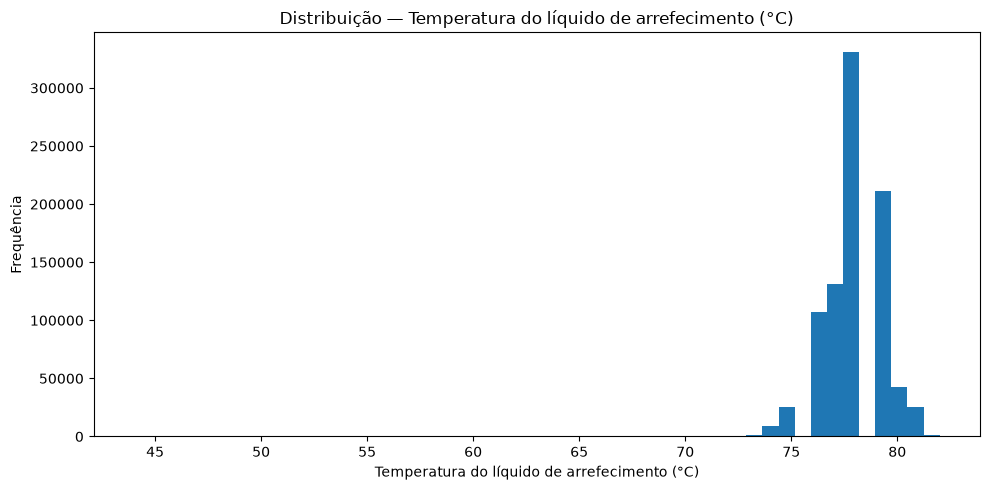

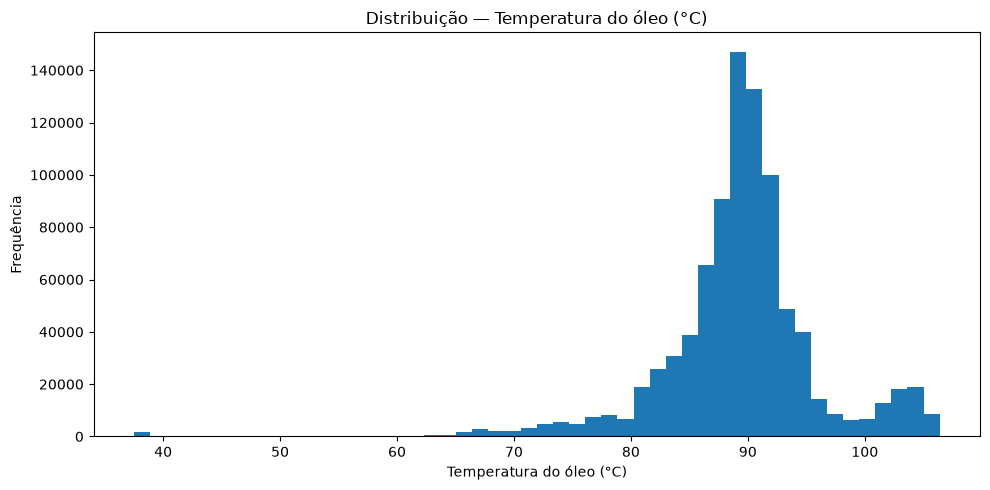

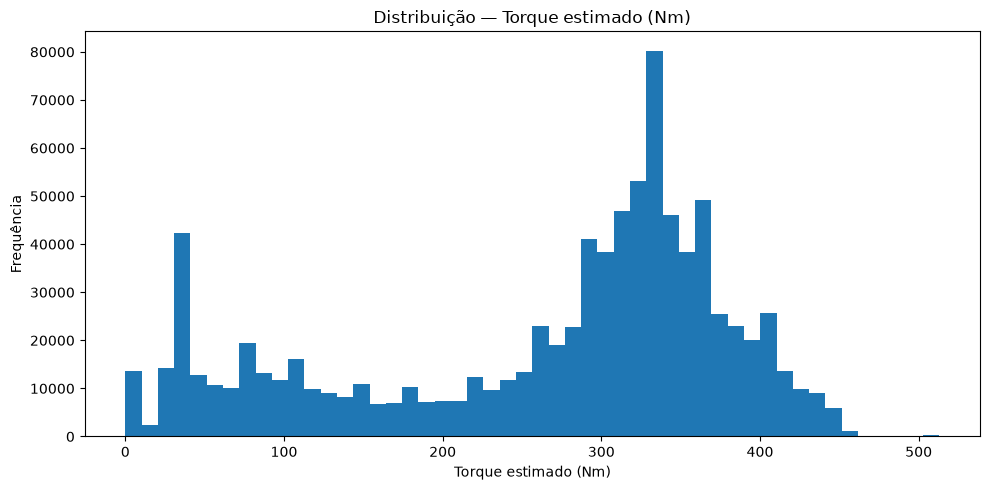

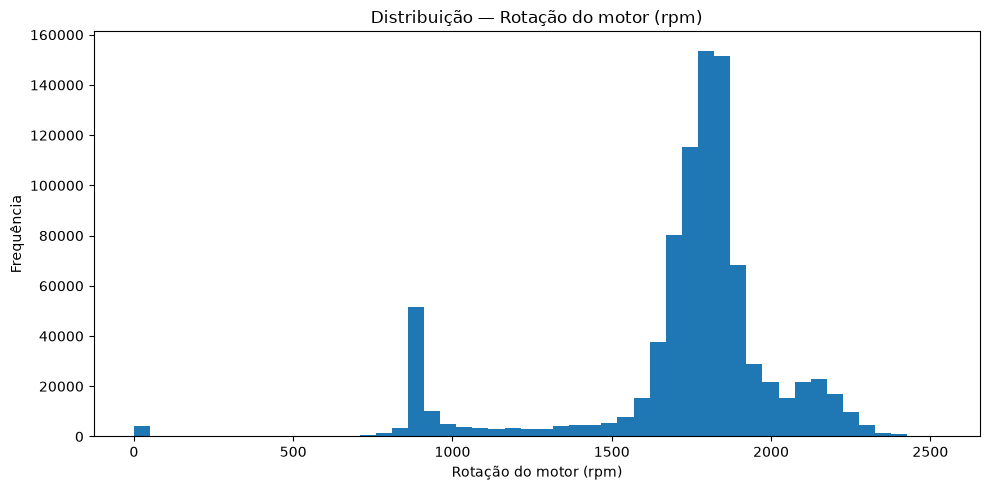

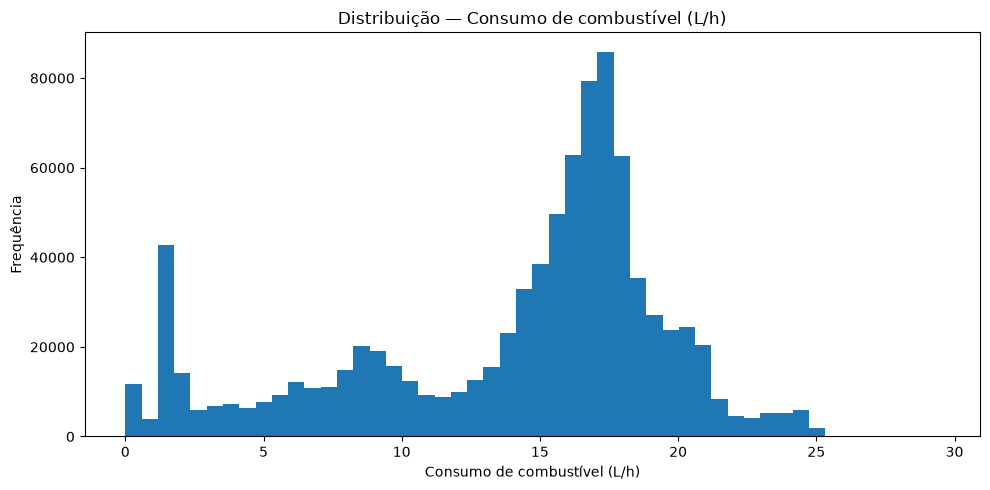

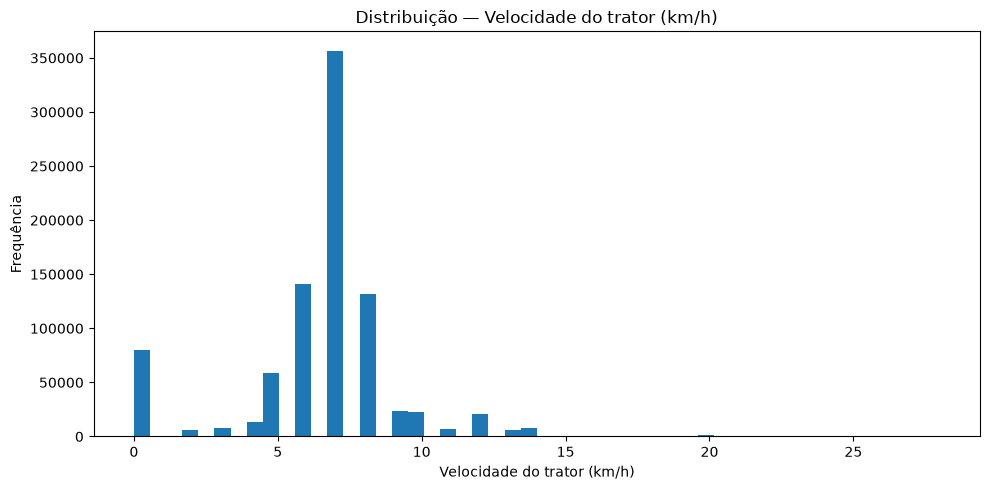

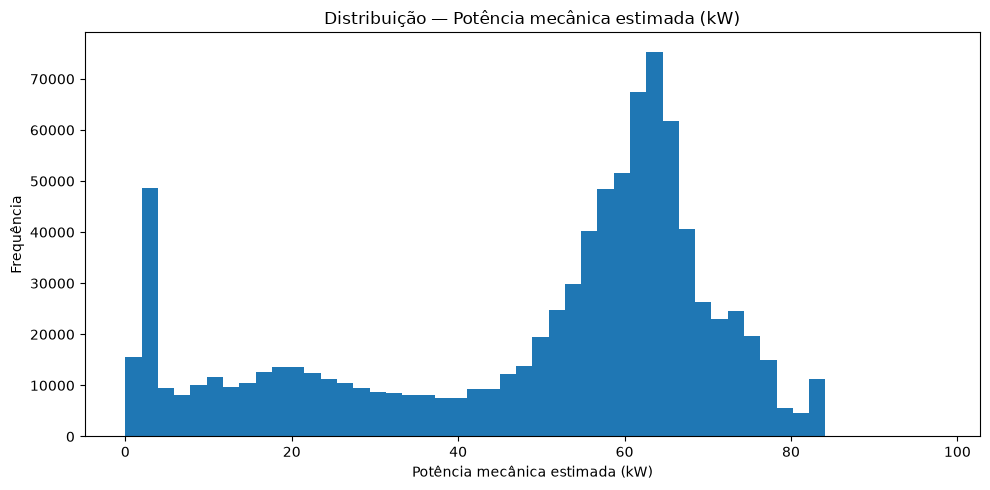

In [28]:
variaveis_hist = {
    "EngCoolantTemp": "Temperatura do líquido de arrefecimento (°C)",
    "EngOilTemp1": "Temperatura do óleo (°C)",
    "EngineTorque_Nm": "Torque estimado (Nm)",
    "EngineSpeed": "Rotação do motor (rpm)",
    "EngFuelRate": "Consumo de combustível (L/h)",
    "WheelBasedVehicleSpeed": "Velocidade do trator (km/h)",
    "EnginePower_kW": "Potência mecânica estimada (kW)"
}

for coluna, rotulo in variaveis_hist.items():
    plt.figure(figsize=(10, 5))
    plt.hist(
        df_tumosan_all[coluna].dropna(),
        bins=50
    )
    plt.title(f"Distribuição — {rotulo}")
    plt.xlabel(rotulo)
    plt.ylabel("Frequência")
    plt.tight_layout()
    plt.show()

## 6.6 — Temperatura por operação

Essa comparação não prova causalidade, mas permite verificar se os dois tipos de trabalho
apresentam regimes térmicos diferentes.

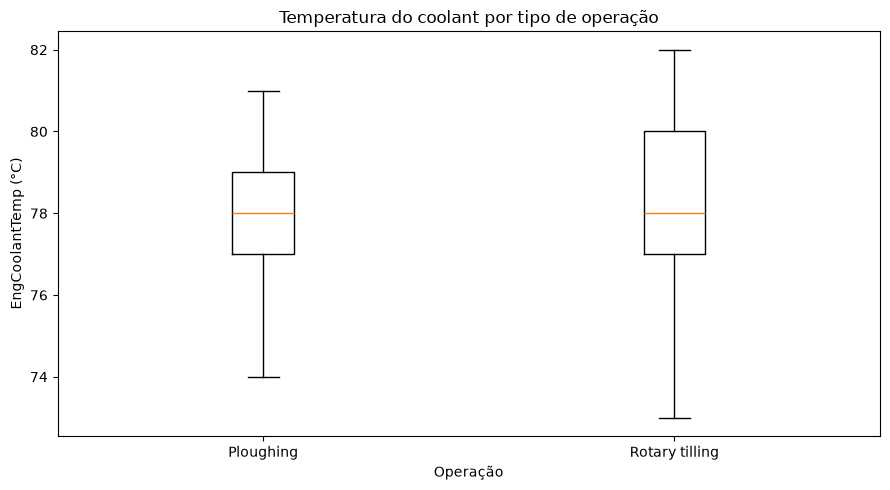

In [29]:
operacoes = list(df_tumosan_all["operacao"].dropna().unique())

dados_box = [
    df_tumosan_all.loc[
        df_tumosan_all["operacao"] == op,
        "EngCoolantTemp"
    ].dropna()
    for op in operacoes
]

plt.figure(figsize=(9, 5))
plt.boxplot(
    dados_box,
    tick_labels=operacoes,
    showfliers=False
)
plt.title("Temperatura do coolant por tipo de operação")
plt.ylabel("EngCoolantTemp (°C)")
plt.xlabel("Operação")
plt.tight_layout()
plt.show()

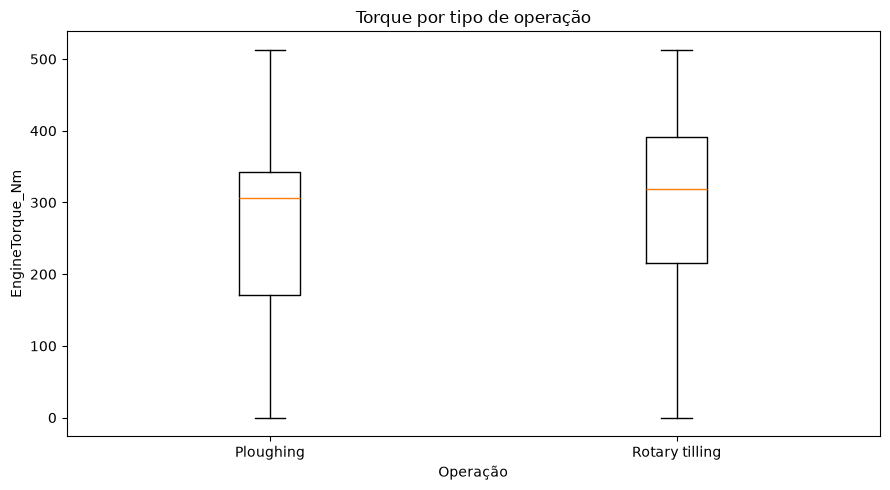

In [30]:
dados_box = [
    df_tumosan_all.loc[
        df_tumosan_all["operacao"] == op,
        "EngineTorque_Nm"
    ].dropna()
    for op in operacoes
]

plt.figure(figsize=(9, 5))
plt.boxplot(
    dados_box,
    tick_labels=operacoes,
    showfliers=False
)
plt.title("Torque por tipo de operação")
plt.ylabel("EngineTorque_Nm")
plt.xlabel("Operação")
plt.tight_layout()
plt.show()

## 6.7 — Relações bivariadas com o estado térmico

Como existem quase 900 mil registros, os gráficos usam uma amostra aleatória apenas para visualização.

A estatística continuará sendo calculada com a base completa.

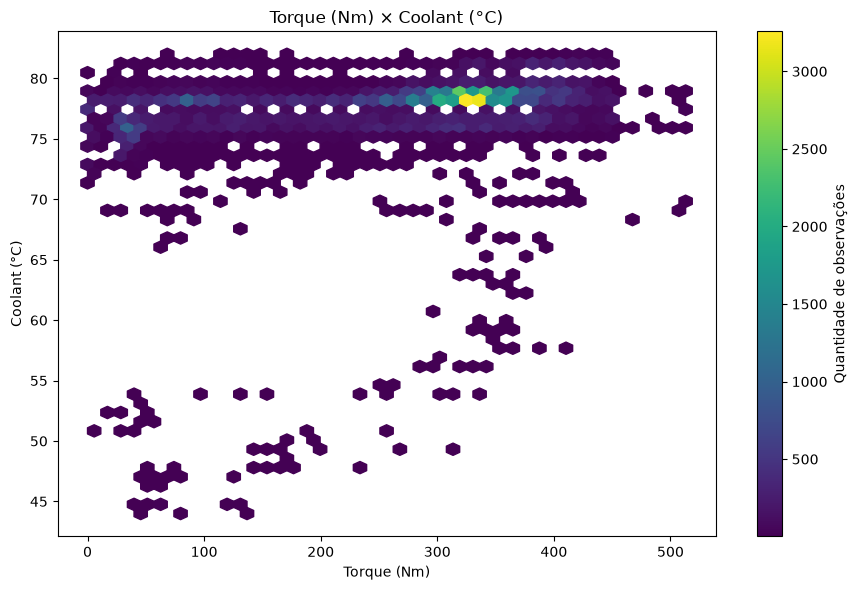

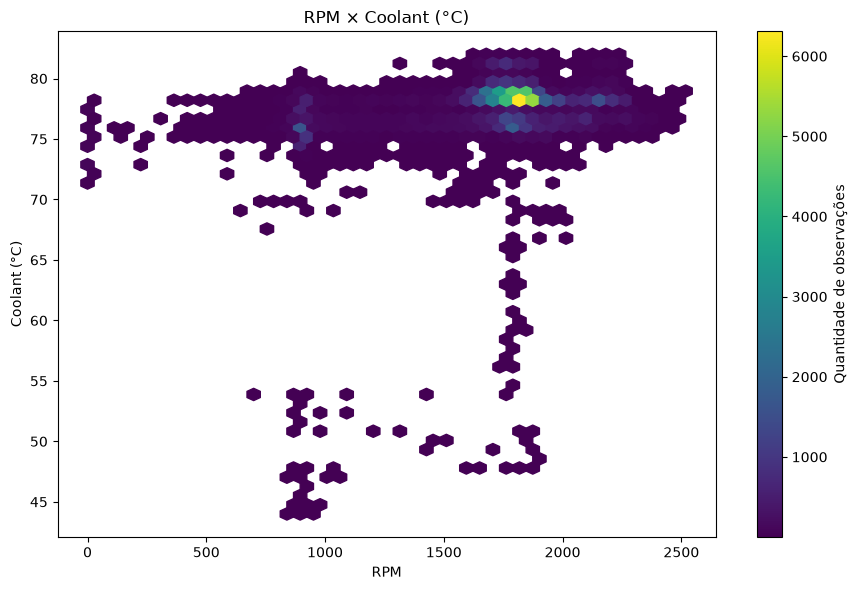

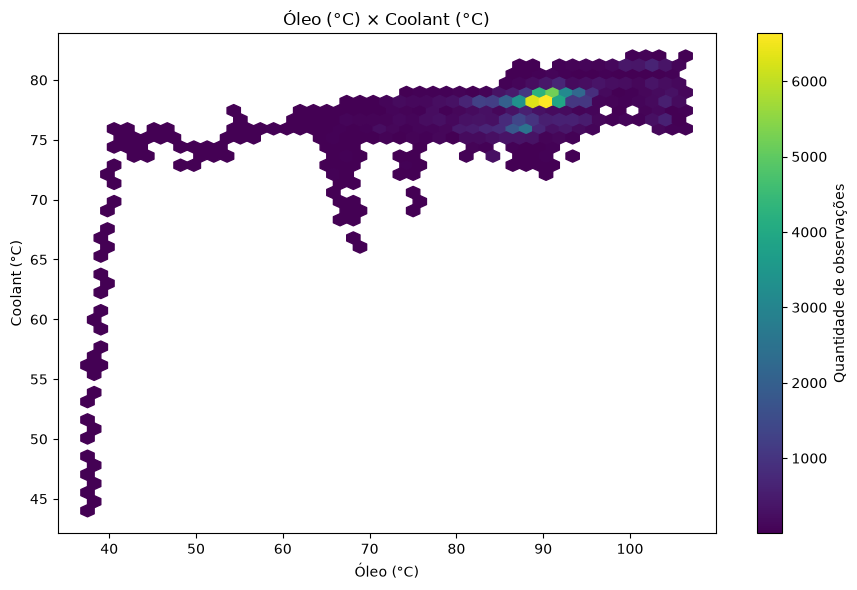

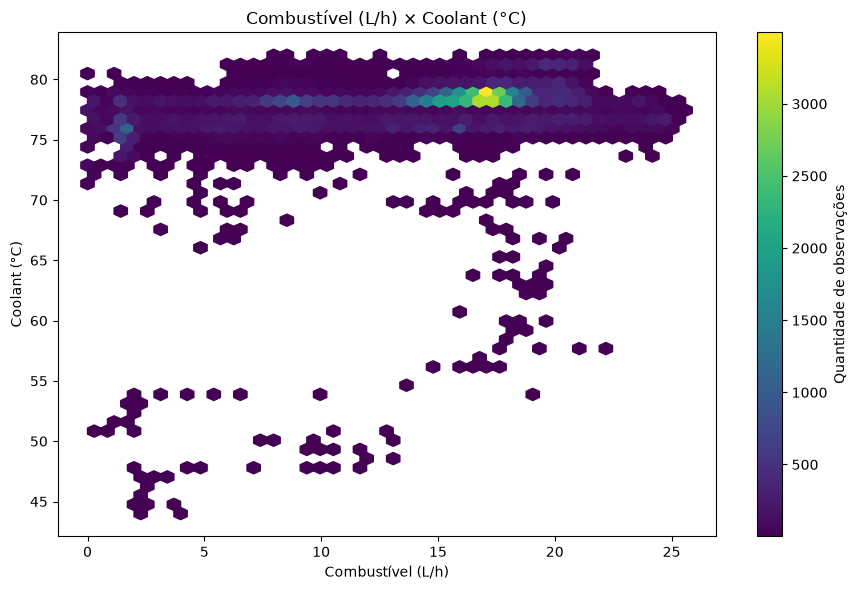

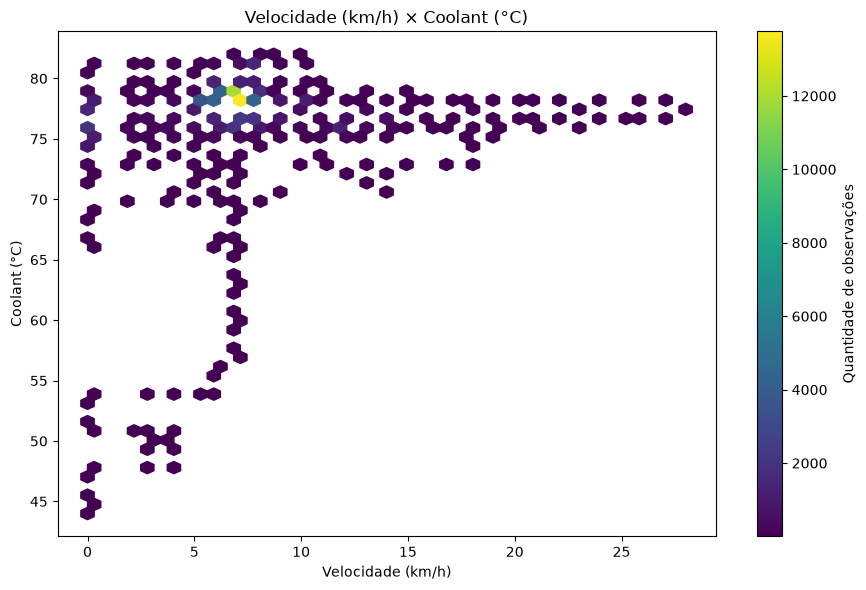

In [31]:
amostra_grafico = df_tumosan_all.sample(
    n=min(80_000, len(df_tumosan_all)),
    random_state=42
)

relacoes = [
    ("EngineTorque_Nm", "EngCoolantTemp", "Torque (Nm)", "Coolant (°C)"),
    ("EngineSpeed", "EngCoolantTemp", "RPM", "Coolant (°C)"),
    ("EngOilTemp1", "EngCoolantTemp", "Óleo (°C)", "Coolant (°C)"),
    ("EngFuelRate", "EngCoolantTemp", "Combustível (L/h)", "Coolant (°C)"),
    ("WheelBasedVehicleSpeed", "EngCoolantTemp", "Velocidade (km/h)", "Coolant (°C)")
]

for x, y, xlabel, ylabel in relacoes:
    plt.figure(figsize=(9, 6))
    plt.hexbin(
        amostra_grafico[x],
        amostra_grafico[y],
        gridsize=45,
        mincnt=1
    )
    plt.title(f"{xlabel} × {ylabel}")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.colorbar(label="Quantidade de observações")
    plt.tight_layout()
    plt.show()

## 6.7.1 — Interpretação das relações bivariadas

Cada hexbin mostra a concentração de observações, e não apenas pontos isolados. A leitura correta é procurar regiões densas, tendência, dispersão e mudança de variância.

- uma nuvem inclinada sugere associação no conjunto observado;
- uma nuvem larga mostra que a variável isolada não explica a temperatura;
- faixas ou agrupamentos podem indicar diferentes regimes de operação;
- pontos extremos precisam ser confrontados com tempo, sessão e outros sensores antes de serem removidos.

A amostra de 80.000 linhas é usada apenas para tornar o gráfico legível; ela não altera as estatísticas calculadas na base completa. Isso é importante para não confundir uma visualização amostral com uma filtragem dos dados. O resultado é relevante porque testa se a temperatura deve ser interpretada junto com esforço, regime, lubrificação, consumo e velocidade.

## 6.8 — Matriz de correlação

Correlação será usada apenas como **medida de associação linear**.

Ela não será interpretada como causalidade.

Como o dataset é temporal, uma correlação baixa no mesmo instante não significa que a variável
não seja útil: torque elevado pode influenciar a temperatura alguns minutos depois.

In [32]:
variaveis_correlacao = [
    "EngCoolantTemp",
    "EngOilTemp1",
    "EngOilPress",
    "EngineTorque_Nm",
    "EngineSpeed",
    "EngFuelRate",
    "WheelBasedVehicleSpeed",
    "EnginePower_kW",
    "HtcPositionSensPerc"
]

matriz_correlacao = (
    df_tumosan_all[variaveis_correlacao]
    .corr(method="pearson")
)

matriz_correlacao

,EngCoolantTemp,EngOilTemp1,EngOilPress,EngineTorque_Nm,EngineSpeed,EngFuelRate,WheelBasedVehicleSpeed,EnginePower_kW,HtcPositionSensPerc
EngCoolantTemp,1.00,0.57,0.25,0.36,0.30,0.36,0.19,0.37,-0.32
EngOilTemp1,0.57,1.00,-0.07,0.26,0.20,0.29,0.15,0.28,-0.13
EngOilPress,0.25,-0.07,1.00,0.26,0.73,0.36,0.32,0.33,-0.22
EngineTorque_Nm,0.36,0.26,0.26,1.00,0.32,0.94,0.46,0.98,-0.64
EngineSpeed,0.30,0.20,0.73,0.32,1.00,0.54,0.52,0.45,-0.10
EngFuelRate,0.36,0.29,0.36,0.94,0.54,1.00,0.55,0.98,-0.57
WheelBasedVehicleSpeed,0.19,0.15,0.32,0.46,0.52,0.55,1.00,0.51,-0.03
EnginePower_kW,0.37,0.28,0.33,0.98,0.45,0.98,0.51,1.00,-0.63
HtcPositionSensPerc,-0.32,-0.13,-0.22,-0.64,-0.10,-0.57,-0.03,-0.63,1.00


## 6.8.1 — Interpretação da matriz de correlação

A correlação de Pearson resume associação linear contemporânea entre pares de variáveis. Ela é útil para triagem, mas não responde sozinha se uma variável causa aquecimento, se o efeito é atrasado ou se a associação vem de um terceiro fator, como o tipo de implemento.

Por isso, o resultado deve ser usado para:

- identificar sinais redundantes ou potencialmente complementares;
- selecionar relações para investigação temporal;
- comparar a coerência dos sinais com o significado físico documentado.

Uma correlação baixa não elimina uma feature: relações não lineares, efeitos por regime e resposta atrasada podem ser importantes. Uma correlação alta também não valida um sensor por si só. A validade resulta da combinação entre correlação, distribuição, unidade, continuidade temporal e plausibilidade física.

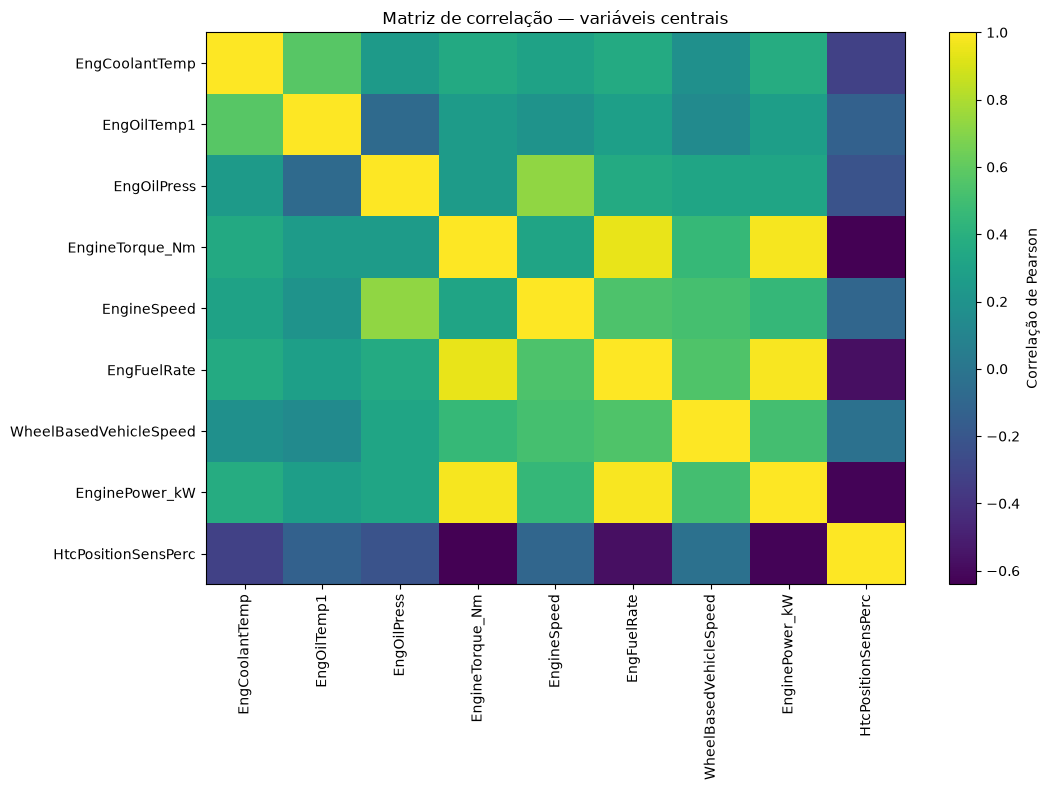

In [33]:
plt.figure(figsize=(11, 8))

imagem = plt.imshow(
    matriz_correlacao.values,
    aspect="auto"
)

plt.xticks(
    range(len(variaveis_correlacao)),
    variaveis_correlacao,
    rotation=90
)

plt.yticks(
    range(len(variaveis_correlacao)),
    variaveis_correlacao
)

plt.colorbar(imagem, label="Correlação de Pearson")
plt.title("Matriz de correlação — variáveis centrais")
plt.tight_layout()
plt.show()

## 6.9 — Carga do motor × comportamento térmico

O torque será dividido em faixas baseadas na própria distribuição da base.

Isso evita inventar limites arbitrários de “baixa” e “alta” carga.

In [34]:
df_tumosan_all["faixa_torque"] = pd.qcut(
    df_tumosan_all["EngineTorque_Nm"],
    q=5,
    duplicates="drop"
)

termica_por_torque = (
    df_tumosan_all
    .groupby("faixa_torque", observed=True)
    .agg(
        amostras=("EngCoolantTemp", "size"),
        torque_medio_Nm=("EngineTorque_Nm", "mean"),
        coolant_media_C=("EngCoolantTemp", "mean"),
        coolant_mediana_C=("EngCoolantTemp", "median"),
        coolant_max_C=("EngCoolantTemp", "max"),
        oil_media_C=("EngOilTemp1", "mean"),
        fuel_media_L_h=("EngFuelRate", "mean")
    )
    .reset_index()
)

termica_por_torque

,faixa_torque,amostras,torque_medio_Nm,coolant_media_C,coolant_mediana_C,coolant_max_C,oil_media_C,fuel_media_L_h
0,"(-0.001, 126.0]",180792,61.04,76.81,77.00,82,87.37,4.66
1,"(126.0, 283.5]",181315,223.47,77.46,78.00,82,86.76,12.41
2,"(283.5, 324.0]",179414,309.00,78.20,78.00,82,89.97,16.16
3,"(324.0, 360.0]",182698,342.67,78.31,78.00,82,90.16,17.52
4,"(360.0, 513.0]",165036,394.93,78.46,78.00,82,92.58,19.68


## 6.10 — Análise de defasagem térmica

O motor possui inércia térmica.

Portanto, a pergunta correta não é somente:

> “Torque e temperatura estão correlacionados agora?”

Também precisamos perguntar:

> “O esforço observado anteriormente está associado à temperatura atual?”

Serão avaliadas defasagens de:

- 0 minuto;
- 1 minuto;
- 5 minutos;
- 10 minutos.

Como a aquisição ocorre a 10 Hz:

- 1 min = 600 amostras;
- 5 min = 3.000 amostras;
- 10 min = 6.000 amostras.

In [35]:
lags_minutos = [0, 1, 5, 10]

variaveis_esforco = [
    "EngineTorque_Nm",
    "EngineSpeed",
    "EngFuelRate",
    "EnginePower_kW",
    "EngOilTemp1"
]

correlacoes_lag = []

for field_id, grupo in df_tumosan_all.groupby("field_id", sort=True):
    grupo = grupo.sort_values("time_ms").reset_index(drop=True)

    for variavel in variaveis_esforco:
        for lag_min in lags_minutos:
            lag_amostras = lag_min * 60 * 10

            if lag_amostras == 0:
                serie_passada = grupo[variavel]
            else:
                serie_passada = grupo[variavel].shift(lag_amostras)

            valido = (
                serie_passada.notna()
                & grupo["EngCoolantTemp"].notna()
            )

            if valido.sum() > 10:
                correlacao = serie_passada[valido].corr(
                    grupo.loc[valido, "EngCoolantTemp"]
                )
            else:
                correlacao = np.nan

            correlacoes_lag.append({
                "field_id": field_id,
                "variavel": variavel,
                "lag_min": lag_min,
                "correlacao_com_coolant_atual": correlacao
            })

correlacoes_lag = pd.DataFrame(correlacoes_lag)

resumo_lag = (
    correlacoes_lag
    .groupby(["variavel", "lag_min"], as_index=False)
    .agg(
        correlacao_media=("correlacao_com_coolant_atual", "mean"),
        correlacao_mediana=("correlacao_com_coolant_atual", "median"),
        sessoes_validas=("correlacao_com_coolant_atual", "count")
    )
)

resumo_lag

,variavel,lag_min,correlacao_media,correlacao_mediana,sessoes_validas
0,EngFuelRate,0,0.43,0.39,10
1,EngFuelRate,1,0.38,0.39,10
2,EngFuelRate,5,0.16,0.09,10
3,EngFuelRate,10,0.06,0.04,10
4,EngOilTemp1,0,0.45,0.44,10
5,EngOilTemp1,1,0.39,0.41,10
6,EngOilTemp1,5,0.24,0.22,10
7,EngOilTemp1,10,0.12,0.09,10
8,EnginePower_kW,0,0.42,0.39,10
9,EnginePower_kW,1,0.37,0.38,10


## 6.10.1 — Por que a análise de defasagem é uma evidência importante

O cálculo desloca cada sinal de esforço no tempo e compara o passado com o coolant atual, sempre reiniciando dentro de cada `field_id`. Isso evita misturar o fim de uma sessão com o início de outra.

A tabela `resumo_lag` deve ser lida como evidência exploratória de memória térmica:

- o lag de 0 minuto mede associação no mesmo instante;
- os lags de 1, 5 e 10 minutos testam se o esforço anterior acompanha a resposta térmica posterior;
- média e mediana entre sessões mostram se a relação é consistente ou depende de um único campo;
- `sessoes_validas` informa quantas sessões realmente sustentam cada resumo.

Uma associação defasada é mais compatível com a hipótese de inércia térmica, mas ainda não prova causalidade nem superaquecimento. Ela é relevante porque justifica features temporais, como médias móveis, máximos recentes e taxa de aquecimento, em vez de usar apenas a leitura instantânea.

## 6.11 — Séries temporais de sessões representativas

Para visualizar dinâmica térmica sem exibir centenas de milhares de pontos,
os gráficos usam médias de **1 segundo**.

Serão mostrados:

- `FIELD_8`: maior sessão de aração;
- `FIELD_10`: sessão de rotary tilling reservada posteriormente para teste final.

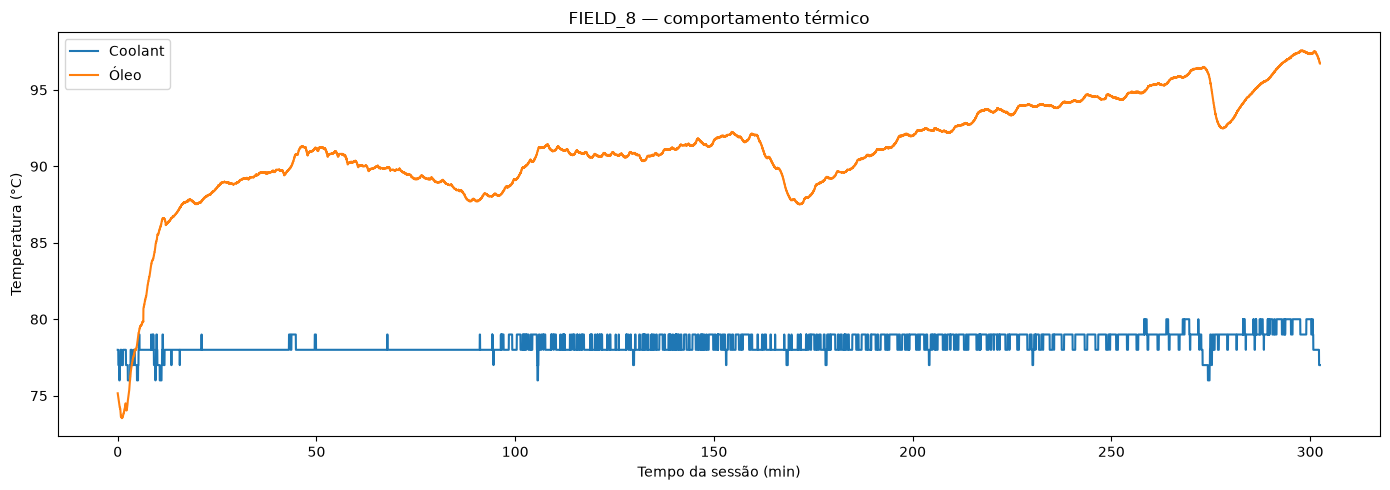

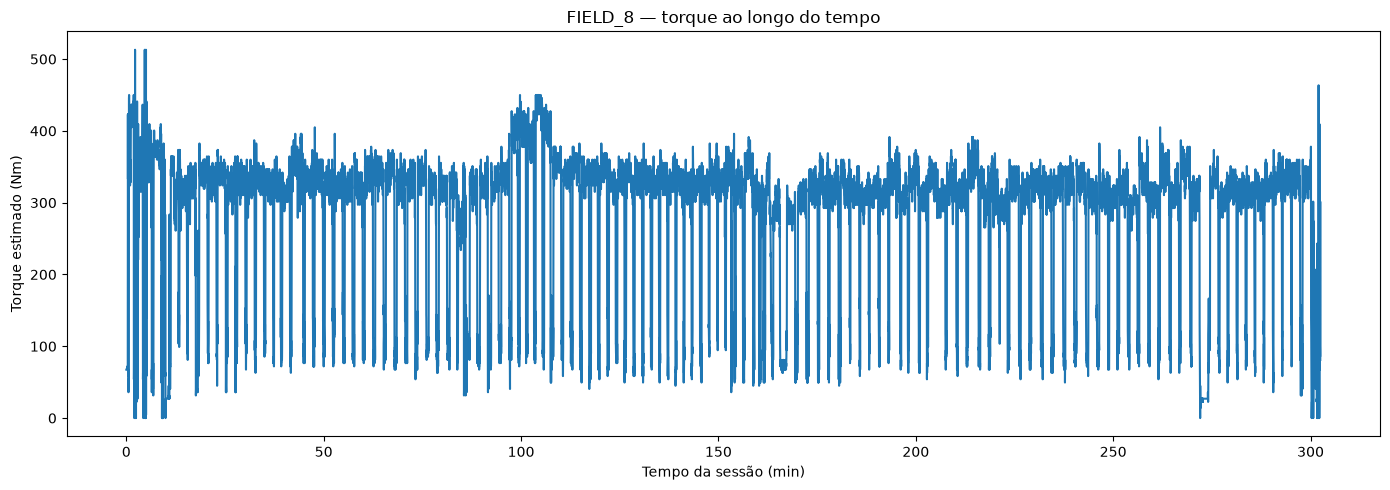

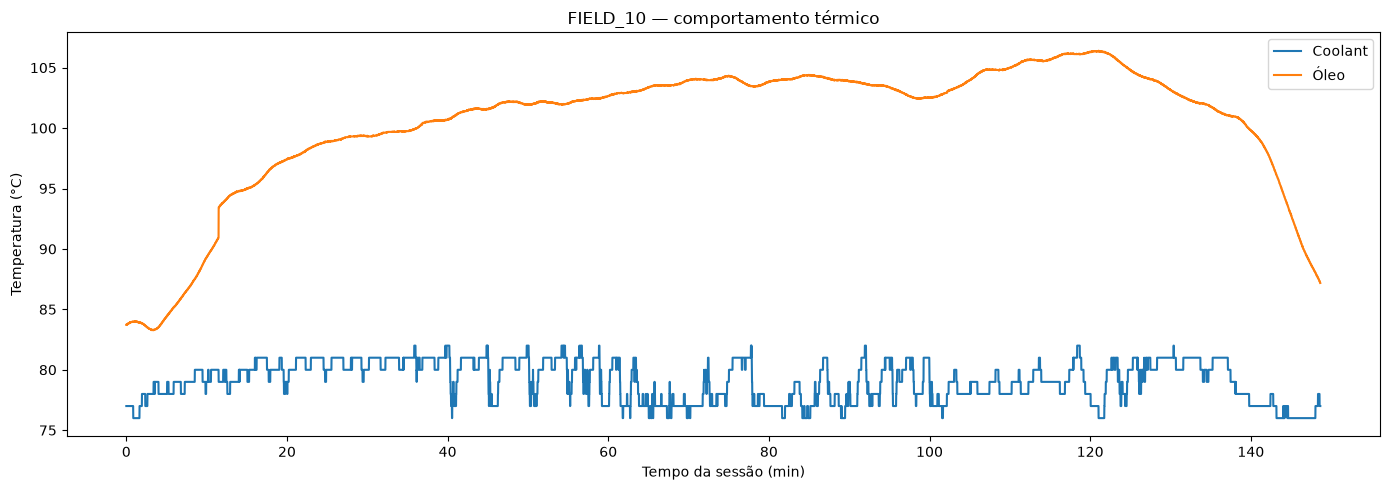

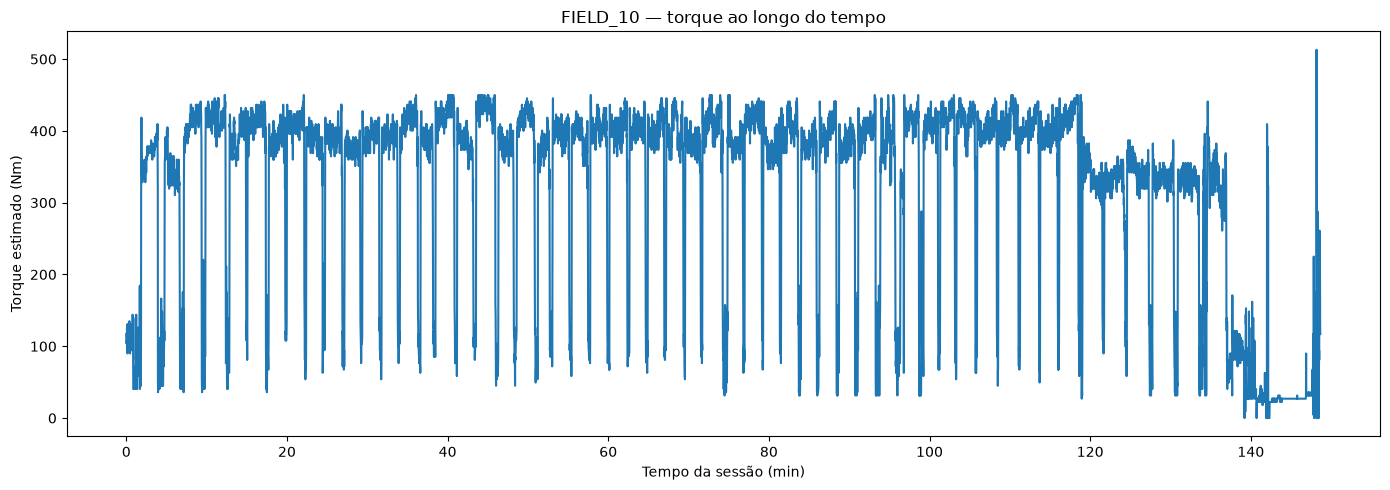

In [36]:
for field_id in [8, 10]:
    sessao = (
        df_tumosan_all[
            df_tumosan_all["field_id"] == field_id
        ]
        .copy()
        .iloc[::10]
    )

    plt.figure(figsize=(14, 5))
    plt.plot(
        sessao["time_min"],
        sessao["EngCoolantTemp"],
        label="Coolant"
    )
    plt.plot(
        sessao["time_min"],
        sessao["EngOilTemp1"],
        label="Óleo"
    )
    plt.title(f"FIELD_{field_id} — comportamento térmico")
    plt.xlabel("Tempo da sessão (min)")
    plt.ylabel("Temperatura (°C)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(14, 5))
    plt.plot(
        sessao["time_min"],
        sessao["EngineTorque_Nm"]
    )
    plt.title(f"FIELD_{field_id} — torque ao longo do tempo")
    plt.xlabel("Tempo da sessão (min)")
    plt.ylabel("Torque estimado (Nm)")
    plt.tight_layout()
    plt.show()

## 6.12 — Conclusão técnica do EDA Tümosan

Os resultados conhecidos até esta etapa permitem afirmar:

### Integridade dos dados
A estrutura temporal é excepcionalmente consistente: as 889.255 amostras estão
presentes, a frequência é uniforme em 10 Hz e não foram encontrados gaps ou
timestamps duplicados.

### Estado térmico observado
Nas sessões publicadas, `EngCoolantTemp` atingiu aproximadamente **82 °C no máximo**.

Portanto, essa base representa **operações reais de alta carga dentro do regime observado**,
e não um conjunto de eventos de superaquecimento.

### Temperatura do óleo
A temperatura do óleo apresenta variação muito maior que o coolant e alcança valores
superiores a 100 °C em algumas sessões, sendo um sinal térmico complementar importante.

### Torque
Foram encontrados valores acima de 100% do torque de referência. Isso é permitido pela
própria documentação J1939 da base e não será tratado automaticamente como erro.

### Sensores de draft
A frequência elevada de valores fora de 0–100% entra em conflito com a expectativa do README
de ocorrências raras. Por segurança, esses sinais ficam fora do modelo principal até que a
escala possa ser validada.

### Limitação central
O Tümosan não possui temperatura ambiente nem rótulos reais de falha térmica.

Consequentemente, a modelagem será apresentada como:

> **previsão do comportamento térmico futuro do trator em operação agrícola de alta carga**

e não como classificação direta de incêndio.

# Passo 7 — Fechamento do EDA Tümosan e Handoff Analítico

O objetivo deste passo é encerrar a análise do Tümosan **sem treinar modelos**.

Até aqui, a base Tümosan permitiu:

- validar 889.255 observações reais;
- confirmar uma frequência uniforme de 10 Hz;
- estudar temperatura de coolant e óleo;
- analisar torque, RPM, combustível e velocidade;
- comparar aração e rotary tilling;
- analisar relações instantâneas e defasadas;
- identificar limitações de qualidade específicas.

O resultado agora será transformado em uma **especificação de dados para o responsável pelo Machine Learning**.

## 7.1 — Decisão final das variáveis do Tümosan

As variáveis são separadas em quatro grupos:

### A — recomendadas como núcleo do problema térmico

- `EngCoolantTemp`
- `EngOilTemp1`
- `EngOilPress`
- `ActualEngine_PercTorque`
- `EngineSpeed`
- `EngFuelRate`
- `WheelBasedVehicleSpeed`

### B — úteis como contexto operacional

- `HtcPositionSensPerc`
- `TransferCaseStatus`
- `PTO_Status`
- `KeypadButon`

### C — usar somente com tratamento específico

- `ATSTemp`: 39,52% de ausência global e ausência completa em várias sessões.

### D — não usar no primeiro modelo

- `HtcDraftSens1Perc`
- `HtcDraftSens2Perc`

Os sensores de draft foram preservados, porém a quantidade de registros fora da faixa nominal
0–100% foi muito elevada. Eles não serão descartados permanentemente, mas ficam fora da primeira
versão até que sua escala/calibração seja esclarecida.

In [37]:
decisao_tumosan = pd.DataFrame([
    {
        "variavel": "EngCoolantTemp",
        "grupo": "núcleo térmico",
        "status": "RECOMENDADA",
        "justificativa": "Principal estado térmico do sistema de arrefecimento"
    },
    {
        "variavel": "EngOilTemp1",
        "grupo": "núcleo térmico",
        "status": "RECOMENDADA",
        "justificativa": "Estado térmico do óleo; apresentou amplitude relevante"
    },
    {
        "variavel": "EngOilPress",
        "grupo": "motor/lubrificação",
        "status": "RECOMENDADA",
        "justificativa": "Caracteriza lubrificação e regime do motor"
    },
    {
        "variavel": "ActualEngine_PercTorque",
        "grupo": "esforço",
        "status": "RECOMENDADA",
        "justificativa": "Carga mecânica do motor"
    },
    {
        "variavel": "EngineSpeed",
        "grupo": "regime",
        "status": "RECOMENDADA",
        "justificativa": "Rotação e condição operacional do motor"
    },
    {
        "variavel": "EngFuelRate",
        "grupo": "demanda energética",
        "status": "RECOMENDADA",
        "justificativa": "Proxy de esforço e consumo energético"
    },
    {
        "variavel": "WheelBasedVehicleSpeed",
        "grupo": "contexto operacional",
        "status": "RECOMENDADA",
        "justificativa": "Ajuda a distinguir deslocamento, trabalho e manobra"
    },
    {
        "variavel": "HtcPositionSensPerc",
        "grupo": "contexto agronômico",
        "status": "CONTEXTO",
        "justificativa": "Posição do implemento/engate"
    },
    {
        "variavel": "TransferCaseStatus",
        "grupo": "contexto operacional",
        "status": "CONTEXTO",
        "justificativa": "Estado da tração/caixa de transferência"
    },
    {
        "variavel": "PTO_Status",
        "grupo": "contexto operacional",
        "status": "CONTEXTO",
        "justificativa": "Distingue operação com/sem PTO"
    },
    {
        "variavel": "KeypadButon",
        "grupo": "contexto agronômico",
        "status": "CONTEXTO",
        "justificativa": "Identifica o implemento declarado"
    },
    {
        "variavel": "ATSTemp",
        "grupo": "térmico secundário",
        "status": "CONDICIONAL",
        "justificativa": "Ausência estrutural elevada; analisar somente onde disponível"
    },
    {
        "variavel": "HtcDraftSens1Perc",
        "grupo": "esforço no implemento",
        "status": "ADIAR",
        "justificativa": "Muitos registros fora da faixa nominal; escala precisa ser validada"
    },
    {
        "variavel": "HtcDraftSens2Perc",
        "grupo": "esforço no implemento",
        "status": "ADIAR",
        "justificativa": "Muitos registros fora da faixa nominal; escala precisa ser validada"
    }
])

decisao_tumosan

,variavel,grupo,status,justificativa
0,EngCoolantTemp,núcleo térmico,RECOMENDADA,Principal estado térmico do sistema de arrefec...
1,EngOilTemp1,núcleo térmico,RECOMENDADA,Estado térmico do óleo; apresentou amplitude r...
2,EngOilPress,motor/lubrificação,RECOMENDADA,Caracteriza lubrificação e regime do motor
3,ActualEngine_PercTorque,esforço,RECOMENDADA,Carga mecânica do motor
4,EngineSpeed,regime,RECOMENDADA,Rotação e condição operacional do motor
5,EngFuelRate,demanda energética,RECOMENDADA,Proxy de esforço e consumo energético
6,WheelBasedVehicleSpeed,contexto operacional,RECOMENDADA,"Ajuda a distinguir deslocamento, trabalho e ma..."
7,HtcPositionSensPerc,contexto agronômico,CONTEXTO,Posição do implemento/engate
8,TransferCaseStatus,contexto operacional,CONTEXTO,Estado da tração/caixa de transferência
9,PTO_Status,contexto operacional,CONTEXTO,Distingue operação com/sem PTO


## 7.2 — Arquivo de handoff do Tümosan

Serão salvas as tabelas de evidência, sem modificar os arquivos brutos.

In [38]:
EDA_OUTPUT_PATH = PROJECT_ROOT / "data" / "processed" / "eda"
EDA_OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

decisao_tumosan.to_csv(
    EDA_OUTPUT_PATH / "tumosan_decisao_variaveis.csv",
    index=False
)

estatisticas_motor_sessoes.to_csv(
    EDA_OUTPUT_PATH / "tumosan_estatisticas_por_sessao.csv",
    index=False
)

resumo_nulos_global.to_csv(
    EDA_OUTPUT_PATH / "tumosan_nulos_global.csv",
    index=False
)

if "resumo_lag" in globals():
    resumo_lag.to_csv(
        EDA_OUTPUT_PATH / "tumosan_correlacoes_defasadas.csv",
        index=False
    )

print(f"Resultados do EDA salvos em: {EDA_OUTPUT_PATH}")

Resultados do EDA salvos em: /home/debianjv/Documentos/maia-intelligence-NEXT/machine_learning/data/processed/eda


# Passo 8 — EDA de Validação Externa com Tratores Fendt

O Tümosan fornece uma base extensa e consistente, mas representa um único modelo de trator.

Para verificar se as variáveis escolhidas fazem sentido fora desse equipamento,
utilizaremos a base **Agricultural Load Cycles**, da Technical University of Munich.

A base Fendt contém telemetria real de tratores agrícolas registrada com:

- CAN-Bus SAE J1939;
- ISOBUS;
- GNSS;
- frequência padronizada de 10 Hz.

Um ponto especialmente importante é a existência de **temperatura ambiente**, ausente no Tümosan.

## Objetivo do Passo 8

Não queremos provar que Fendt e Tümosan possuem os mesmos valores.

Tratores diferentes possuem potência, configuração, implementos e condições ambientais diferentes.

O objetivo é verificar se as **mesmas famílias de sinais** aparecem em outro conjunto agrícola real:

- temperatura do coolant;
- temperatura ambiente;
- torque/carga;
- RPM;
- pressão de óleo;
- consumo;
- velocidade.

Fonte pública:

- Zenodo: https://zenodo.org/records/14619787
- Artigo: https://pmc.ncbi.nlm.nih.gov/articles/PMC11993161/

## 8.1 — Inventário da base Fendt

O código prioriza os arquivos de **campo (`Field_*.csv`)**, pois eles representam uma operação agrícola
específica com um implemento conhecido.

O arquivo completo do trator pode ser muito maior e não é necessário para esta etapa de validação.

In [39]:
arquivos_fendt_csv = sorted(
    FENDT_PATH.rglob("*.csv")
)

arquivos_fendt_field = [
    arquivo
    for arquivo in arquivos_fendt_csv
    if arquivo.stem.lower().startswith("field_")
]

# Fallback caso a organização da pasta seja diferente.
if len(arquivos_fendt_field) == 0:
    arquivos_fendt_field = [
        arquivo
        for arquivo in arquivos_fendt_csv
        if arquivo.stat().st_size < 300 * 1024**2
    ]

inventario_fendt_field = pd.DataFrame([
    {
        "arquivo": arquivo.name,
        "operacao_pasta": arquivo.parent.name,
        "tamanho_mb": arquivo.stat().st_size / (1024**2),
        "caminho": str(arquivo.relative_to(PROJECT_ROOT))
    }
    for arquivo in arquivos_fendt_field
])

print(f"CSVs encontrados no Fendt: {len(arquivos_fendt_csv)}")
print(f"Arquivos de campo selecionados: {len(arquivos_fendt_field)}")

inventario_fendt_field

CSVs encontrados no Fendt: 5
Arquivos de campo selecionados: 4


,arquivo,operacao_pasta,tamanho_mb,caminho
0,Field_1.csv,Power harrowing,26.52,data/raw/fendt/Fendt 211 - Kopie/Power harrowi...
1,Field_2.csv,Power harrowing,13.56,data/raw/fendt/Fendt 211 - Kopie/Power harrowi...
2,Field_1.csv,Precision air seeding,7.27,data/raw/fendt/Fendt 211 - Kopie/Precision air...
3,Field_2.csv,Precision air seeding,4.85,data/raw/fendt/Fendt 211 - Kopie/Precision air...


## 8.2 — Funções para localizar sinais equivalentes

Os datasets usam convenções de nomes diferentes.

Por isso, a equivalência entre bases será feita pelo **significado técnico do sinal**,
e não pela igualdade literal do nome da coluna.

In [40]:
def normalizar_nome_coluna(nome):
    return re.sub(
        r"[^a-z0-9]",
        "",
        str(nome).lower()
    )


def localizar_coluna(colunas, aliases):
    mapa = {
        normalizar_nome_coluna(coluna): coluna
        for coluna in colunas
    }

    # Primeiro procura igualdade normalizada.
    for alias in aliases:
        chave = normalizar_nome_coluna(alias)

        if chave in mapa:
            return mapa[chave]

    # Depois procura aliases contidos no nome.
    for alias in aliases:
        chave = normalizar_nome_coluna(alias)

        for normalizado, original in mapa.items():
            if chave and chave in normalizado:
                return original

    return None


aliases_fendt = {
    "time": [
        "Time",
        "timestamp"
    ],
    "coolant_temp": [
        "EngCoolantTemp",
        "EngineCoolantTemp"
    ],
    "ambient_temp": [
        "Ambient Air Temperature",
        "AmbientAirTemperature",
        "AmbientAirTemp"
    ],
    "torque_pct": [
        "ActualEngPercentTorque",
        "ActualEnginePercentTorque"
    ],
    "engine_load_pct": [
        "EngPercentLoadAtCurrent Speed",
        "EngPercentLoadAtCurrentSpeed",
        "EnginePercentLoadAtCurrentSpeed"
    ],
    "engine_speed": [
        "Eng_Speed",
        "EngineSpeed",
        "EngSpeed"
    ],
    "oil_pressure": [
        "EngOilPress",
        "EngineOilPressure"
    ],
    "fuel_rate": [
        "EngFuelRate",
        "EngineFuelRate"
    ],
    "reference_torque": [
        "EngReferenceTorque",
        "EngineReferenceTorque"
    ],
    "vehicle_speed": [
        "GroundBasedMachineSpeed",
        "WheelBasedVehicleSpeed",
        "MachineSelectedSpeed",
        "FrontAxleSpeed"
    ]
}

## 8.3 — Verificação das colunas disponíveis por arquivo

In [41]:
disponibilidade_fendt = []

for arquivo in arquivos_fendt_field:
    cabecalho = pd.read_csv(
        arquivo,
        nrows=0
    )

    registro = {
        "arquivo": arquivo.name,
        "operacao_pasta": arquivo.parent.name
    }

    for papel, aliases in aliases_fendt.items():
        registro[papel] = localizar_coluna(
            cabecalho.columns,
            aliases
        )

    disponibilidade_fendt.append(registro)

disponibilidade_fendt = pd.DataFrame(
    disponibilidade_fendt
)

disponibilidade_fendt

,arquivo,operacao_pasta,time,coolant_temp,ambient_temp,torque_pct,engine_load_pct,engine_speed,oil_pressure,fuel_rate,reference_torque,vehicle_speed
0,Field_1.csv,Power harrowing,Time_(s),EngCoolantTemp_(°C),AmbientAirTemp_(°C),ActualEngPercentTorque_(%),EngPercentLoadAtCurrentSpeed_(%),EngSpeed_(RPM),EngOilPress_(kPa),EngFuelRate_(L/h),EngReferenceTorque_[Nm],GroundBasedMachineSpeed_(m/s)
1,Field_2.csv,Power harrowing,Time_(s),EngCoolantTemp_(°C),AmbientAirTemp_(°C),ActualEngPercentTorque_(%),EngPercentLoadAtCurrentSpeed_(%),EngSpeed_(RPM),EngOilPress_(kPa),EngFuelRate_(L/h),EngReferenceTorque_[Nm],GroundBasedMachineSpeed_(m/s)
2,Field_1.csv,Precision air seeding,Time_(s),EngCoolantTemp_(°C),AmbientAirTemp_(°C),ActualEngPercentTorque_(%),EngPercentLoadAtCurrentSpeed_(%),EngSpeed_(RPM),EngOilPress_(kPa),EngFuelRate_(L/h),EngReferenceTorque_[Nm],GroundBasedMachineSpeed_(m/s)
3,Field_2.csv,Precision air seeding,Time_(s),EngCoolantTemp_(°C),AmbientAirTemp_(°C),ActualEngPercentTorque_(%),EngPercentLoadAtCurrentSpeed_(%),EngSpeed_(RPM),EngOilPress_(kPa),EngFuelRate_(L/h),EngReferenceTorque_[Nm],GroundBasedMachineSpeed_(m/s)


## 8.4 — Construção da base analítica Fendt

Cada arquivo de campo será carregado separadamente e padronizado para nomes semânticos.

Somente sinais realmente encontrados serão copiados.

Nenhuma coluna ausente será inventada.

In [42]:
sessoes_fendt = []

for arquivo in arquivos_fendt_field:
    df_raw = pd.read_csv(arquivo)

    mapa_sinais = {
        papel: localizar_coluna(
            df_raw.columns,
            aliases
        )
        for papel, aliases in aliases_fendt.items()
    }

    df_padrao = pd.DataFrame(
        index=df_raw.index
    )

    df_padrao["arquivo"] = arquivo.name
    df_padrao["operacao"] = arquivo.parent.name

    for papel, coluna_real in mapa_sinais.items():
        if coluna_real is not None:
            df_padrao[papel] = pd.to_numeric(
                df_raw[coluna_real],
                errors="coerce"
            )

    sessoes_fendt.append(df_padrao)

if len(sessoes_fendt) == 0:
    raise FileNotFoundError(
        "Nenhum arquivo CSV de campo do Fendt foi encontrado."
    )

df_fendt = pd.concat(
    sessoes_fendt,
    ignore_index=True
)

print(
    f"Linhas analíticas Fendt: "
    f"{len(df_fendt):,}".replace(",", ".")
)

print(
    "Colunas padronizadas:",
    df_fendt.columns.tolist()
)

Linhas analíticas Fendt: 98.851
Colunas padronizadas: ['arquivo', 'operacao', 'time', 'coolant_temp', 'ambient_temp', 'torque_pct', 'engine_load_pct', 'engine_speed', 'oil_pressure', 'fuel_rate', 'reference_torque', 'vehicle_speed']


## 8.5 — Auditoria de qualidade Fendt

In [43]:
qualidade_fendt = pd.DataFrame({
    "variavel": df_fendt.columns,
    "tipo": [
        str(df_fendt[col].dtype)
        for col in df_fendt.columns
    ],
    "preenchidos": [
        int(df_fendt[col].notna().sum())
        for col in df_fendt.columns
    ],
    "ausentes": [
        int(df_fendt[col].isna().sum())
        for col in df_fendt.columns
    ],
    "percentual_ausente": [
        float(df_fendt[col].isna().mean() * 100)
        for col in df_fendt.columns
    ],
    "valores_unicos": [
        int(df_fendt[col].nunique(dropna=True))
        for col in df_fendt.columns
    ]
})

qualidade_fendt

,variavel,tipo,preenchidos,ausentes,percentual_ausente,valores_unicos
0,arquivo,object,98851,0,0.00,2
1,operacao,object,98851,0,0.00,2
2,time,float64,0,98851,100.00,0
3,coolant_temp,float64,98851,0,0.00,6029
4,ambient_temp,float64,98851,0,0.00,10175
5,torque_pct,float64,98851,0,0.00,11046
6,engine_load_pct,float64,98851,0,0.00,102
7,engine_speed,float64,98851,0,0.00,30516
8,oil_pressure,float64,98851,0,0.00,31166
9,fuel_rate,float64,98851,0,0.00,81781


## 8.6 — Validação da frequência temporal

A publicação informa que os dados foram reamostrados para 10 Hz.

A coluna de tempo será usada para conferir a frequência observada quando estiver disponível.

In [44]:
frequencia_fendt = []

if "time" in df_fendt.columns:

    for arquivo, grupo in df_fendt.groupby("arquivo"):
        tempo = grupo["time"].dropna()

        if len(tempo) > 1:
            delta = tempo.diff().dropna()

            frequencia_fendt.append({
                "arquivo": arquivo,
                "delta_mediano": delta.median(),
                "delta_medio": delta.mean(),
                "observacoes": len(grupo)
            })

frequencia_fendt = pd.DataFrame(
    frequencia_fendt
)

frequencia_fendt

""


## 8.7 — Estatística das variáveis comparáveis

In [45]:
fendt_numericas = [
    coluna
    for coluna in [
        "coolant_temp",
        "ambient_temp",
        "torque_pct",
        "engine_load_pct",
        "engine_speed",
        "oil_pressure",
        "fuel_rate",
        "reference_torque",
        "vehicle_speed"
    ]
    if coluna in df_fendt.columns
    and df_fendt[coluna].notna().any()
]

estatistica_fendt = (
    df_fendt[fendt_numericas]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
    .T
)

estatistica_fendt

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
coolant_temp,98851.00,84.03,3.17,57.84,68.30,81.84,83.03,84.03,85.25,88.25,89.16,89.80
ambient_temp,98851.00,20.80,5.07,7.75,8.16,9.25,17.94,23.16,24.16,25.44,28.03,30.34
torque_pct,98851.00,33.21,14.31,0.00,4.00,12.00,20.00,34.00,44.00,55.00,64.00,97.00
engine_load_pct,98851.00,59.32,20.21,0.00,9.00,26.00,42.00,63.00,74.00,89.00,100.00,111.00
engine_speed,98851.00,1535.10,201.92,224.50,993.50,1138.50,1390.50,1568.50,1748.00,1786.50,1798.61,1901.50
oil_pressure,98851.00,460.08,53.33,20.00,308.00,354.31,440.00,456.00,496.00,540.00,580.00,596.00
fuel_rate,98851.00,7.55,3.14,0.00,1.97,3.03,4.44,7.95,9.85,12.41,14.68,20.75
reference_torque,98851.00,508.00,0.00,508.00,508.00,508.00,508.00,508.00,508.00,508.00,508.00,508.00
vehicle_speed,98851.00,65.54,0.00,65.54,65.54,65.54,65.54,65.54,65.54,65.54,65.54,65.54


## 8.8 — Temperatura ambiente × coolant

Esta é uma análise que o Tümosan não permite diretamente.

Se as duas variáveis estiverem presentes, será criada a diferença:

`coolant_temperature - ambient_temperature`

Essa variável descreve o estado térmico do motor relativo ao ambiente.

Ela **não representa sozinha risco ou falha**, mas fornece contexto térmico adicional.

,count,mean,std,min,25%,50%,75%,max
coolant_temp,98851.00,84.03,3.17,57.84,83.03,84.03,85.25,89.80
ambient_temp,98851.00,20.80,5.07,7.75,17.94,23.16,24.16,30.34
coolant_minus_ambient_C,98851.00,63.22,4.95,45.00,59.31,62.22,65.41,77.22


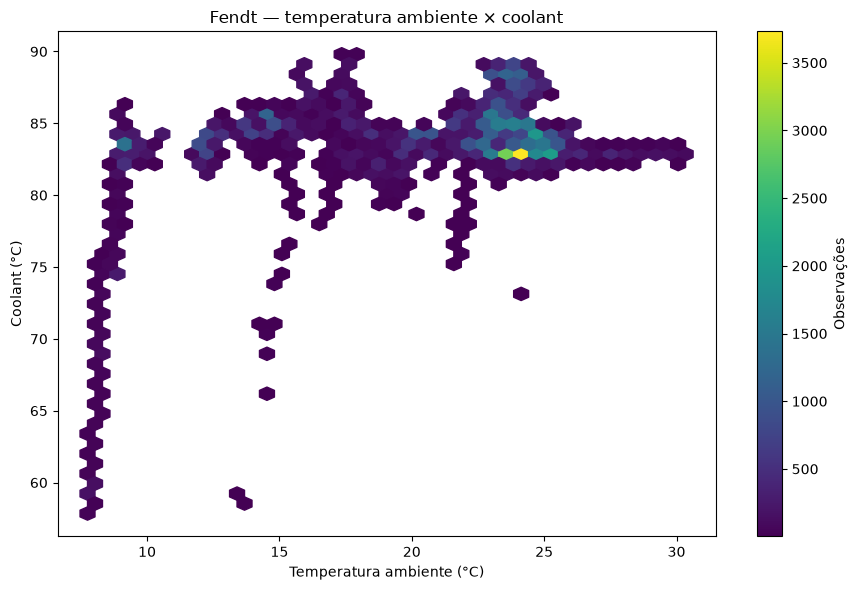

In [46]:
if (
    "coolant_temp" in df_fendt.columns
    and "ambient_temp" in df_fendt.columns
):

    df_fendt["coolant_minus_ambient_C"] = (
        df_fendt["coolant_temp"]
        - df_fendt["ambient_temp"]
    )

    display(
        df_fendt[
            [
                "coolant_temp",
                "ambient_temp",
                "coolant_minus_ambient_C"
            ]
        ].describe().T
    )

    amostra = df_fendt[
        [
            "ambient_temp",
            "coolant_temp"
        ]
    ].dropna()

    if len(amostra) > 80_000:
        amostra = amostra.sample(
            80_000,
            random_state=42
        )

    plt.figure(figsize=(9, 6))
    plt.hexbin(
        amostra["ambient_temp"],
        amostra["coolant_temp"],
        gridsize=40,
        mincnt=1
    )
    plt.xlabel("Temperatura ambiente (°C)")
    plt.ylabel("Coolant (°C)")
    plt.title("Fendt — temperatura ambiente × coolant")
    plt.colorbar(label="Observações")
    plt.tight_layout()
    plt.show()

else:
    print(
        "Coolant e/ou temperatura ambiente não foram "
        "encontrados nos arquivos selecionados."
    )

## 8.9 — Relações térmicas no Fendt

As relações são avaliadas apenas quando o sinal está disponível.

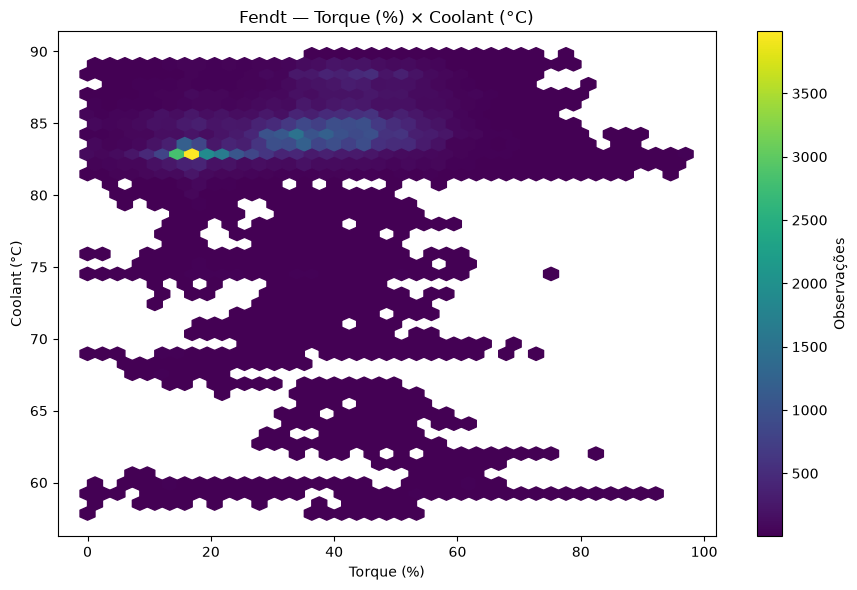

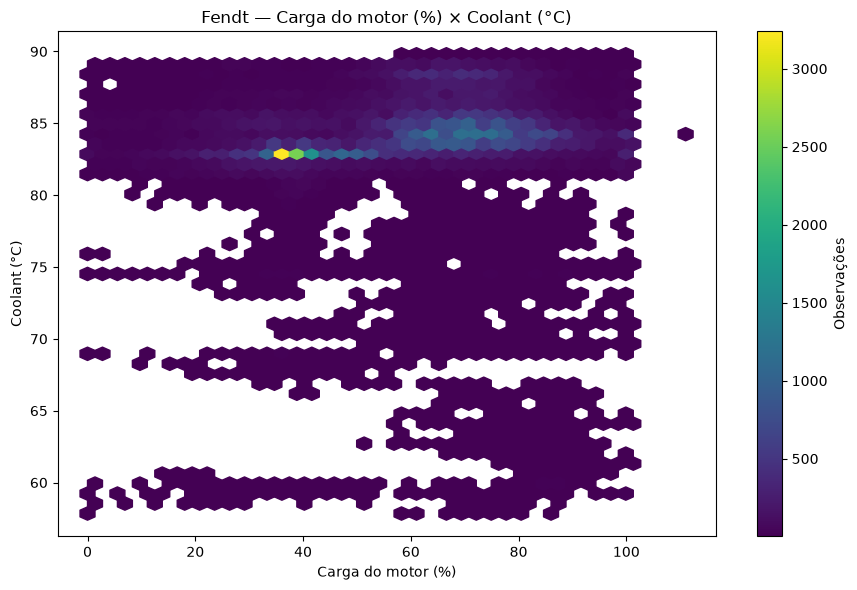

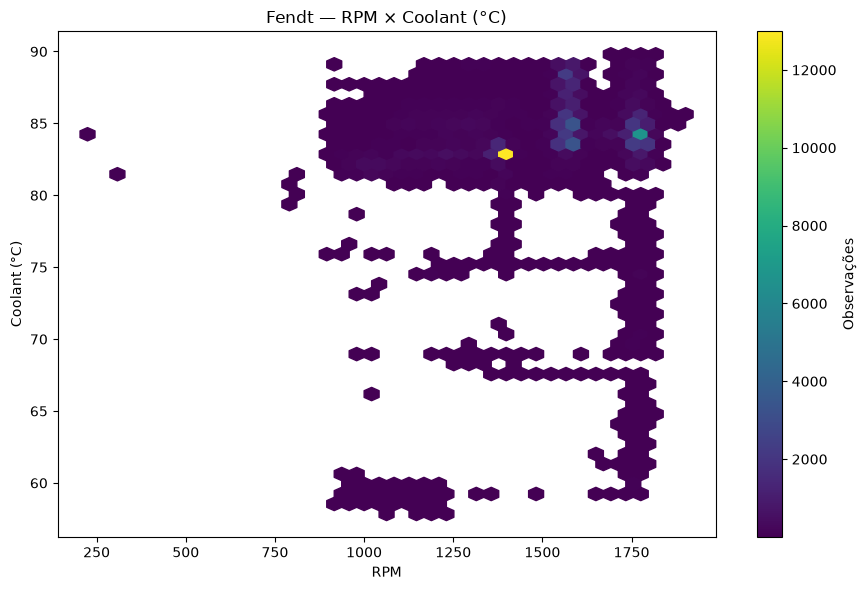

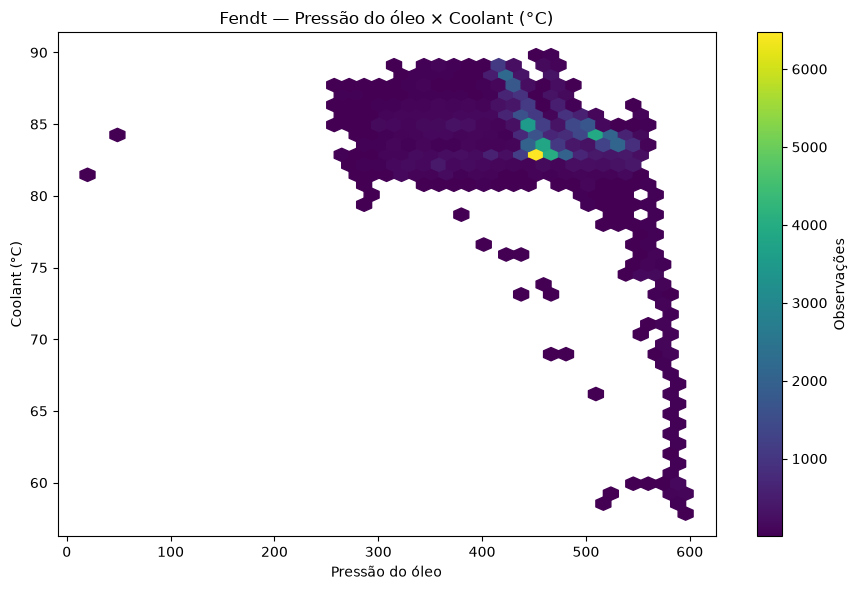

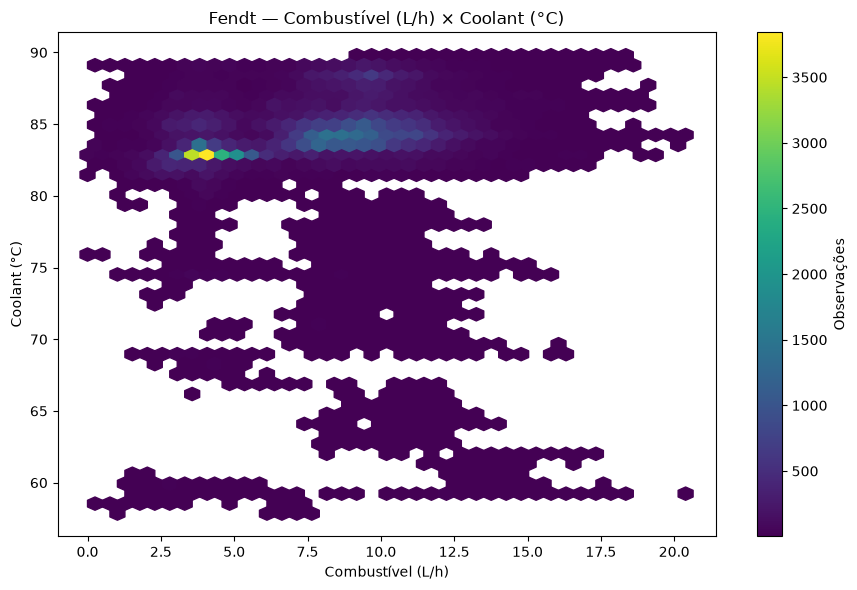

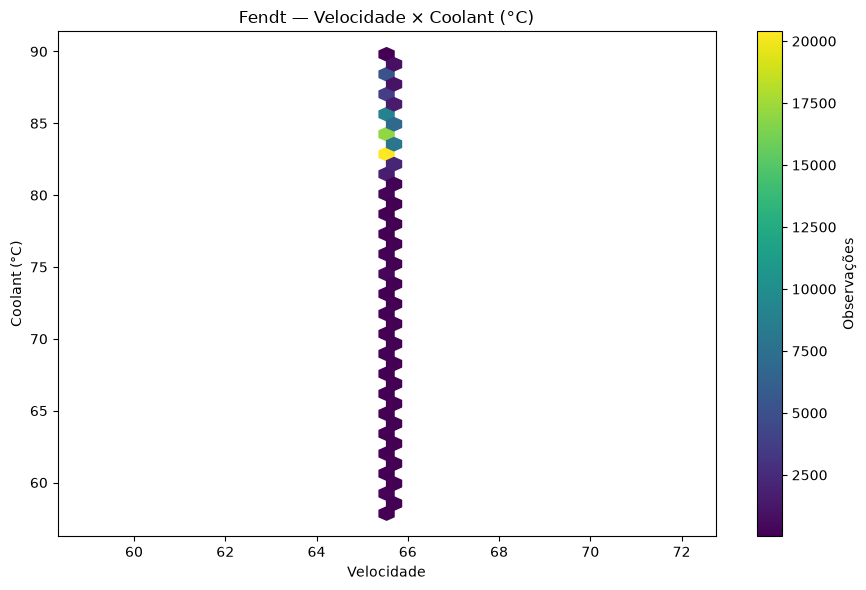

In [47]:
pares_fendt = [
    ("torque_pct", "coolant_temp", "Torque (%)", "Coolant (°C)"),
    ("engine_load_pct", "coolant_temp", "Carga do motor (%)", "Coolant (°C)"),
    ("engine_speed", "coolant_temp", "RPM", "Coolant (°C)"),
    ("oil_pressure", "coolant_temp", "Pressão do óleo", "Coolant (°C)"),
    ("fuel_rate", "coolant_temp", "Combustível (L/h)", "Coolant (°C)"),
    ("vehicle_speed", "coolant_temp", "Velocidade", "Coolant (°C)")
]

for x, y, xlabel, ylabel in pares_fendt:

    if (
        x not in df_fendt.columns
        or y not in df_fendt.columns
    ):
        continue

    dados = df_fendt[
        [x, y]
    ].dropna()

    if len(dados) == 0:
        continue

    if len(dados) > 80_000:
        dados = dados.sample(
            80_000,
            random_state=42
        )

    plt.figure(figsize=(9, 6))
    plt.hexbin(
        dados[x],
        dados[y],
        gridsize=40,
        mincnt=1
    )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(f"Fendt — {xlabel} × {ylabel}")
    plt.colorbar(label="Observações")
    plt.tight_layout()
    plt.show()

## 8.10 — Correlação Fendt

A correlação é utilizada como associação exploratória e não como prova causal.

,coolant_temp,ambient_temp,torque_pct,engine_load_pct,engine_speed,oil_pressure,fuel_rate,reference_torque,vehicle_speed
coolant_temp,1.00,0.35,0.17,0.11,0.15,-0.40,0.18,NaN,NaN
ambient_temp,0.35,1.00,-0.06,-0.05,-0.22,-0.39,-0.13,NaN,NaN
torque_pct,0.17,-0.06,1.00,0.93,0.54,0.19,0.89,NaN,NaN
engine_load_pct,0.11,-0.05,0.93,1.00,0.62,0.34,0.82,NaN,NaN
engine_speed,0.15,-0.22,0.54,0.62,1.00,0.71,0.75,NaN,NaN
oil_pressure,-0.40,-0.39,0.19,0.34,0.71,1.00,0.35,NaN,NaN
fuel_rate,0.18,-0.13,0.89,0.82,0.75,0.35,1.00,NaN,NaN
reference_torque,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_speed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


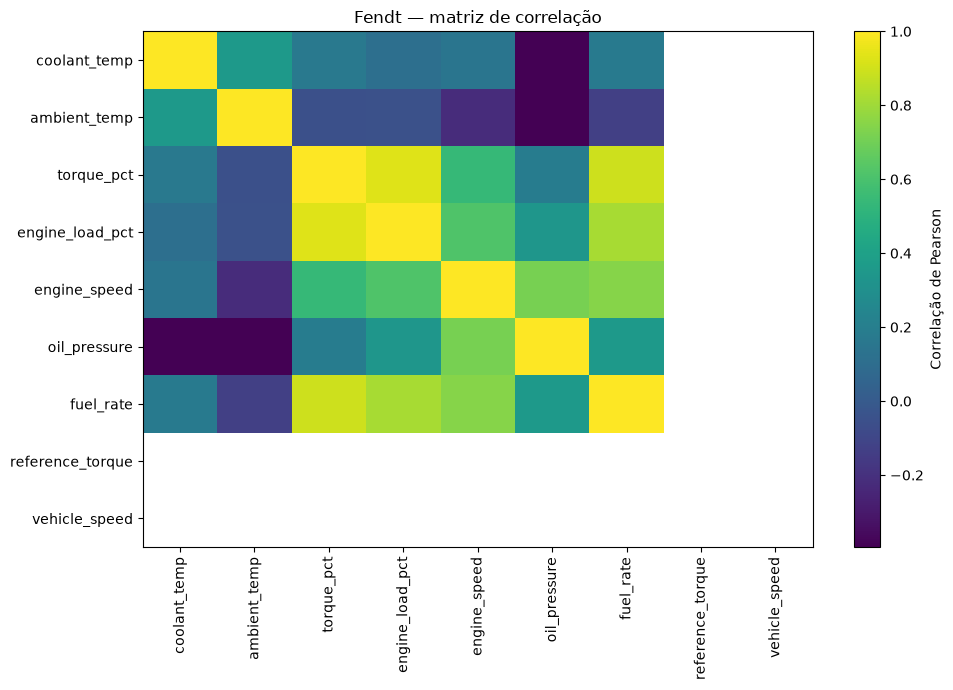

In [48]:
if len(fendt_numericas) >= 2:
    correlacao_fendt = (
        df_fendt[fendt_numericas]
        .corr()
    )

    display(correlacao_fendt)

    plt.figure(figsize=(10, 7))

    img = plt.imshow(
        correlacao_fendt.values,
        aspect="auto"
    )

    plt.xticks(
        range(len(fendt_numericas)),
        fendt_numericas,
        rotation=90
    )

    plt.yticks(
        range(len(fendt_numericas)),
        fendt_numericas
    )

    plt.colorbar(
        img,
        label="Correlação de Pearson"
    )

    plt.title(
        "Fendt — matriz de correlação"
    )

    plt.tight_layout()
    plt.show()

## 8.11 — Conclusão do Passo 8

A base Fendt funciona como **validação externa de domínio**, não como extensão artificial do Tümosan.

O objetivo é verificar se os mesmos conceitos aparecem em outro equipamento:

- condição térmica;
- carga/torque;
- RPM;
- pressão de óleo;
- consumo;
- velocidade;
- condição ambiental.

Se essas famílias de sinais também forem informativas no Fendt, teremos maior justificativa
para tratá-las como variáveis gerais do problema de risco térmico agrícola.

Os valores absolutos, entretanto, não devem ser transferidos diretamente entre tratores.

## 8.11.1 — O que a validação Fendt confirma e o que não confirma

A base Fendt é uma **replicação de conceitos**, não uma calibração direta do Tümosan. O resultado é considerado favorável quando as famílias semânticas de sinais aparecem e apresentam comportamento analisável em outro conjunto agrícola real.

Isso aumenta a confiança de que coolant, carga/torque, RPM, óleo, consumo, velocidade e ambiente são variáveis tecnicamente pertinentes ao domínio. Porém:

- valores absolutos de temperatura, torque e pressão não devem ser transferidos entre tratores;
- diferenças de arquitetura, potência, implemento e clima precisam permanecer identificadas;
- uma coluna ausente no arquivo não pode ser criada por alias ou preenchimento.

Assim, a Fendt reduz o risco de escolher features específicas demais de um único equipamento, mas não transforma as três bases em uma frota homogênea nem cria rótulos de falha.

In [49]:
disponibilidade_fendt.to_csv(
    EDA_OUTPUT_PATH / "fendt_disponibilidade_variaveis.csv",
    index=False
)

qualidade_fendt.to_csv(
    EDA_OUTPUT_PATH / "fendt_qualidade.csv",
    index=False
)

estatistica_fendt.to_csv(
    EDA_OUTPUT_PATH / "fendt_estatisticas.csv"
)

print("Resultados Fendt salvos.")

Resultados Fendt salvos.


# Passo 9 — EDA New Holland, Cenário de Superaquecimento e Conclusão das Três Bases

A terceira base utiliza um **New Holland T7.165 S** e possui duas características importantes:

1. sessões reais de trabalho agrícola, com estados operacionais rotulados manualmente;
2. cópias de uma sessão nas quais foram injetados cenários sintéticos de falha para estudos de anomalia.

Os estados reais incluem:

- `Working`;
- `Turning`;
- `Moving`;
- `Idle`.

A frequência de aquisição é **1 Hz**.

## Importante

Os cenários dentro de `anomalous_datasets/` **não são falhas reais observadas**.

Eles são alterações sintéticas aplicadas a uma sessão real e serão utilizados aqui apenas para
compreender quais variáveis se alteram em cenários plausíveis de falha.

Fonte:

https://github.com/lindiap/tractor-field-operations-dataset

## 9.1 — Inventário New Holland

In [50]:
arquivos_nh_csv = sorted(
    NEW_HOLLAND_PATH.rglob("*.csv")
)

arquivos_nh_normais = [
    arquivo
    for arquivo in arquivos_nh_csv
    if "anomalous_datasets" not in {
        parte.lower()
        for parte in arquivo.parts
    }
    and arquivo.name.lower().startswith("work-session")
]

arquivos_nh_anomalias = [
    arquivo
    for arquivo in arquivos_nh_csv
    if "case_" in arquivo.name.lower()
]

inventario_nh = pd.DataFrame([
    {
        "arquivo": arquivo.name,
        "tipo": (
            "anomalia_sintetica"
            if arquivo in arquivos_nh_anomalias
            else "sessao_real"
        ),
        "tamanho_mb": arquivo.stat().st_size / (1024**2),
        "caminho": str(arquivo.relative_to(PROJECT_ROOT))
    }
    for arquivo in (
        arquivos_nh_normais
        + arquivos_nh_anomalias
    )
])

print(
    f"Sessões reais encontradas: "
    f"{len(arquivos_nh_normais)}"
)

print(
    f"Arquivos com anomalias: "
    f"{len(arquivos_nh_anomalias)}"
)

inventario_nh

Sessões reais encontradas: 2
Arquivos com anomalias: 7


,arquivo,tipo,tamanho_mb,caminho
0,work-session1_1Hz_5h.csv,sessao_real,12.92,data/raw/new_holland/work-session1_1Hz_5h.csv
1,work-session2_1Hz_2h.csv,sessao_real,5.59,data/raw/new_holland/work-session2_1Hz_2h.csv
2,Case_1_work-session1_1Hz_2h.csv,anomalia_sintetica,3.32,data/raw/new_holland/anomalous_datasets/Case_1...
3,Case_2_work-session1_1Hz_2h.csv,anomalia_sintetica,3.30,data/raw/new_holland/anomalous_datasets/Case_2...
4,Case_3_work-session1_1Hz_2h.csv,anomalia_sintetica,3.31,data/raw/new_holland/anomalous_datasets/Case_3...
5,Case_4_work-session1_1Hz_2h.csv,anomalia_sintetica,3.30,data/raw/new_holland/anomalous_datasets/Case_4...
6,Case_5_work-session1_1Hz_2h.csv,anomalia_sintetica,3.32,data/raw/new_holland/anomalous_datasets/Case_5...
7,Case_6_work-session1_1Hz_2h.csv,anomalia_sintetica,3.30,data/raw/new_holland/anomalous_datasets/Case_6...
8,Case_7_work-session1_1Hz_2h.csv,anomalia_sintetica,3.31,data/raw/new_holland/anomalous_datasets/Case_7...


## 9.2 — Carregamento das sessões reais

In [51]:
def escolher_arquivo_por_texto(
    arquivos,
    texto
):
    candidatos = [
        arquivo
        for arquivo in arquivos
        if texto.lower() in arquivo.name.lower()
    ]

    return (
        candidatos[0]
        if candidatos
        else None
    )


nh_session1_path = escolher_arquivo_por_texto(
    arquivos_nh_normais,
    "5h"
)

nh_session2_path = escolher_arquivo_por_texto(
    arquivos_nh_normais,
    "2h"
)

if nh_session1_path is None and len(arquivos_nh_normais) >= 1:
    nh_session1_path = arquivos_nh_normais[0]

if nh_session2_path is None and len(arquivos_nh_normais) >= 2:
    nh_session2_path = arquivos_nh_normais[1]

if nh_session1_path is None or nh_session2_path is None:
    raise FileNotFoundError(
        "As duas sessões normais do New Holland não foram encontradas."
    )


df_nh_s1 = pd.read_csv(
    nh_session1_path
)

df_nh_s2 = pd.read_csv(
    nh_session2_path
)

print(
    f"Sessão 1: {df_nh_s1.shape}"
)

print(
    f"Sessão 2: {df_nh_s2.shape}"
)

Sessão 1: (17447, 103)
Sessão 2: (7304, 103)


## 9.3 — Dicionário estrutural New Holland

In [52]:
estrutura_nh = pd.DataFrame({
    "variavel": df_nh_s1.columns,
    "tipo_s1": [
        str(df_nh_s1[col].dtype)
        for col in df_nh_s1.columns
    ],
    "nulos_s1": [
        int(df_nh_s1[col].isna().sum())
        for col in df_nh_s1.columns
    ],
    "nulos_s2": [
        int(
            df_nh_s2[col].isna().sum()
        )
        if col in df_nh_s2.columns
        else np.nan
        for col in df_nh_s1.columns
    ]
})

estrutura_nh

,variavel,tipo_s1,nulos_s1,nulos_s2
0,timestamps,object,0,0
1,STATE,object,0,0
2,CAN2.gnss_time.Epoch,int64,0,0
3,CAN2.gnss_pos.Latitude,float64,0,0
4,CAN2.gnss_pos.Longitude,float64,0,0
...,...,...,...,...
98,CAN2.TSC1.EngnRqstdTrqTrqLmt_5,float64,0,0
99,CAN2.TSC1.EngineRequestedSpeedSpeedLimit_7,float64,0,0
100,CAN2.TSC1.EngnRqstdTrqTrqLmt_7,float64,0,0
101,CAN2.TSC1.TSC1ControlPurpose_7,float64,0,0


## 9.4 — Localização semântica dos principais sinais New Holland

Os nomes das colunas possuem prefixos CAN completos, por isso utilizamos aliases.

In [53]:
aliases_nh = {
    "timestamp": [
        "timestamp",
        "time"
    ],
    "operational_state": [
        "operational_state",
        "operationalstate",
        "state",
        "activity"
    ],
    "engine_speed": [
        "CAN1.EEC1.EngineSpeed",
        "EngineSpeed"
    ],
    "actual_torque_pct": [
        "CAN1.EEC1.ActualEnginePercentTorque",
        "ActualEnginePercentTorque"
    ],
    "engine_load_pct": [
        "CAN1.EEC2.EnginePercentLoadAtCurrentSpeed",
        "EnginePercentLoadAtCurrentSpeed"
    ],
    "oil_pressure": [
        "CAN1.EFLP1.EngineOilPressure1",
        "EngineOilPressure1"
    ],
    "fuel_rate": [
        "CAN1.LFE1.EngineFuelRate",
        "EngineFuelRate"
    ],
    "intake_temp": [
        "CAN1.IC1.EngnIntkMnfld1Tmprtr",
        "EngnIntkMnfld1Tmprtr",
        "EngineIntakeManifold1Temperature"
    ],
    "intake_pressure": [
        "CAN1.IC1.EngineIntakeManifold1Pressure",
        "EngineIntakeManifold1Pressure"
    ],
    "fan_speed": [
        "CAN1.FD1.FanSpeed",
        "FanSpeed",
        "EngineFan1EstimatedPercentSpeed"
    ],
    "vehicle_speed": [
        "WheelBasedVehicleSpeed",
        "GroundSpeed",
        "ground_speed"
    ],
    "hydraulic_pressure": [
        "hydraulic_pressure",
        "HydraulicPressure"
    ]
}

mapa_nh = {
    papel: localizar_coluna(
        df_nh_s1.columns,
        aliases
    )
    for papel, aliases in aliases_nh.items()
}

pd.DataFrame(
    [
        {
            "papel": papel,
            "coluna_encontrada": coluna
        }
        for papel, coluna in mapa_nh.items()
    ]
)

,papel,coluna_encontrada
0,timestamp,timestamps
1,operational_state,STATE
2,engine_speed,CAN1.EEC1.EngineSpeed
3,actual_torque_pct,CAN1.EEC1.ActualEnginePercentTorque
4,engine_load_pct,CAN1.EEC2.EnginePercentLoadAtCurrentSpeed
5,oil_pressure,CAN1.EFLP1.EngineOilPressure1
6,fuel_rate,CAN1.LFE1.EngineFuelRate
7,intake_temp,CAN1.IC1.EngnIntkMnfld1Tmprtr
8,intake_pressure,CAN1.IC1.EngineIntakeManifold1Pressure
9,fan_speed,CAN1.FD1.FanSpeed


## 9.5 — Estados operacionais reais

Se o rótulo estiver presente, será verificada a distribuição das atividades.

Essa informação é útil porque o comportamento esperado do motor depende da atividade.

In [54]:
col_estado_nh = mapa_nh.get(
    "operational_state"
)

if col_estado_nh is not None:

    estados_s1 = (
        df_nh_s1[col_estado_nh]
        .value_counts(dropna=False)
        .rename_axis("estado")
        .reset_index(name="quantidade")
    )

    estados_s2 = (
        df_nh_s2[col_estado_nh]
        .value_counts(dropna=False)
        .rename_axis("estado")
        .reset_index(name="quantidade")
    )

    print("Sessão 1")
    display(estados_s1)

    print("Sessão 2")
    display(estados_s2)

else:
    print(
        "Coluna de estado operacional não foi localizada."
    )

Sessão 1


,estado,quantidade
0,W,6214
1,I,4813
2,T,3677
3,M,2743


Sessão 2


,estado,quantidade
0,T,4535
1,W,2673
2,M,96


## 9.6 — Comportamento do motor por atividade

As medianas por estado ajudam a demonstrar que um mesmo valor de sensor pode ter
significado diferente dependendo de `Working`, `Turning`, `Moving` ou `Idle`.

In [55]:
sinais_nh_encontrados = {
    papel: coluna
    for papel, coluna in mapa_nh.items()
    if coluna is not None
    and papel not in [
        "timestamp",
        "operational_state"
    ]
}

if col_estado_nh is not None:

    cols_atividade = [
        col_estado_nh
    ] + list(
        dict.fromkeys(
            sinais_nh_encontrados.values()
        )
    )

    df_atividade = df_nh_s1[
        cols_atividade
    ].copy()

    for coluna in cols_atividade[1:]:
        df_atividade[coluna] = pd.to_numeric(
            df_atividade[coluna],
            errors="coerce"
        )

    resumo_estado_nh = (
        df_atividade
        .groupby(col_estado_nh)
        .median(
            numeric_only=True
        )
    )

    display(resumo_estado_nh)

,CAN1.EEC1.EngineSpeed,CAN1.EEC1.ActualEnginePercentTorque,CAN1.EEC2.EnginePercentLoadAtCurrentSpeed,CAN1.EFLP1.EngineOilPressure1,CAN1.LFE1.EngineFuelRate,CAN1.IC1.EngnIntkMnfld1Tmprtr,CAN1.IC1.EngineIntakeManifold1Pressure,CAN1.FD1.FanSpeed,CAN1.CCVS1.WheelBasedVehicleSpeed
STATE,,,,,,,,,
I,0.00,0.00,0.00,98.14,0.00,63.35,99.07,0.00,0.00
M,850.82,15.00,18.00,412.00,2.40,20.00,100.00,857.27,0.00
T,916.49,15.00,18.00,336.00,3.01,52.00,105.48,987.32,0.21
W,2103.87,63.08,80.00,480.00,22.72,57.00,174.53,991.99,4.07


## 9.7 — Inventário das anomalias sintéticas

O repositório contém múltiplos casos.

A análise abaixo mede:

- quais colunas foram alteradas;
- quantas linhas mudaram;
- qual a extensão temporal aproximada da alteração.

Isso é EDA do benchmark, não treinamento.

In [56]:
def comparar_dataframe_anomalo(
    df_normal,
    df_anomalo,
    nome_caso
):
    if len(df_normal) != len(df_anomalo):
        return {
            "caso": nome_caso,
            "linhas_normal": len(df_normal),
            "linhas_anomalia": len(df_anomalo),
            "mesmo_tamanho": False,
            "linhas_alteradas": np.nan,
            "colunas_alteradas": ""
        }

    compartilhadas = [
        col
        for col in df_normal.columns
        if col in df_anomalo.columns
    ]

    mascara_total = np.zeros(
        len(df_normal),
        dtype=bool
    )

    colunas_alteradas = []

    for coluna in compartilhadas:

        a = df_normal[coluna]
        b = df_anomalo[coluna]

        if (
            pd.api.types.is_numeric_dtype(a)
            and pd.api.types.is_numeric_dtype(b)
        ):
            igual = np.isclose(
                pd.to_numeric(a, errors="coerce"),
                pd.to_numeric(b, errors="coerce"),
                equal_nan=True
            )
        else:
            igual = (
                a.fillna("__NA__").astype(str)
                == b.fillna("__NA__").astype(str)
            ).to_numpy()

        diferente = ~igual

        if diferente.any():
            colunas_alteradas.append(coluna)
            mascara_total |= diferente

    return {
        "caso": nome_caso,
        "linhas_normal": len(df_normal),
        "linhas_anomalia": len(df_anomalo),
        "mesmo_tamanho": True,
        "linhas_alteradas": int(mascara_total.sum()),
        "percentual_linhas_alteradas": float(
            mascara_total.mean() * 100
        ),
        "primeira_linha_alterada": (
            int(np.flatnonzero(mascara_total)[0])
            if mascara_total.any()
            else np.nan
        ),
        "ultima_linha_alterada": (
            int(np.flatnonzero(mascara_total)[-1])
            if mascara_total.any()
            else np.nan
        ),
        "colunas_alteradas": ", ".join(
            colunas_alteradas
        )
    }


resumo_anomalias_nh = []

for arquivo in arquivos_nh_anomalias:
    df_anom = pd.read_csv(arquivo)

    resumo_anomalias_nh.append(
        comparar_dataframe_anomalo(
            df_nh_s2,
            df_anom,
            arquivo.name
        )
    )

resumo_anomalias_nh = pd.DataFrame(
    resumo_anomalias_nh
)

resumo_anomalias_nh

,caso,linhas_normal,linhas_anomalia,mesmo_tamanho,linhas_alteradas,colunas_alteradas
0,Case_1_work-session1_1Hz_2h.csv,7304,11795,False,NaN,
1,Case_2_work-session1_1Hz_2h.csv,7304,11795,False,NaN,
2,Case_3_work-session1_1Hz_2h.csv,7304,11795,False,NaN,
3,Case_4_work-session1_1Hz_2h.csv,7304,11795,False,NaN,
4,Case_5_work-session1_1Hz_2h.csv,7304,11795,False,NaN,
5,Case_6_work-session1_1Hz_2h.csv,7304,11795,False,NaN,
6,Case_7_work-session1_1Hz_2h.csv,7304,11795,False,NaN,


## 9.7.1 — Como interpretar o inventário de anomalias

A comparação normal versus anômala verifica se os arquivos têm o mesmo tamanho, quais linhas mudaram e quais colunas foram alteradas. Isso é importante para provar a proveniência do benchmark: uma alteração localizada e documentada é diferente de uma sessão naturalmente coletada com falha.

O resultado permite responder:

- o caso preservou a mesma linha do tempo da sessão normal;
- a alteração está concentrada em um intervalo identificável;
- as variáveis modificadas correspondem às regras publicadas;
- o arquivo pode ser usado como teste controlado de sensibilidade.

Mesmo que o padrão pareça plausível, ele não deve ser contado como incidente real. O benchmark avalia se o método reconhece uma perturbação sintética conhecida; não estima a frequência de incêndios nem substitui validação em falhas reais.

## 9.8 — Caso 2: cenário sintético de superaquecimento

O trabalho associado ao dataset descreve o **Caso 2 — Overheating Engine**.

O cenário foi criado durante o estado `Moving`, com duração planejada de aproximadamente 20 minutos.

As regras publicadas envolvem:

- aumento da temperatura do coletor de admissão;
- aumento da velocidade da ventoinha;
- queda da pressão do óleo;
- oscilação da rotação do motor.

Essas alterações são **sintéticas**, mas fornecem um benchmark documentado para verificar
se um futuro modelo é sensível a um padrão multivariável de falha.

In [57]:
case2_paths = [
    arquivo
    for arquivo in arquivos_nh_anomalias
    if re.search(
        r"case[_ -]?2",
        arquivo.name,
        flags=re.IGNORECASE
    )
]

CASE2_PATH = (
    case2_paths[0]
    if case2_paths
    else None
)

if CASE2_PATH is None:
    print(
        "Arquivo Case_2 não localizado."
    )
else:
    print(
        f"Case 2: {CASE2_PATH.name}"
    )

Case 2: Case_2_work-session1_1Hz_2h.csv


## 9.9 — Variáveis do cenário de superaquecimento

In [58]:
if CASE2_PATH is not None:

    df_nh_case2 = pd.read_csv(
        CASE2_PATH
    )

    mapa_case2 = {
        papel: localizar_coluna(
            df_nh_case2.columns,
            aliases_nh[papel]
        )
        for papel in [
            "intake_temp",
            "fan_speed",
            "oil_pressure",
            "engine_speed"
        ]
    }

    pd.DataFrame([
        {
            "papel": papel,
            "normal": mapa_nh.get(papel),
            "case_2": mapa_case2.get(papel)
        }
        for papel in mapa_case2
    ])

## 9.10 — Normal × superaquecimento sintético

A comparação é realizada somente nas quatro variáveis descritas pelo cenário publicado.

In [59]:
comparacao_case2 = []

if CASE2_PATH is not None:

    for papel in [
        "intake_temp",
        "fan_speed",
        "oil_pressure",
        "engine_speed"
    ]:

        col_normal = mapa_nh.get(papel)
        col_case = mapa_case2.get(papel)

        if (
            col_normal is None
            or col_case is None
        ):
            continue

        normal = pd.to_numeric(
            df_nh_s2[col_normal],
            errors="coerce"
        )

        anomalo = pd.to_numeric(
            df_nh_case2[col_case],
            errors="coerce"
        )

        comparacao_case2.append({
            "variavel_semantica": papel,
            "normal_media": normal.mean(),
            "normal_mediana": normal.median(),
            "normal_min": normal.min(),
            "normal_max": normal.max(),
            "case2_media": anomalo.mean(),
            "case2_mediana": anomalo.median(),
            "case2_min": anomalo.min(),
            "case2_max": anomalo.max()
        })

comparacao_case2 = pd.DataFrame(
    comparacao_case2
)

comparacao_case2

,variavel_semantica,normal_media,normal_mediana,normal_min,normal_max,case2_media,case2_mediana,case2_min,case2_max
0,intake_temp,51.80,52.00,40.00,64.00,56.79,56.00,40.00,140.00
1,fan_speed,936.99,938.74,379.33,2146.19,641.68,824.68,0.00,4997.26
2,oil_pressure,391.19,388.62,256.00,519.80,279.62,292.45,0.14,519.80
3,engine_speed,1400.25,1300.62,747.50,2179.79,898.89,851.50,0.00,2198.38


## 9.10.1 — Leitura da comparação normal × Caso 2

A tabela compara estatísticas descritivas das quatro variáveis alteradas no cenário publicado: temperatura de admissão, ventoinha, pressão do óleo e rotação.

O valor desta comparação é verificar se a alteração sintética aparece como um **padrão multivariável coerente**: aumento térmico acompanhado por resposta da refrigeração, alteração de lubrificação e oscilação de regime. Nenhuma dessas diferenças deve ser interpretada isoladamente como prova de incêndio.

A comparação é relevante para o futuro ML porque fornece um teste de sensibilidade com causa conhecida no arquivo: o algoritmo deve perceber mudança de comportamento, mas o relatório deve rotular o resultado como `anomalia_sintetica_case2`. Isso mantém separadas três categorias que não podem ser misturadas: operação normal real, anomalia sintética e falha real rotulada.

## 9.11 — Localização automática do intervalo alterado no Caso 2

Como a frequência é 1 Hz, o número de linhas modificadas pode ser interpretado aproximadamente
em segundos quando a alteração é contínua.

A análise abaixo detecta onde as quatro variáveis do cenário deixam de ser iguais à sessão normal.

In [60]:
case2_alinhado = pd.DataFrame()
inicio_case2 = None
fim_case2 = None

if CASE2_PATH is not None:

    col_tempo_normal = localizar_coluna(
        df_nh_s2.columns,
        aliases_nh["timestamp"]
    )
    col_tempo_case = localizar_coluna(
        df_nh_case2.columns,
        aliases_nh["timestamp"]
    )

    papeis_case2 = [
        "intake_temp",
        "fan_speed",
        "oil_pressure",
        "engine_speed"
    ]

    colunas_normal = {
        papel: mapa_nh.get(papel)
        for papel in papeis_case2
    }
    colunas_case = {
        papel: mapa_case2.get(papel)
        for papel in papeis_case2
    }

    papeis_completos = [
        papel
        for papel in papeis_case2
        if colunas_normal[papel] is not None
        and colunas_case[papel] is not None
    ]

    if col_tempo_normal is not None and col_tempo_case is not None:
        normal_alinhado = df_nh_s2[
            [col_tempo_normal]
            + [colunas_normal[papel] for papel in papeis_completos]
        ].copy()

        case_alinhado = df_nh_case2[
            [col_tempo_case]
            + [colunas_case[papel] for papel in papeis_completos]
        ].copy()

        normal_alinhado = normal_alinhado.rename(
            columns={col_tempo_normal: "timestamps"}
        )
        case_alinhado = case_alinhado.rename(
            columns={col_tempo_case: "timestamps"}
        )

        normal_alinhado["timestamps"] = pd.to_datetime(
            normal_alinhado["timestamps"]
        )
        case_alinhado["timestamps"] = pd.to_datetime(
            case_alinhado["timestamps"]
        )

        normal_alinhado = normal_alinhado.rename(
            columns={
                colunas_normal[papel]: f"{papel}_normal"
                for papel in papeis_completos
            }
        )
        case_alinhado = case_alinhado.rename(
            columns={
                colunas_case[papel]: f"{papel}_case2"
                for papel in papeis_completos
            }
        )

        case2_alinhado = normal_alinhado.merge(
            case_alinhado,
            on="timestamps",
            how="inner"
        ).sort_values("timestamps").reset_index(drop=True)

        mascaras_case2 = []

        for papel in papeis_completos:
            a = pd.to_numeric(
                case2_alinhado[f"{papel}_normal"],
                errors="coerce"
            )
            b = pd.to_numeric(
                case2_alinhado[f"{papel}_case2"],
                errors="coerce"
            )
            mascaras_case2.append(
                ~np.isclose(
                    a.to_numpy(),
                    b.to_numpy(),
                    equal_nan=True
                )
            )

        if mascaras_case2:
            mask_case2 = np.logical_or.reduce(mascaras_case2)
            indices_case2 = np.flatnonzero(mask_case2)

            if len(indices_case2) > 0:
                inicio_case2 = int(indices_case2.min())
                fim_case2 = int(indices_case2.max())
                inicio_timestamp_case2 = case2_alinhado.loc[
                    inicio_case2, "timestamps"
                ]
                fim_timestamp_case2 = case2_alinhado.loc[
                    fim_case2, "timestamps"
                ]
                duracao_aprox_s = (
                    fim_timestamp_case2
                    - inicio_timestamp_case2
                ).total_seconds() + 1

                print(
                    f"Primeiro timestamp alterado: "
                    f"{inicio_timestamp_case2}"
                )
                print(
                    f"Último timestamp alterado: "
                    f"{fim_timestamp_case2}"
                )
                print(
                    f"Duração aproximada: "
                    f"{duracao_aprox_s / 60:.2f} min"
                )

                if col_estado_nh is not None:
                    estados_intervalo = (
                        df_nh_case2
                        .loc[
                            df_nh_case2[col_tempo_case].isin(
                                case2_alinhado.loc[
                                    inicio_case2:fim_case2,
                                    "timestamps"
                                ]
                            ),
                            col_estado_nh
                        ]
                        .value_counts()
                    )
                    print()
                    print(
                        "Estados operacionais "
                        "durante o intervalo:"
                    )
                    print(estados_intervalo)
            else:
                print("Nenhuma alteração foi encontrada no trecho temporal comum.")
    else:
        print("Coluna temporal não localizada para alinhar o Caso 2.")

Nenhuma alteração foi encontrada no trecho temporal comum.


## 9.12 — Visualização do Caso 2

Os gráficos mostram a sessão real e a versão sinteticamente alterada.

Eles servem para documentar visualmente o que significa um cenário multivariável de falha.

### Nota de rastreabilidade do Caso 2

A comparação foi alinhada por `timestamps`, e não por posição de linha. Na execução atual, o trecho temporal comum com a sessão normal local não apresentou diferenças nas quatro variáveis selecionadas. Isso significa que o arquivo `Case_2` não deve ser apresentado como uma alteração pareada desta sessão sem localizar a sessão normal de referência usada pelos autores.

Esse resultado é uma evidência de qualidade, não uma falha a ser escondida: ele impede que diferenças causadas por deslocamento temporal ou por arquivos de sessões distintas sejam rotuladas como superaquecimento. Até que a referência correta seja identificada, o Caso 2 fica documentado como benchmark sintético disponível, mas não como comparação quantitativa validada neste notebook.

In [61]:
if (
    CASE2_PATH is not None
    and not case2_alinhado.empty
    and inicio_case2 is not None
    and fim_case2 is not None
):

    margem = 180

    inicio_plot = max(
        0,
        inicio_case2 - margem
    )

    fim_plot = min(
        len(case2_alinhado),
        fim_case2 + margem
    )

    for papel in [
        "intake_temp",
        "fan_speed",
        "oil_pressure",
        "engine_speed"
    ]:

        coluna_normal = f"{papel}_normal"
        coluna_case = f"{papel}_case2"

        if (
            coluna_normal not in case2_alinhado.columns
            or coluna_case not in case2_alinhado.columns
        ):
            continue

        dados_plot = case2_alinhado.iloc[
            inicio_plot:fim_plot
        ]

        eixo_x = (
            dados_plot["timestamps"]
            - dados_plot["timestamps"].iloc[0]
        ).dt.total_seconds() / 60.0

        plt.figure(
            figsize=(13, 5)
        )

        plt.plot(
            eixo_x,
            pd.to_numeric(
                dados_plot[coluna_normal],
                errors="coerce"
            ),
            label="Sessão real"
        )

        plt.plot(
            eixo_x,
            pd.to_numeric(
                dados_plot[coluna_case],
                errors="coerce"
            ),
            label="Caso 2 sintético"
        )

        plt.title(
            f"New Holland — Caso 2 — {papel}"
        )

        plt.xlabel(
            "Tempo relativo no trecho comum (min)"
        )

        plt.ylabel(
            papel
        )

        plt.legend()
        plt.tight_layout()
        plt.show()

# 9.13 — Comparação conceitual das três bases

As três fontes possuem papéis complementares:

### Tümosan

**Ponto forte:** alta resolução e sinais térmicos diretos.

Ajuda a responder:

> Como temperatura, óleo, torque, RPM e combustível se comportam em operações agrícolas reais de alta carga?

### Fendt

**Ponto forte:** diversidade de tratores/implementos e temperatura ambiente.

Ajuda a responder:

> As famílias de variáveis escolhidas continuam fazendo sentido em outros tratores e contextos agrícolas?

### New Holland

**Ponto forte:** estados operacionais reais e benchmark de anomalias.

Ajuda a responder:

> Como o comportamento multivariável se modifica em cenários específicos de falha, incluindo um cenário documentado de superaquecimento?

As bases **não serão concatenadas como se fossem uma única frota homogênea**.

In [62]:
comparacao_bases = pd.DataFrame([
    {
        "conceito": "Temperatura do coolant",
        "Tümosan": "SIM",
        "Fendt": (
            "SIM"
            if "coolant_temp" in df_fendt.columns
            and df_fendt["coolant_temp"].notna().any()
            else "NÃO IDENTIFICADO"
        ),
        "New Holland": "não é o sinal central do Caso 2"
    },
    {
        "conceito": "Temperatura ambiente",
        "Tümosan": "NÃO",
        "Fendt": (
            "SIM"
            if "ambient_temp" in df_fendt.columns
            and df_fendt["ambient_temp"].notna().any()
            else "NÃO IDENTIFICADO"
        ),
        "New Holland": "não utilizada como principal"
    },
    {
        "conceito": "RPM",
        "Tümosan": "SIM",
        "Fendt": (
            "SIM"
            if "engine_speed" in df_fendt.columns
            and df_fendt["engine_speed"].notna().any()
            else "NÃO IDENTIFICADO"
        ),
        "New Holland": (
            "SIM"
            if mapa_nh.get("engine_speed")
            else "NÃO IDENTIFICADO"
        )
    },
    {
        "conceito": "Torque / carga",
        "Tümosan": "SIM",
        "Fendt": (
            "SIM"
            if (
                "torque_pct" in df_fendt.columns
                or "engine_load_pct" in df_fendt.columns
            )
            else "NÃO IDENTIFICADO"
        ),
        "New Holland": (
            "SIM"
            if (
                mapa_nh.get("actual_torque_pct")
                or mapa_nh.get("engine_load_pct")
            )
            else "NÃO IDENTIFICADO"
        )
    },
    {
        "conceito": "Pressão do óleo",
        "Tümosan": "SIM",
        "Fendt": (
            "SIM"
            if "oil_pressure" in df_fendt.columns
            and df_fendt["oil_pressure"].notna().any()
            else "NÃO IDENTIFICADO"
        ),
        "New Holland": (
            "SIM"
            if mapa_nh.get("oil_pressure")
            else "NÃO IDENTIFICADO"
        )
    },
    {
        "conceito": "Combustível",
        "Tümosan": "SIM",
        "Fendt": (
            "SIM"
            if "fuel_rate" in df_fendt.columns
            and df_fendt["fuel_rate"].notna().any()
            else "NÃO IDENTIFICADO"
        ),
        "New Holland": (
            "SIM"
            if mapa_nh.get("fuel_rate")
            else "NÃO IDENTIFICADO"
        )
    },
    {
        "conceito": "Velocidade",
        "Tümosan": "SIM",
        "Fendt": (
            "SIM"
            if "vehicle_speed" in df_fendt.columns
            and df_fendt["vehicle_speed"].notna().any()
            else "NÃO IDENTIFICADO"
        ),
        "New Holland": (
            "SIM"
            if mapa_nh.get("vehicle_speed")
            else "NÃO IDENTIFICADO"
        )
    },
    {
        "conceito": "Velocidade/estado da ventoinha",
        "Tümosan": "NÃO",
        "Fendt": "depende do trator/sinal",
        "New Holland": (
            "SIM"
            if mapa_nh.get("fan_speed")
            else "NÃO IDENTIFICADO"
        )
    },
    {
        "conceito": "Estado operacional rotulado",
        "Tümosan": "operação conhecida por FIELD",
        "Fendt": "operação conhecida por pasta/implemento",
        "New Holland": (
            "SIM"
            if col_estado_nh is not None
            else "NÃO IDENTIFICADO"
        )
    }
])

comparacao_bases

,conceito,Tümosan,Fendt,New Holland
0,Temperatura do coolant,SIM,SIM,não é o sinal central do Caso 2
1,Temperatura ambiente,NÃO,SIM,não utilizada como principal
2,RPM,SIM,SIM,SIM
3,Torque / carga,SIM,SIM,SIM
4,Pressão do óleo,SIM,SIM,SIM
5,Combustível,SIM,SIM,SIM
6,Velocidade,SIM,SIM,SIM
7,Velocidade/estado da ventoinha,NÃO,depende do trator/sinal,SIM
8,Estado operacional rotulado,operação conhecida por FIELD,operação conhecida por pasta/implemento,SIM


# 9.14 — Features recomendadas para o responsável pelo Machine Learning

Depois do EDA das três bases, a recomendação não é entregar uma lista de sensores aleatória.

As features devem ser organizadas em camadas.

## Camada 1 — Estado térmico

Prioridade alta:

- temperatura do coolant;
- temperatura do óleo;
- temperatura do coletor de admissão, quando disponível;
- diferença entre temperatura do motor e ambiente, quando disponível.

## Camada 2 — Esforço e regime

Prioridade alta:

- torque;
- carga percentual;
- RPM;
- potência estimada;
- consumo de combustível.

## Camada 3 — Lubrificação e refrigeração

Prioridade alta:

- pressão do óleo;
- velocidade/estado da ventoinha, quando disponível.

## Camada 4 — Contexto operacional

- velocidade do trator;
- estado operacional;
- tipo de implemento/operação;
- PTO;
- posição do engate.

## Camada 5 — Histórico temporal

O ML deverá considerar não apenas o valor atual, mas também:

- médias móveis;
- máximos móveis;
- taxa de aumento da temperatura;
- tempo contínuo sob carga;
- variação de RPM;
- variação de torque;
- diferença temporal entre esforço e resposta térmica.

Essas features deverão ser calculadas respeitando as sessões e sem misturar passado e futuro.

In [63]:
handoff_ml = pd.DataFrame([
    {
        "feature_semantica": "temperatura_coolant",
        "prioridade": "ALTA",
        "familia": "estado térmico",
        "justificativa": "Estado direto do sistema de arrefecimento"
    },
    {
        "feature_semantica": "temperatura_oleo",
        "prioridade": "ALTA",
        "familia": "estado térmico",
        "justificativa": "Complementa o estado térmico e lubrificação"
    },
    {
        "feature_semantica": "temperatura_ambiente",
        "prioridade": "MÉDIA/ALTA",
        "familia": "ambiente",
        "justificativa": "Contextualiza capacidade de dissipação térmica; presente no Fendt"
    },
    {
        "feature_semantica": "torque_ou_carga",
        "prioridade": "ALTA",
        "familia": "esforço",
        "justificativa": "Representa demanda mecânica aplicada ao motor"
    },
    {
        "feature_semantica": "rpm",
        "prioridade": "ALTA",
        "familia": "regime",
        "justificativa": "Caracteriza ponto de funcionamento do motor"
    },
    {
        "feature_semantica": "pressao_oleo",
        "prioridade": "ALTA",
        "familia": "lubrificação",
        "justificativa": "Presente nas três abordagens e alterada no cenário de superaquecimento NH"
    },
    {
        "feature_semantica": "fuel_rate",
        "prioridade": "ALTA",
        "familia": "demanda energética",
        "justificativa": "Proxy de esforço/consumo energético"
    },
    {
        "feature_semantica": "velocidade_trator",
        "prioridade": "MÉDIA",
        "familia": "contexto operacional",
        "justificativa": "Ajuda a diferenciar trabalho, deslocamento e manobra"
    },
    {
        "feature_semantica": "fan_speed",
        "prioridade": "ALTA quando disponível",
        "familia": "refrigeração",
        "justificativa": "Resposta direta do sistema de refrigeração; relevante no cenário NH"
    },
    {
        "feature_semantica": "estado_operacional",
        "prioridade": "ALTA",
        "familia": "contexto",
        "justificativa": "O mesmo sinal deve ser interpretado conforme Working/Turning/Moving/Idle"
    },
    {
        "feature_semantica": "features_temporais",
        "prioridade": "ALTA",
        "familia": "histórico",
        "justificativa": "Risco térmico depende de tendência e duração, não apenas do valor instantâneo"
    }
])

handoff_ml

,feature_semantica,prioridade,familia,justificativa
0,temperatura_coolant,ALTA,estado térmico,Estado direto do sistema de arrefecimento
1,temperatura_oleo,ALTA,estado térmico,Complementa o estado térmico e lubrificação
2,temperatura_ambiente,MÉDIA/ALTA,ambiente,Contextualiza capacidade de dissipação térmica...
3,torque_ou_carga,ALTA,esforço,Representa demanda mecânica aplicada ao motor
4,rpm,ALTA,regime,Caracteriza ponto de funcionamento do motor
5,pressao_oleo,ALTA,lubrificação,Presente nas três abordagens e alterada no cen...
6,fuel_rate,ALTA,demanda energética,Proxy de esforço/consumo energético
7,velocidade_trator,MÉDIA,contexto operacional,"Ajuda a diferenciar trabalho, deslocamento e m..."
8,fan_speed,ALTA quando disponível,refrigeração,Resposta direta do sistema de refrigeração; re...
9,estado_operacional,ALTA,contexto,O mesmo sinal deve ser interpretado conforme W...


# 9.15 — Limitações que devem acompanhar qualquer modelo

O responsável pelo ML deverá manter estas limitações explícitas:

1. **Tümosan não contém falha térmica real rotulada.**
2. **New Holland possui falhas sinteticamente injetadas, não incidentes reais.**
3. **Os tratores possuem arquiteturas, potências e implementos diferentes.**
4. **Não é correto criar um limite universal de temperatura a partir destas bases.**
5. **As três bases não devem ser concatenadas sem harmonização técnica das unidades e sinais.**
6. **O split de treino/teste deve respeitar tempo, sessão e equipamento.**
7. **Correlação observada no EDA não implica causalidade.**
8. **O objetivo técnico defensável é antecipar comportamento térmico anormal e não declarar que um incêndio ocorrerá.**

# Conclusão Geral do EDA

O EDA demonstrou que a análise de risco térmico em tratores precisa ser multivariável.

A temperatura é o sinal de estado mais evidente, porém seu comportamento depende do contexto:

**estado térmico + esforço + regime do motor + lubrificação/refrigeração + ambiente + tempo**

A combinação das três bases resolve lacunas diferentes:

- **Tümosan:** profundidade temporal e térmica em operações reais de alta carga;
- **Fendt:** validação em outros tratores e presença de temperatura ambiente;
- **New Holland:** estados operacionais e benchmark sintético de anomalias específicas.

O resultado entregue ao Machine Learning não é um “score genérico”, mas uma especificação
técnica de quais sinais devem ser usados e por quê.

O próximo responsável poderá então desenvolver modelos de:

- previsão térmica;
- detecção de anomalias;
- classificação de cenários de falha;

sempre mantendo separada a diferença entre **comportamento real observado** e **anomalias sintéticas de teste**.

## Conclusão auditável: o que foi validado

O conjunto de evidências deste notebook sustenta as seguintes afirmações:

1. **Proveniência:** os arquivos, fontes, sessões, operações e implementos foram identificados antes da análise.
2. **Integridade estrutural:** o Tümosan foi conferido contra a documentação, mantendo esquema, contagem e frequência temporal por sessão.
3. **Qualidade observável:** nulos, duplicatas, gaps, constantes, categorias e faixas físicas foram medidos e não ocultados.
4. **Semântica:** as variáveis usadas foram relacionadas ao README, às unidades e ao papel físico no motor.
5. **Coerência temporal:** o comportamento foi analisado com sessão preservada e com defasagens compatíveis com a inércia térmica.
6. **Validação de domínio:** a Fendt verifica se as famílias de sinais também aparecem em outros tratores, sem transferir valores absolutos.
7. **Rótulos honestos:** o Tümosan não tem falhas térmicas reais rotuladas e o New Holland contém alterações sintéticas explicitamente marcadas.

Portanto, o EDA não prova que todos os registros são perfeitos nem que um incêndio pode ser previsto. Ele prova algo mais básico e necessário: **as decisões de uso, exclusão, tratamento e interpretação dos dados são rastreáveis, justificadas e proporcionais às evidências disponíveis**. Essa é a base para afirmar que o ML não está aprendendo de colunas inventadas, sessões misturadas ou anomalias sintéticas apresentadas como incidentes reais.

### Critério de aprovação para a próxima etapa

Uma feature só deve entrar no primeiro modelo quando tiver: origem identificada, unidade conhecida, cobertura mensurada, regra de qualidade definida, interpretação física plausível e estratégia de validação sem vazamento temporal ou entre sessões.

## 9.16 — Exportação final do handoff

In [64]:
print("EDA concluído em memória.")
print("Os DataFrames serão carregados diretamente no Oracle na próxima célula.")
print("Nenhum CSV intermediário é necessário para a carga do banco.")

EDA concluído em memória.
Os DataFrames serão carregados diretamente no Oracle na próxima célula.
Nenhum CSV intermediário é necessário para a carga do banco.


# Passo 10 — Classificação Exploratória e Persistência Otimizada no Oracle

Esta seção foi reestruturada para evitar que a execução cotidiana do notebook
reprocesse e reinsira centenas de milhares de linhas desnecessariamente.

## Por que a versão anterior demorava?

Os principais gargalos eram:

1. cópias grandes dos DataFrames apenas para calcular o risco;
2. `rank(pct=True)` em várias colunas de centenas de milhares de registros;
3. montagem dos registros do Oracle linha por linha em Python;
4. criação de um `datetime` artificial para cada `time_ms` do Tümosan;
5. exclusão e reinserção de sessões inteiras mesmo quando nada havia mudado.

## Estratégia nova

- usar somente um **DataFrame canônico compacto** por base;
- calcular os percentis necessários diretamente, sem criar ranks;
- manter os dados de EDA na frequência original;
- persistir no Oracle em **1 Hz por padrão** para API/dashboard;
- preservar `LINHA_ORIGEM` para rastreabilidade;
- detectar mudanças por **fingerprint de sessão**;
- pular sessões que já estão sincronizadas;
- atualizar somente o risco quando a fórmula mudar;
- preparar os lotes de inserção de forma vetorizada;
- usar `executemany()` em lotes maiores.

> O modo de 1 Hz reduz aproximadamente 10 vezes a quantidade de registros
> persistidos do Tümosan e do Fendt. Os dados brutos/EDA continuam intactos em 10 Hz.
> Para persistência integral, altere `MODO_CARGA_ORACLE = "COMPLETA"`.

## 10.1 — Base canônica compacta

A base canônica contém somente as variáveis necessárias para comparação,
classificação exploratória e persistência.

Ela não substitui os DataFrames originais do EDA.

In [ ]:
import hashlib
import time

COLUNAS_CANONICAS = [
    "DATASET", "IDENTIFICADOR", "OPERACAO", "IMPLEMENTO",
    "ARQUIVO_ORIGEM", "LINHA_ORIGEM", "TIMESTAMP_ORIGEM", "TEMPO_MS",
    "TEMP_COOLANT_C", "TEMP_OLEO_C", "TEMP_AMBIENTE_C", "TEMP_ADMISSAO_C",
    "PRESSAO_OLEO_KPA", "TORQUE_PCT", "CARGA_MOTOR_PCT", "RPM",
    "COMBUSTIVEL_L_H", "VELOCIDADE_KMH", "VENTOINHA_PCT",
    "POSICAO_ENGATE_PCT", "DRAFT1_PCT", "DRAFT2_PCT", "TRACAO_4X4",
    "PTO_STATUS", "IMPLEMENTO_CODIGO", "ESTADO_OPERACIONAL",
    "ANOMALIA_SINTETICA",
]


def serie_numerica(df, coluna):
    if coluna is None or coluna not in df.columns:
        return pd.Series(np.nan, index=df.index, dtype="float64")
    return pd.to_numeric(df[coluna], errors="coerce")


def serie_objeto(df, coluna, padrao=None):
    if coluna is None or coluna not in df.columns:
        return pd.Series(padrao, index=df.index, dtype="object")
    return df[coluna].astype("object")


def canonicalizar_tumosan(df):
    out = pd.DataFrame(index=df.index)

    out["DATASET"] = "TUMOSAN"
    out["IDENTIFICADOR"] = "FIELD_" + df["field_id"].astype(int).astype(str)
    out["OPERACAO"] = df["operacao"].astype("object")
    out["IMPLEMENTO"] = df["implemento"].astype("object")
    out["ARQUIVO_ORIGEM"] = "TUMOSAN/FIELD_" + df["field_id"].astype(int).astype(str)

    # Criada antes de qualquer amostragem para preservar rastreabilidade.
    out["LINHA_ORIGEM"] = (df.groupby("field_id").cumcount() + 1).astype("int64")

    # time_ms é relativo. Não fabricamos datas em 1970.
    out["TIMESTAMP_ORIGEM"] = None
    out["TEMPO_MS"] = serie_numerica(df, "time_ms")

    out["TEMP_COOLANT_C"] = serie_numerica(df, "EngCoolantTemp")
    out["TEMP_OLEO_C"] = serie_numerica(df, "EngOilTemp1")
    out["TEMP_AMBIENTE_C"] = np.nan
    out["TEMP_ADMISSAO_C"] = np.nan
    out["PRESSAO_OLEO_KPA"] = serie_numerica(df, "EngOilPress")
    out["TORQUE_PCT"] = serie_numerica(df, "ActualEngine_PercTorque")
    out["CARGA_MOTOR_PCT"] = np.nan
    out["RPM"] = serie_numerica(df, "EngineSpeed")
    out["COMBUSTIVEL_L_H"] = serie_numerica(df, "EngFuelRate")
    out["VELOCIDADE_KMH"] = serie_numerica(df, "WheelBasedVehicleSpeed")
    out["VENTOINHA_PCT"] = np.nan
    out["POSICAO_ENGATE_PCT"] = serie_numerica(df, "HtcPositionSensPerc")
    out["DRAFT1_PCT"] = serie_numerica(df, "HtcDraftSens1Perc")
    out["DRAFT2_PCT"] = serie_numerica(df, "HtcDraftSens2Perc")
    out["TRACAO_4X4"] = serie_numerica(df, "TransferCaseStatus")
    out["PTO_STATUS"] = serie_numerica(df, "PTO_Status")
    out["IMPLEMENTO_CODIGO"] = serie_numerica(df, "KeypadButon")
    out["ESTADO_OPERACIONAL"] = None
    out["ANOMALIA_SINTETICA"] = None

    return out.reset_index(drop=True)


def canonicalizar_fendt(df):
    out = pd.DataFrame(index=df.index)

    out["DATASET"] = "FENDT"
    out["IDENTIFICADOR"] = df["arquivo"].astype(str)
    out["OPERACAO"] = df["operacao"].astype("object")
    out["IMPLEMENTO"] = df["operacao"].astype("object")
    out["ARQUIVO_ORIGEM"] = df["arquivo"].astype(str)
    out["LINHA_ORIGEM"] = (df.groupby("arquivo").cumcount() + 1).astype("int64")

    out["TIMESTAMP_ORIGEM"] = serie_objeto(df, "time")
    out["TEMPO_MS"] = np.nan

    out["TEMP_COOLANT_C"] = serie_numerica(df, "coolant_temp")
    out["TEMP_OLEO_C"] = np.nan
    out["TEMP_AMBIENTE_C"] = serie_numerica(df, "ambient_temp")
    out["TEMP_ADMISSAO_C"] = np.nan
    out["PRESSAO_OLEO_KPA"] = serie_numerica(df, "oil_pressure")
    out["TORQUE_PCT"] = serie_numerica(df, "torque_pct")
    out["CARGA_MOTOR_PCT"] = serie_numerica(df, "engine_load_pct")
    out["RPM"] = serie_numerica(df, "engine_speed")
    out["COMBUSTIVEL_L_H"] = serie_numerica(df, "fuel_rate")
    out["VELOCIDADE_KMH"] = serie_numerica(df, "vehicle_speed")
    out["VENTOINHA_PCT"] = np.nan
    out["POSICAO_ENGATE_PCT"] = np.nan
    out["DRAFT1_PCT"] = np.nan
    out["DRAFT2_PCT"] = np.nan
    out["TRACAO_4X4"] = np.nan
    out["PTO_STATUS"] = np.nan
    out["IMPLEMENTO_CODIGO"] = None
    out["ESTADO_OPERACIONAL"] = None
    out["ANOMALIA_SINTETICA"] = None

    return out.reset_index(drop=True)


def canonicalizar_new_holland(df, identificador, anomalia=None):
    out = pd.DataFrame(index=df.index)

    out["DATASET"] = "NEW_HOLLAND"
    out["IDENTIFICADOR"] = identificador
    out["OPERACAO"] = "anomalia_sintetica" if anomalia else "sessao_real"
    out["IMPLEMENTO"] = None
    out["ARQUIVO_ORIGEM"] = identificador
    out["LINHA_ORIGEM"] = np.arange(1, len(df) + 1, dtype="int64")

    out["TIMESTAMP_ORIGEM"] = serie_objeto(df, mapa_nh.get("timestamp"))
    out["TEMPO_MS"] = np.nan

    out["TEMP_COOLANT_C"] = np.nan
    out["TEMP_OLEO_C"] = np.nan
    out["TEMP_AMBIENTE_C"] = np.nan
    out["TEMP_ADMISSAO_C"] = serie_numerica(df, mapa_nh.get("intake_temp"))
    out["PRESSAO_OLEO_KPA"] = serie_numerica(df, mapa_nh.get("oil_pressure"))
    out["TORQUE_PCT"] = serie_numerica(df, mapa_nh.get("actual_torque_pct"))
    out["CARGA_MOTOR_PCT"] = serie_numerica(df, mapa_nh.get("engine_load_pct"))
    out["RPM"] = serie_numerica(df, mapa_nh.get("engine_speed"))
    out["COMBUSTIVEL_L_H"] = serie_numerica(df, mapa_nh.get("fuel_rate"))
    out["VELOCIDADE_KMH"] = serie_numerica(df, mapa_nh.get("vehicle_speed"))
    out["VENTOINHA_PCT"] = serie_numerica(df, mapa_nh.get("fan_speed"))

    out["POSICAO_ENGATE_PCT"] = np.nan
    out["DRAFT1_PCT"] = np.nan
    out["DRAFT2_PCT"] = np.nan
    out["TRACAO_4X4"] = np.nan
    out["PTO_STATUS"] = np.nan
    out["IMPLEMENTO_CODIGO"] = None
    out["ESTADO_OPERACIONAL"] = serie_objeto(df, mapa_nh.get("operational_state"))
    out["ANOMALIA_SINTETICA"] = anomalia

    return out.reset_index(drop=True)


inicio = time.perf_counter()

frames_canonicos = {
    "TUMOSAN": canonicalizar_tumosan(df_tumosan_all)
}

if "df_fendt" in globals() and not df_fendt.empty:
    frames_canonicos["FENDT"] = canonicalizar_fendt(df_fendt)

if "df_nh_s1" in globals() and "df_nh_s2" in globals():
    frames_canonicos["NEW_HOLLAND"] = pd.concat(
        [
            canonicalizar_new_holland(df_nh_s1, "work-session1"),
            canonicalizar_new_holland(df_nh_s2, "work-session2"),
        ],
        ignore_index=True,
    )

if (
    "df_nh_case2" in globals()
    and isinstance(df_nh_case2, pd.DataFrame)
    and not df_nh_case2.empty
):
    frames_canonicos["NEW_HOLLAND_CASE2"] = canonicalizar_new_holland(
        df_nh_case2,
        "case_2_overheating",
        anomalia="CASE_2_OVERHEATING",
    )

resumo_canonico = pd.DataFrame(
    [
        {
            "chave": chave,
            "dataset": frame["DATASET"].iloc[0],
            "linhas": len(frame),
            "sessoes": frame["IDENTIFICADOR"].nunique(),
            "memoria_mb": frame.memory_usage(deep=True).sum() / (1024**2),
        }
        for chave, frame in frames_canonicos.items()
    ]
)

print(f"Canonicalização concluída em {time.perf_counter() - inicio:.2f}s")
resumo_canonico

## 10.2 — Classificação exploratória otimizada

A regra continua sendo relativa à própria sessão, e não uma probabilidade real de incêndio.

Em vez de calcular `rank(pct=True)` para todas as linhas, são calculados apenas:

- P95 para temperatura, óleo, esforço e ventoinha;
- P05 para pressão do óleo;
- P90 térmico para a combinação com ventoinha.

In [ ]:
def flag_percentil_alto(df, coluna, q, grupo="IDENTIFICADOR"):
    if coluna not in df.columns or not df[coluna].notna().any():
        return pd.Series(False, index=df.index)

    limites = df.groupby(grupo, dropna=False)[coluna].quantile(q)
    limite_linha = df[grupo].map(limites)

    return (
        df[coluna].notna()
        & limite_linha.notna()
        & (df[coluna] >= limite_linha)
    )


def flag_percentil_baixo(df, coluna, q=0.05, grupo="IDENTIFICADOR"):
    if coluna not in df.columns or not df[coluna].notna().any():
        return pd.Series(False, index=df.index)

    limites = df.groupby(grupo, dropna=False)[coluna].quantile(q)
    limite_linha = df[grupo].map(limites)

    return (
        df[coluna].notna()
        & limite_linha.notna()
        & (df[coluna] <= limite_linha)
    )


def adicionar_risco_exploratorio_rapido(df):
    tem_coolant = df["TEMP_COOLANT_C"].notna().any()
    coluna_termica = "TEMP_COOLANT_C" if tem_coolant else "TEMP_ADMISSAO_C"

    termico_95 = flag_percentil_alto(df, coluna_termica, 0.95)
    termico_90 = flag_percentil_alto(df, coluna_termica, 0.90)
    oleo_95 = flag_percentil_alto(df, "TEMP_OLEO_C", 0.95)

    esforco_95 = (
        flag_percentil_alto(df, "TORQUE_PCT", 0.95)
        | flag_percentil_alto(df, "CARGA_MOTOR_PCT", 0.95)
        | flag_percentil_alto(df, "RPM", 0.95)
        | flag_percentil_alto(df, "COMBUSTIVEL_L_H", 0.95)
    )

    pressao_baixa_05 = flag_percentil_baixo(df, "PRESSAO_OLEO_KPA", 0.05)
    ventoinha_95 = flag_percentil_alto(df, "VENTOINHA_PCT", 0.95)
    ventoinha_termica = ventoinha_95 & termico_90
    sintetica = df["ANOMALIA_SINTETICA"].notna()

    score = (
        termico_95.astype("int16") * 45
        + oleo_95.astype("int16") * 15
        + esforco_95.astype("int16") * 20
        + pressao_baixa_05.astype("int16") * 20
        + ventoinha_termica.astype("int16") * 10
    ).astype("float32")

    score.loc[sintetica] = np.maximum(score.loc[sintetica], 60)

    df["RISCO_SCORE"] = score
    df["CLASSIFICACAO_RISCO"] = np.select(
        [score >= 80, score >= 45],
        ["CRITICO", "ALTO"],
        default="NORMAL",
    )

    # Bitmask: evita concatenação de strings linha a linha.
    codigo = (
        termico_95.astype("uint8") * 1
        + oleo_95.astype("uint8") * 2
        + esforco_95.astype("uint8") * 4
        + pressao_baixa_05.astype("uint8") * 8
        + ventoinha_termica.astype("uint8") * 16
        + sintetica.astype("uint8") * 32
    )

    bits = [
        (1, "temperatura_extrema_relativa"),
        (2, "oleo_extremo_relativo"),
        (4, "esforco_extremo"),
        (8, "pressao_oleo_baixa"),
        (16, "ventoinha_alta"),
        (32, "anomalia_sintetica"),
    ]

    mapa_motivos = {}
    for valor in range(64):
        motivos = [texto for bit, texto in bits if valor & bit]
        mapa_motivos[valor] = ";".join(motivos) if motivos else "sem_sinal_extremo"

    df["MOTIVOS_RISCO"] = codigo.map(mapa_motivos).astype("object")
    df["RISCO_ORIGEM"] = (
        "relativo_sessao_com_coolant"
        if tem_coolant
        else "proxy_operacional_sem_coolant"
    )

    return df


inicio = time.perf_counter()

for chave in frames_canonicos:
    adicionar_risco_exploratorio_rapido(frames_canonicos[chave])

resumo_risco = pd.concat(
    [
        frame.groupby(
            ["DATASET", "CLASSIFICACAO_RISCO"]
        ).size().rename("AMOSTRAS").reset_index()
        for frame in frames_canonicos.values()
    ],
    ignore_index=True,
)

resumo_risco = (
    resumo_risco
    .groupby(["DATASET", "CLASSIFICACAO_RISCO"], as_index=False)["AMOSTRAS"]
    .sum()
)

print(f"Classificação concluída em {time.perf_counter() - inicio:.2f}s")
resumo_risco

In [ ]:
contagem_risco = (
    resumo_risco
    .pivot(
        index="DATASET",
        columns="CLASSIFICACAO_RISCO",
        values="AMOSTRAS",
    )
    .fillna(0)
    .reindex(columns=["NORMAL", "ALTO", "CRITICO"], fill_value=0)
)

plt.figure(figsize=(10, 5))
contagem_risco.plot(
    kind="bar",
    stacked=True,
    ax=plt.gca(),
)
plt.title("Classificação exploratória de risco por dataset")
plt.xlabel("Dataset")
plt.ylabel("Quantidade de amostras")
plt.xticks(rotation=0)
plt.legend(title="Classificação")
plt.tight_layout()
plt.show()

contagem_risco

## 10.3 — Configuração, limpeza e seleção para o Oracle

O DataFrame do EDA **não será alterado**.

Antes da persistência será criada uma camada específica:

```text
dados brutos / EDA
        ↓
padronização semântica
        ↓
redução para 1 Hz
        ↓
limpeza conservadora
        ↓
seleção somente das variáveis importantes
        ↓
Oracle
```

### O que entra no banco

Mantemos apenas sinais diretamente úteis para análise térmica, API e futuro ML:

- temperatura do coolant;
- temperatura do óleo;
- temperatura ambiente;
- temperatura de admissão;
- pressão do óleo;
- torque/carga;
- RPM;
- consumo;
- velocidade;
- ventoinha;
- PTO;
- estado operacional;
- identificação de anomalia sintética;
- rastreabilidade temporal.

### O que NÃO entra na primeira versão

- `DRAFT1_PCT`;
- `DRAFT2_PCT`;
- posição do engate;
- estado 4x4;
- código de implemento por linha.

Essas informações já possuem contexto na sessão ou apresentaram limitações de qualidade no EDA.

### Score exploratório

Por padrão o score heurístico **não será persistido como se fosse um target real**.

Ele pode ser habilitado somente para dashboard exploratório com:

```python
INCLUIR_RISCO_EXPLORATORIO_NO_BANCO = True
```

### Frequência recomendada

```python
MODO_CARGA_ORACLE = "1HZ"
```

Os arquivos originais continuam preservados em alta frequência para o responsável pelo ML.

In [ ]:
# ============================================================
# CONFIGURAÇÃO DE PERSISTÊNCIA
# ============================================================

MODO_CARGA_ORACLE = "1HZ"
# "1HZ" ou "COMPLETA"

INCLUIR_RISCO_EXPLORATORIO_NO_BANCO = False

FORCAR_RECARREGAR_DADOS = False
FORCAR_ATUALIZAR_RISCO = False

TAMANHO_LOTE_BANCO = 25_000

FREQUENCIA_ORIGINAL = {
    "TUMOSAN": 10,
    "FENDT": 10,
    "NEW_HOLLAND": 1,
}

# Somente sinais que realmente queremos persistir.
COLUNAS_SENSOR_IMPORTANTES = [
    "TEMP_COOLANT_C",
    "TEMP_OLEO_C",
    "TEMP_AMBIENTE_C",
    "TEMP_ADMISSAO_C",
    "PRESSAO_OLEO_KPA",
    "TORQUE_PCT",
    "CARGA_MOTOR_PCT",
    "RPM",
    "COMBUSTIVEL_L_H",
    "VELOCIDADE_KMH",
    "VENTOINHA_PCT",
    "PTO_STATUS",
    "ESTADO_OPERACIONAL",
    "ANOMALIA_SINTETICA",
]

COLUNAS_CONTROLE = [
    "DATASET",
    "IDENTIFICADOR",
    "OPERACAO",
    "IMPLEMENTO",
    "ARQUIVO_ORIGEM",
    "LINHA_ORIGEM",
    "TIMESTAMP_ORIGEM",
    "TEMPO_MS",
]

COLUNAS_RISCO = [
    "RISCO_SCORE",
    "CLASSIFICACAO_RISCO",
    "MOTIVOS_RISCO",
]


def fator_amostragem(dataset):
    if MODO_CARGA_ORACLE == "COMPLETA":
        return 1

    return max(
        1,
        int(FREQUENCIA_ORIGINAL.get(dataset, 1))
    )


def aplicar_amostragem_oracle(df):
    dataset = str(df["DATASET"].iloc[0])
    passo = fator_amostragem(dataset)

    if passo == 1:
        return df.reset_index(drop=True)

    partes = []

    for _, grupo in df.groupby(
        "IDENTIFICADOR",
        sort=False
    ):
        partes.append(
            grupo.iloc[::passo]
        )

    return pd.concat(
        partes,
        ignore_index=True
    )


def limpar_filtrar_para_oracle(df):
    # Limpeza conservadora:
    # - não altera o DataFrame original;
    # - mantém somente colunas importantes;
    # - não remove valores térmicos extremos automaticamente;
    # - não limita torque > 100%;
    # - transforma somente valores inequivocamente inválidos em NaN;
    # - remove linhas sem nenhum sinal útil.

    colunas_desejadas = (
        COLUNAS_CONTROLE
        + COLUNAS_SENSOR_IMPORTANTES
        + COLUNAS_RISCO
    )

    colunas_existentes = [
        coluna
        for coluna in colunas_desejadas
        if coluna in df.columns
    ]

    limpo = df[colunas_existentes].copy()

    linhas_antes = len(limpo)

    # 1. Duplicação exata da posição da sessão.
    antes_duplicatas = len(limpo)

    limpo = limpo.drop_duplicates(
        subset=[
            "DATASET",
            "IDENTIFICADOR",
            "LINHA_ORIGEM"
        ],
        keep="first"
    )

    duplicatas_removidas = (
        antes_duplicatas - len(limpo)
    )

    # 2. Conversão explícita dos sinais numéricos.
    numericas = [
        "TEMPO_MS",
        "TEMP_COOLANT_C",
        "TEMP_OLEO_C",
        "TEMP_AMBIENTE_C",
        "TEMP_ADMISSAO_C",
        "PRESSAO_OLEO_KPA",
        "TORQUE_PCT",
        "CARGA_MOTOR_PCT",
        "RPM",
        "COMBUSTIVEL_L_H",
        "VELOCIDADE_KMH",
        "VENTOINHA_PCT",
        "PTO_STATUS",
        "RISCO_SCORE",
    ]

    for coluna in numericas:
        if coluna in limpo.columns:
            limpo[coluna] = pd.to_numeric(
                limpo[coluna],
                errors="coerce"
            )

    # 3. Valores inequivocamente inválidos.
    # Não aplicamos teto arbitrário em temperatura/torque/fan speed.
    invalidos_convertidos = {}

    for coluna in [
        "RPM",
        "PRESSAO_OLEO_KPA",
        "COMBUSTIVEL_L_H",
        "VELOCIDADE_KMH",
    ]:
        if coluna not in limpo.columns:
            continue

        mascara = limpo[coluna] < 0

        invalidos_convertidos[coluna] = int(
            mascara.sum()
        )

        limpo.loc[
            mascara,
            coluna
        ] = np.nan

    # 4. Pressão do óleo = 0 com motor claramente ligado.
    oil_dropout = pd.Series(
        False,
        index=limpo.index
    )

    if (
        "PRESSAO_OLEO_KPA" in limpo.columns
        and "RPM" in limpo.columns
    ):
        oil_dropout = (
            (limpo["PRESSAO_OLEO_KPA"] == 0)
            & (limpo["RPM"] > 500)
        )

        limpo.loc[
            oil_dropout,
            "PRESSAO_OLEO_KPA"
        ] = np.nan

    # 5. PTO deve ser binário quando presente.
    pto_invalidos = 0

    if "PTO_STATUS" in limpo.columns:
        mascara_pto = (
            limpo["PTO_STATUS"].notna()
            & ~limpo["PTO_STATUS"].isin([0, 1])
        )

        pto_invalidos = int(
            mascara_pto.sum()
        )

        limpo.loc[
            mascara_pto,
            "PTO_STATUS"
        ] = np.nan

        limpo["PTO_STATUS"] = (
            limpo
            .groupby(
                ["DATASET", "IDENTIFICADOR"],
                sort=False
            )["PTO_STATUS"]
            .ffill()
        )

    # 6. Remove linhas sem qualquer sensor operacional útil.
    sensores_presentes = [
        coluna
        for coluna in COLUNAS_SENSOR_IMPORTANTES
        if coluna in limpo.columns
        and coluna not in [
            "ESTADO_OPERACIONAL",
            "ANOMALIA_SINTETICA",
        ]
    ]

    if sensores_presentes:
        sem_sensor = (
            limpo[sensores_presentes]
            .isna()
            .all(axis=1)
        )
    else:
        sem_sensor = pd.Series(
            False,
            index=limpo.index
        )

    linhas_sem_sensor = int(
        sem_sensor.sum()
    )

    limpo = limpo.loc[
        ~sem_sensor
    ].copy()

    # 7. Score heurístico não vira target por padrão.
    if not INCLUIR_RISCO_EXPLORATORIO_NO_BANCO:
        for coluna in COLUNAS_RISCO:
            if coluna in limpo.columns:
                limpo[coluna] = None

    limpo = limpo.reset_index(
        drop=True
    )

    resumo = {
        "linhas_antes": linhas_antes,
        "linhas_depois": len(limpo),
        "duplicatas_removidas": duplicatas_removidas,
        "linhas_sem_sensor_removidas": linhas_sem_sensor,
        "oil_pressure_zero_com_motor_ligado": int(
            oil_dropout.sum()
        ),
        "pto_invalidos": pto_invalidos,
        **{
            f"{coluna}_negativos_para_nan": valor
            for coluna, valor in invalidos_convertidos.items()
        }
    }

    return limpo, resumo


def fingerprint_sessao(df):
    colunas_hash = [
        coluna
        for coluna in (
            COLUNAS_CONTROLE
            + COLUNAS_SENSOR_IMPORTANTES
        )
        if coluna in df.columns
        and coluna != "TIMESTAMP_ORIGEM"
    ]

    hashes = pd.util.hash_pandas_object(
        df[colunas_hash],
        index=False,
        categorize=True,
    ).to_numpy(
        dtype="uint64",
        copy=False
    )

    return hashlib.blake2b(
        hashes.tobytes(),
        digest_size=8,
    ).hexdigest()


# ============================================================
# REDUÇÃO + LIMPEZA
# ============================================================

frames_oracle = {}
relatorio_limpeza = []

for chave, frame in frames_canonicos.items():

    amostrado = aplicar_amostragem_oracle(
        frame
    )

    limpo, resumo = limpar_filtrar_para_oracle(
        amostrado
    )

    frames_oracle[chave] = limpo

    resumo.update({
        "chave": chave,
        "dataset": (
            limpo["DATASET"].iloc[0]
            if len(limpo)
            else frame["DATASET"].iloc[0]
        ),
        "modo": MODO_CARGA_ORACLE,
    })

    relatorio_limpeza.append(
        resumo
    )


relatorio_limpeza = pd.DataFrame(
    relatorio_limpeza
)


resumo_oracle = []

for chave, frame in frames_oracle.items():

    for identificador, grupo in frame.groupby(
        "IDENTIFICADOR",
        sort=False
    ):
        resumo_oracle.append({
            "chave": chave,
            "dataset": grupo["DATASET"].iloc[0],
            "identificador": identificador,
            "linhas_oracle": len(grupo),
            "linha_origem_max": int(
                grupo["LINHA_ORIGEM"].max()
            ),
            "fingerprint": fingerprint_sessao(
                grupo
            )
        })


resumo_oracle = pd.DataFrame(
    resumo_oracle
)

print("Modo:", MODO_CARGA_ORACLE)
print(
    "Score exploratório no banco:",
    INCLUIR_RISCO_EXPLORATORIO_NO_BANCO
)

display(relatorio_limpeza)
display(resumo_oracle)

## 10.4 — Conexão Oracle independente do módulo `app`

O erro:

```text
ModuleNotFoundError: No module named 'app'
```

ocorre porque o notebook não possui um pacote importável chamado `app`.

A conexão agora usa diretamente:

- `oracledb`;
- `.env`;
- credenciais do próprio projeto.

A célula procura automaticamente um `.env` na pasta atual ou nos diretórios-pai.

### Nomes de variáveis aceitos

Usuário:

- `ORACLE_USER`
- `DB_USER`
- `DATABASE_USER`

Senha:

- `ORACLE_PASSWORD`
- `DB_PASSWORD`
- `DATABASE_PASSWORD`

DSN pronto:

- `ORACLE_DSN`
- `DB_DSN`
- `DATABASE_DSN`

Ou:

- `ORACLE_HOST` / `DB_HOST`
- `ORACLE_PORT` / `DB_PORT`
- `ORACLE_SERVICE_NAME` / `DB_SERVICE_NAME`

Nenhuma senha é exibida no notebook.

In [ ]:
import os

try:
    import oracledb
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "Biblioteca 'oracledb' não instalada. "
        "Execute no venv: pip install oracledb"
    ) from exc

try:
    from dotenv import load_dotenv
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "Biblioteca 'python-dotenv' não instalada. "
        "Execute no venv: pip install python-dotenv"
    ) from exc


def localizar_dotenv():
    inicio = Path.cwd().resolve()

    for pasta in [
        inicio,
        *inicio.parents
    ]:
        arquivo = pasta / ".env"

        if arquivo.exists():
            return arquivo

    return None


ENV_PATH = localizar_dotenv()

if ENV_PATH is not None:
    load_dotenv(
        ENV_PATH,
        override=False
    )

    print(
        f".env carregado: {ENV_PATH}"
    )
else:
    print(
        "Nenhum .env encontrado. "
        "Serão usadas variáveis de ambiente já exportadas."
    )


def primeiro_env(*nomes):
    for nome in nomes:
        valor = os.getenv(nome)

        if valor not in (
            None,
            ""
        ):
            return valor

    return None


ORACLE_USER = primeiro_env(
    "ORACLE_USER",
    "DB_USER",
    "DATABASE_USER",
)

ORACLE_PASSWORD = primeiro_env(
    "ORACLE_PASSWORD",
    "DB_PASSWORD",
    "DATABASE_PASSWORD",
)

ORACLE_DSN = primeiro_env(
    "ORACLE_DSN",
    "DB_DSN",
    "DATABASE_DSN",
)

if ORACLE_DSN is None:

    ORACLE_HOST = primeiro_env(
        "ORACLE_HOST",
        "DB_HOST",
        "DATABASE_HOST",
    )

    ORACLE_PORT = primeiro_env(
        "ORACLE_PORT",
        "DB_PORT",
        "DATABASE_PORT",
    ) or "1521"

    ORACLE_SERVICE = primeiro_env(
        "ORACLE_SERVICE_NAME",
        "ORACLE_SERVICE",
        "DB_SERVICE_NAME",
        "DB_SERVICE",
        "DATABASE_SERVICE",
    )

    if (
        ORACLE_HOST
        and ORACLE_SERVICE
    ):
        ORACLE_DSN = oracledb.makedsn(
            ORACLE_HOST,
            int(ORACLE_PORT),
            service_name=ORACLE_SERVICE,
        )


faltando = []

if not ORACLE_USER:
    faltando.append(
        "ORACLE_USER/DB_USER"
    )

if not ORACLE_PASSWORD:
    faltando.append(
        "ORACLE_PASSWORD/DB_PASSWORD"
    )

if not ORACLE_DSN:
    faltando.append(
        "ORACLE_DSN ou HOST+SERVICE"
    )


if faltando:
    raise RuntimeError(
        "Configuração Oracle incompleta. "
        "Faltando: "
        + ", ".join(faltando)
        + ". Ajuste o .env sem colocar a senha diretamente no notebook."
    )


class NotebookOracleDB:

    @staticmethod
    def get_connection():
        return oracledb.connect(
            user=ORACLE_USER,
            password=ORACLE_PASSWORD,
            dsn=ORACLE_DSN,
        )

    @staticmethod
    def release_connection(conn):
        if conn is not None:
            conn.close()


db = NotebookOracleDB()


# ============================================================
# TESTE DE CONEXÃO
# ============================================================

conn_teste = db.get_connection()
cursor_teste = conn_teste.cursor()

try:
    cursor_teste.execute(
        "SELECT 1 FROM DUAL"
    )

    print(
        "Oracle conectado com sucesso:",
        cursor_teste.fetchone()[0]
    )

finally:
    cursor_teste.close()
    db.release_connection(
        conn_teste
    )


# ============================================================
# INSERT SOMENTE DAS COLUNAS IMPORTANTES
# ============================================================

COLUNAS_INSERT = [
    "SESSAO_ID",
    "LINHA_ORIGEM",
    "TIMESTAMP_ORIGEM",
    "TEMPO_MS",
    "TEMP_COOLANT_C",
    "TEMP_OLEO_C",
    "TEMP_AMBIENTE_C",
    "TEMP_ADMISSAO_C",
    "PRESSAO_OLEO_KPA",
    "TORQUE_PCT",
    "CARGA_MOTOR_PCT",
    "RPM",
    "COMBUSTIVEL_L_H",
    "VELOCIDADE_KMH",
    "VENTOINHA_PCT",
    "PTO_STATUS",
    "ESTADO_OPERACIONAL",
    "ANOMALIA_SINTETICA",
    "RISCO_SCORE",
    "CLASSIFICACAO_RISCO",
    "MOTIVOS_RISCO",
]


INSERT_ML_SQL = """
    INSERT INTO TB_ML_TELEMETRIA (
        SESSAO_ID,
        LINHA_ORIGEM,
        TIMESTAMP_ORIGEM,
        TEMPO_MS,
        TEMP_COOLANT_C,
        TEMP_OLEO_C,
        TEMP_AMBIENTE_C,
        TEMP_ADMISSAO_C,
        PRESSAO_OLEO_KPA,
        TORQUE_PCT,
        CARGA_MOTOR_PCT,
        RPM,
        COMBUSTIVEL_L_H,
        VELOCIDADE_KMH,
        VENTOINHA_PCT,
        PTO_STATUS,
        ESTADO_OPERACIONAL,
        ANOMALIA_SINTETICA,
        RISCO_SCORE,
        CLASSIFICACAO_RISCO,
        MOTIVOS_RISCO
    ) VALUES (
        :1, :2, :3, :4, :5, :6, :7,
        :8, :9, :10, :11, :12, :13, :14,
        :15, :16, :17, :18, :19, :20, :21
    )
"""


UPDATE_RISCO_SQL = """
    UPDATE TB_ML_TELEMETRIA
       SET RISCO_SCORE = :1,
           CLASSIFICACAO_RISCO = :2,
           MOTIVOS_RISCO = :3
     WHERE SESSAO_ID = :4
       AND LINHA_ORIGEM = :5
"""


def normalizar_timestamp_para_oracle(serie):
    if pd.api.types.is_numeric_dtype(
        serie
    ):
        return pd.Series(
            None,
            index=serie.index,
            dtype="object"
        )

    convertido = pd.to_datetime(
        serie,
        errors="coerce"
    )

    resultado = pd.Series(
        None,
        index=serie.index,
        dtype="object"
    )

    validos = convertido.notna()

    if validos.any():
        resultado.loc[validos] = (
            convertido.loc[validos]
            .dt
            .to_pydatetime()
        )

    return resultado


def preparar_chunk_insert(
    chunk,
    sessao_id
):
    saida = pd.DataFrame(
        index=chunk.index
    )

    saida["SESSAO_ID"] = int(
        sessao_id
    )

    for coluna in COLUNAS_INSERT[1:]:

        if coluna == "TIMESTAMP_ORIGEM":
            saida[coluna] = (
                normalizar_timestamp_para_oracle(
                    chunk[coluna]
                )
            )

        elif coluna in chunk.columns:
            saida[coluna] = chunk[coluna]

        else:
            saida[coluna] = None

    saida = (
        saida
        .astype("object")
        .where(
            pd.notna(saida),
            None
        )
    )

    return list(
        saida.itertuples(
            index=False,
            name=None
        )
    )


def inserir_dataframe_rapido(
    cursor,
    sessao_id,
    dataframe
):
    total = len(dataframe)

    for inicio in range(
        0,
        total,
        TAMANHO_LOTE_BANCO
    ):
        fim = min(
            inicio + TAMANHO_LOTE_BANCO,
            total
        )

        registros = preparar_chunk_insert(
            dataframe.iloc[
                inicio:fim
            ],
            sessao_id,
        )

        cursor.executemany(
            INSERT_ML_SQL,
            registros
        )

    return total


def atualizar_risco_rapido(
    cursor,
    sessao_id,
    dataframe
):
    if not INCLUIR_RISCO_EXPLORATORIO_NO_BANCO:
        return 0

    colunas = [
        "RISCO_SCORE",
        "CLASSIFICACAO_RISCO",
        "MOTIVOS_RISCO",
        "LINHA_ORIGEM",
    ]

    total = len(dataframe)

    for inicio in range(
        0,
        total,
        TAMANHO_LOTE_BANCO
    ):
        fim = min(
            inicio + TAMANHO_LOTE_BANCO,
            total
        )

        chunk = (
            dataframe
            .iloc[inicio:fim][colunas]
            .copy()
        )

        chunk["SESSAO_ID"] = int(
            sessao_id
        )

        chunk = chunk[
            [
                "RISCO_SCORE",
                "CLASSIFICACAO_RISCO",
                "MOTIVOS_RISCO",
                "SESSAO_ID",
                "LINHA_ORIGEM",
            ]
        ]

        chunk = (
            chunk
            .astype("object")
            .where(
                pd.notna(chunk),
                None
            )
        )

        cursor.executemany(
            UPDATE_RISCO_SQL,
            list(
                chunk.itertuples(
                    index=False,
                    name=None
                )
            ),
        )

    return total


def obter_ou_criar_dataset(
    cursor,
    codigo,
    nome,
    fonte,
    frequencia,
    tipo_dado
):
    cursor.execute(
        """
        SELECT ID_DATASET
          FROM TB_ML_DATASET
         WHERE CODIGO = :1
        """,
        (codigo,),
    )

    row = cursor.fetchone()

    if row:
        return int(
            row[0]
        )

    cursor.execute(
        """
        INSERT INTO TB_ML_DATASET (
            CODIGO,
            NOME,
            FONTE,
            FREQUENCIA_HZ,
            TIPO_DADO
        )
        VALUES (
            :1, :2, :3, :4, :5
        )
        """,
        (
            codigo,
            nome,
            fonte,
            frequencia,
            tipo_dado
        ),
    )

    cursor.execute(
        """
        SELECT ID_DATASET
          FROM TB_ML_DATASET
         WHERE CODIGO = :1
        """,
        (codigo,),
    )

    return int(
        cursor.fetchone()[0]
    )


CONFIG_DATASETS = {
    "TUMOSAN": {
        "nome": "Tümosan 81.110 Powershuttle",
        "fonte": "Mendeley Data 10.17632/bbjtjrsxvx.2",
        "frequencia": (
            1
            if MODO_CARGA_ORACLE == "1HZ"
            else 10
        ),
        "tipo": "REAL",
    },
    "FENDT": {
        "nome": "Agricultural Load Cycles",
        "fonte": "Zenodo 10.5281/zenodo.14619787",
        "frequencia": (
            1
            if MODO_CARGA_ORACLE == "1HZ"
            else 10
        ),
        "tipo": "REAL",
    },
    "NEW_HOLLAND": {
        "nome": "GNSS-CAN Farm Tractor Operations Dataset",
        "fonte": "GitHub lindiap/tractor-field-operations-dataset",
        "frequencia": 1,
        "tipo": "REAL_E_SINTETICO",
    },
}

In [ ]:
def validar_schema_oracle(cursor):
    tabelas_necessarias = {
        "TB_ML_DATASET",
        "TB_ML_SESSAO",
        "TB_ML_TELEMETRIA",
    }

    binds = ", ".join(
        f":{i + 1}"
        for i in range(
            len(tabelas_necessarias)
        )
    )

    cursor.execute(
        f"""
        SELECT TABLE_NAME
          FROM USER_TABLES
         WHERE TABLE_NAME IN ({binds})
        """,
        tuple(
            tabelas_necessarias
        )
    )

    existentes = {
        str(row[0]).upper()
        for row in cursor.fetchall()
    }

    faltantes = (
        tabelas_necessarias
        - existentes
    )

    if faltantes:
        raise RuntimeError(
            "As tabelas Oracle abaixo não existem: "
            + ", ".join(
                sorted(faltantes)
            )
        )


def carregar_sessoes_existentes(cursor):
    cursor.execute(
        """
        SELECT
            d.CODIGO,
            s.ID_SESSAO,
            s.IDENTIFICADOR,
            s.TOTAL_LINHAS,
            s.ARQUIVO_ORIGEM
        FROM TB_ML_SESSAO s
        JOIN TB_ML_DATASET d
          ON d.ID_DATASET = s.DATASET_ID
        """
    )

    existentes = {}

    for (
        codigo,
        sid,
        identificador,
        total,
        origem
    ) in cursor.fetchall():

        existentes[
            (
                str(codigo),
                str(identificador)
            )
        ] = {
            "sessao_id": int(sid),
            "total_linhas": (
                int(total)
                if total is not None
                else None
            ),
            "arquivo_origem": (
                str(origem)
                if origem is not None
                else ""
            ),
        }

    return existentes


def criar_sessao(
    cursor,
    dataset_id,
    identificador,
    operacao,
    implemento,
    origem,
    total,
):
    cursor.execute(
        """
        INSERT INTO TB_ML_SESSAO (
            DATASET_ID,
            IDENTIFICADOR,
            OPERACAO,
            IMPLEMENTO,
            ARQUIVO_ORIGEM,
            TOTAL_LINHAS
        )
        VALUES (
            :1, :2, :3, :4, :5, :6
        )
        """,
        (
            dataset_id,
            identificador,
            operacao,
            implemento,
            origem,
            total,
        ),
    )

    cursor.execute(
        """
        SELECT ID_SESSAO
          FROM TB_ML_SESSAO
         WHERE DATASET_ID = :1
           AND IDENTIFICADOR = :2
        """,
        (
            dataset_id,
            identificador
        ),
    )

    return int(
        cursor.fetchone()[0]
    )


def atualizar_metadados_sessao(
    cursor,
    sessao_id,
    operacao,
    implemento,
    origem,
    total,
):
    cursor.execute(
        """
        UPDATE TB_ML_SESSAO
           SET OPERACAO = :1,
               IMPLEMENTO = :2,
               ARQUIVO_ORIGEM = :3,
               TOTAL_LINHAS = :4
         WHERE ID_SESSAO = :5
        """,
        (
            operacao,
            implemento,
            origem,
            total,
            sessao_id,
        ),
    )


def sincronizar_oracle():
    inicio_total = time.perf_counter()

    conn = db.get_connection()
    cursor = conn.cursor()

    try:
        validar_schema_oracle(
            cursor
        )

        existentes = carregar_sessoes_existentes(
            cursor
        )

        dataset_ids = {
            codigo: obter_ou_criar_dataset(
                cursor,
                codigo,
                cfg["nome"],
                cfg["fonte"],
                cfg["frequencia"],
                cfg["tipo"],
            )
            for codigo, cfg
            in CONFIG_DATASETS.items()
        }

        conn.commit()

        total_inserido = 0
        total_risco = 0
        total_pulado = 0

        for _, frame in frames_oracle.items():

            for identificador, grupo in frame.groupby(
                "IDENTIFICADOR",
                sort=False,
            ):
                inicio_sessao = time.perf_counter()

                grupo = grupo.reset_index(
                    drop=True
                )

                dataset_codigo = str(
                    grupo["DATASET"].iloc[0]
                )

                dataset_id = dataset_ids[
                    dataset_codigo
                ]

                operacao = grupo[
                    "OPERACAO"
                ].iloc[0]

                operacao = (
                    None
                    if pd.isna(operacao)
                    else str(operacao)
                )

                implemento = grupo[
                    "IMPLEMENTO"
                ].iloc[0]

                implemento = (
                    None
                    if pd.isna(implemento)
                    else str(implemento)
                )

                fp = fingerprint_sessao(
                    grupo
                )

                origem = (
                    f"{grupo['ARQUIVO_ORIGEM'].iloc[0]}"
                    f"|modo={MODO_CARGA_ORACLE}"
                    f"|clean=v2"
                    f"|fp={fp}"
                )

                chave_banco = (
                    dataset_codigo,
                    str(identificador)
                )

                atual = existentes.get(
                    chave_banco
                )

                precisa_recarregar = (
                    FORCAR_RECARREGAR_DADOS
                    or atual is None
                    or atual[
                        "total_linhas"
                    ] != len(grupo)
                    or atual[
                        "arquivo_origem"
                    ] != origem
                )

                if atual is None:
                    sessao_id = criar_sessao(
                        cursor,
                        dataset_id,
                        str(identificador),
                        operacao,
                        implemento,
                        origem,
                        len(grupo),
                    )
                else:
                    sessao_id = atual[
                        "sessao_id"
                    ]

                if precisa_recarregar:

                    if atual is not None:
                        cursor.execute(
                            """
                            DELETE FROM TB_ML_TELEMETRIA
                             WHERE SESSAO_ID = :1
                            """,
                            (sessao_id,),
                        )

                        atualizar_metadados_sessao(
                            cursor,
                            sessao_id,
                            operacao,
                            implemento,
                            origem,
                            len(grupo),
                        )

                    inseridos = inserir_dataframe_rapido(
                        cursor,
                        sessao_id,
                        grupo,
                    )

                    conn.commit()

                    total_inserido += inseridos

                    acao = (
                        f"RECARREGADA "
                        f"({inseridos:,})"
                    )

                elif (
                    FORCAR_ATUALIZAR_RISCO
                    and INCLUIR_RISCO_EXPLORATORIO_NO_BANCO
                ):
                    atualizados = atualizar_risco_rapido(
                        cursor,
                        sessao_id,
                        grupo,
                    )

                    conn.commit()

                    total_risco += atualizados

                    acao = (
                        f"RISCO ATUALIZADO "
                        f"({atualizados:,})"
                    )

                else:
                    total_pulado += len(
                        grupo
                    )

                    acao = (
                        "SEM ALTERAÇÃO — PULADA"
                    )

                duracao = (
                    time.perf_counter()
                    - inicio_sessao
                )

                print(
                    f"[{dataset_codigo}] "
                    f"{identificador}: "
                    f"{acao} "
                    f"em {duracao:.2f}s"
                )

        print()
        print("=" * 72)
        print(
            "SINCRONIZAÇÃO CONCLUÍDA"
        )
        print("=" * 72)

        print(
            "Linhas inseridas/recarregadas:",
            f"{total_inserido:,}".replace(
                ",",
                "."
            ),
        )

        print(
            "Linhas com risco atualizado:",
            f"{total_risco:,}".replace(
                ",",
                "."
            ),
        )

        print(
            "Linhas puladas:",
            f"{total_pulado:,}".replace(
                ",",
                "."
            ),
        )

        print(
            "Tempo total:",
            f"{time.perf_counter() - inicio_total:.2f}s"
        )

    except Exception:
        conn.rollback()
        raise

    finally:
        cursor.close()
        db.release_connection(
            conn
        )


sincronizar_oracle()

## 10.5 — Validação rápida

Esta consulta retorna apenas agregados. Ela não traz a telemetria inteira do Oracle de volta ao notebook.

In [ ]:
conn_check = db.get_connection()
cursor_check = conn_check.cursor()

try:
    cursor_check.execute(
        """
        SELECT
            d.CODIGO,
            COUNT(*) AS AMOSTRAS,
            COUNT(
                CASE
                    WHEN t.CLASSIFICACAO_RISCO IS NOT NULL
                    THEN 1
                END
            ) AS AMOSTRAS_CLASSIFICADAS
        FROM TB_ML_TELEMETRIA t
        JOIN TB_ML_SESSAO s
          ON s.ID_SESSAO = t.SESSAO_ID
        JOIN TB_ML_DATASET d
          ON d.ID_DATASET = s.DATASET_ID
        GROUP BY d.CODIGO
        ORDER BY d.CODIGO
        """
    )

    validacao_oracle = pd.DataFrame(
        cursor_check.fetchall(),
        columns=[
            "DATASET",
            "AMOSTRAS",
            "AMOSTRAS_CLASSIFICADAS",
        ],
    )

    display(validacao_oracle)

finally:
    cursor_check.close()
    db.release_connection(conn_check)

## 10.6 — Como executar daqui para frente

### Execução normal

```python
MODO_CARGA_ORACLE = "1HZ"
INCLUIR_RISCO_EXPLORATORIO_NO_BANCO = False

FORCAR_RECARREGAR_DADOS = False
FORCAR_ATUALIZAR_RISCO = False
```

Nesse modo:

- a base original continua intacta;
- o banco recebe somente 1 Hz;
- os sensores problemáticos de draft não entram;
- linhas sem nenhum sinal útil são descartadas;
- valores inequivocamente inválidos são convertidos para `NULL`;
- sessões já sincronizadas são puladas;
- o score heurístico não vira target para o ML.

### Limpeza aplicada

**Tratamos:**

- duplicatas de `DATASET + IDENTIFICADOR + LINHA_ORIGEM`;
- RPM negativo → `NULL`;
- pressão do óleo negativa → `NULL`;
- consumo negativo → `NULL`;
- velocidade negativa → `NULL`;
- pressão do óleo igual a zero com motor girando (`RPM > 500`) → `NULL`;
- PTO diferente de 0/1 → `NULL`;
- gap de PTO → `forward fill` dentro da própria sessão;
- linha sem qualquer sensor relevante → removida.

**Não fazemos:**

- não cortamos torque acima de 100%;
- não removemos temperaturas altas;
- não usamos IQR para apagar outliers;
- não misturamos sessões;
- não interpolamos temperatura;
- não inventamos temperatura ambiente.

Uma limpeza agressiva poderia eliminar justamente um evento que o futuro modelo deveria detectar.

### Colunas persistidas

A telemetria passa a guardar somente:

```text
tempo / rastreabilidade
coolant
óleo
ambiente
admissão
pressão do óleo
torque
carga
RPM
combustível
velocidade
ventoinha
PTO
estado operacional
anomalia sintética
```

`OPERACAO` e `IMPLEMENTO` ficam na tabela de sessão, evitando repetição em todas as linhas.

### Score exploratório

Se for necessário somente para dashboard:

```python
INCLUIR_RISCO_EXPLORATORIO_NO_BANCO = True
```

Ele continua sendo uma **heurística exploratória**, não um rótulo real.

### 10 Hz completos no Oracle

```python
MODO_CARGA_ORACLE = "COMPLETA"
```

Para ML, é preferível trabalhar com os arquivos brutos/processados em alta frequência e usar o Oracle como camada de consulta.

### Índices recomendados

Antes de criar, confirme se já existem índices equivalentes:

```sql
CREATE INDEX IDX_ML_TELEM_SESSAO
    ON TB_ML_TELEMETRIA (SESSAO_ID);

CREATE UNIQUE INDEX UX_ML_TELEM_SESSAO_LINHA
    ON TB_ML_TELEMETRIA (SESSAO_ID, LINHA_ORIGEM);
```